# ASBD Lab Exam: descriptive and predictive analytics on the OpinRank Review Dataset

**Dataset:** OpinRank Review Dataset (UCI #205; Ganesan & Zhai, 2011). 42k Edmunds car reviews (2007–2009) and
259k TripAdvisor hotel reviews from 10 cities. The report (PDF) summarises the results; this notebook contains all
the code and outputs.

| Part | Contents | Question item |
|---|---|---|
| 0 | Helper code: Apriori, A-Close, GSP (from scratch, self-tested), text parsing/cleaning, plot style | – |
| 1 | Loading and **data cleaning** (C1–C10), attribute construction (aspects, sentiment, dates) | preprocessing (i) |
| 2 | **Data selection**, **data transformation**, **14 visualisations** with inferences | preprocessing (ii), (iii), plots |
| 3 | **Apriori** association rules, **Apriori-based sequential patterns** (GSP), **A-Close** closed itemsets and rules | predictive (i), (iii) |
| 4 | **k-means** clustering (elbow, silhouette, if-then cluster descriptions) and a **dendrogram** | predictive (ii) |
| 5 | **PySpark** test drive: FP-Growth and k-means vs single-machine Python, scaling and speed-up | PySpark |

**How it was run.** Run from the `src/` folder with the raw data extracted to
`C:\data\ASBD_exam\raw\OpinRank`. Each part was executed in its own kernel session to keep memory use low on a
7.7 GB laptop, which is why the execution counters restart at the start of each part. Running this notebook top to
bottom reproduces every output (about 30 minutes in total).

# Part 0 · Helper code
The parts below import these modules. Each cell writes one module file (`%%writefile`), so the notebook is self-contained. `algos.py` holds the from-scratch algorithms; its self-test reproduces standard textbook examples (Han & Kamber's 9-transaction database for Apriori, a 5-transaction A-Close example) and checks A-Close against Apriori on 30 random databases.

In [1]:
%%writefile algos.py
"""
algos.py - from-scratch frequent-pattern algorithms for the ASBD lab exam (OpinRank reviews).

Contents
  1. apriori_bitset()     Apriori on a vertical TID-bitset layout; cross-checks mlxtend / Spark
  2. fi_closed_maximal()  splits frequent itemsets into FI / CFI / MFI
  3. aclose()             A-Close: minimal generators -> Galois closures = closed frequent itemsets
  4. support_from_cfis()  lossless property of CFIs: sup(X) = max support of a closed superset
  5. closed_rules()       association rules generated from the CFIs (min-max / generic basis)
  6. gsp()                Apriori-based (AprioriAll / GSP-style) sequential-pattern mining
  7. sequential_rules()   "prefix => suffix" rules from the frequent sequences
  8. self-tests on standard textbook toy databases  (run: python algos.py)

Conventions
  * A transaction is any iterable of hashable, sortable items (strings here).
  * min_sup may be an absolute count (int >= 1) or a fraction of the database (0 < float < 1).
  * Supports returned are COUNTS; divide by n for the fraction.
"""
from collections import defaultdict
import math

import numpy as np
import pandas as pd


def _min_count(min_sup, n):
    """Support threshold -> absolute count. A float in (0, 1) is a fraction of n."""
    if isinstance(min_sup, float) and 0 < min_sup < 1:
        return max(1, math.ceil(min_sup * n))
    return int(min_sup)


def _tid_bitsets(transactions):
    """Vertical data format: item -> TID-set.

    The TID-set is stored as a Python int used as a bitset (bit t is set when transaction t
    contains the item). Intersecting two TID-sets is then a single '&' and the support is a
    popcount (int.bit_count), so no database rescan is ever needed.
    The bitsets are built from TID lists with numpy.packbits, which is linear in the data size
    (OR-ing bits into a growing Python int one at a time would be quadratic).
    """
    tidlists, n = {}, 0
    for t, items in enumerate(transactions):
        for item in set(items):
            tidlists.setdefault(item, []).append(t)
        n = t + 1
    tids = {}
    for item, tl in tidlists.items():
        bits = np.zeros(n, dtype=np.uint8)
        bits[tl] = 1
        tids[item] = int.from_bytes(np.packbits(bits, bitorder="little").tobytes(), "little")
    return tids


# --------------------------------------------------------------------------------------------
# 1. Apriori (level-wise, candidate generation with join + prune)
# --------------------------------------------------------------------------------------------
def apriori_bitset(transactions, min_sup, max_len=None):
    """Classic Apriori. Returns {frozenset(itemset): support_count} for every frequent itemset.

    Join : two frequent k-itemsets that share their first k-1 items (sorted order).
    Prune: drop a candidate if any of its k-subsets is not frequent (Apriori property).
    Count: AND the two parents' TID-bitsets (equivalent to one DB scan per level).
    """
    T = list(transactions)
    n = len(T)
    mc = _min_count(min_sup, n)
    tid = _tid_bitsets(T)
    level = {frozenset([i]): b for i, b in tid.items() if b.bit_count() >= mc}   # L1
    freq = {s: b.bit_count() for s, b in level.items()}
    k = 1
    while level and (max_len is None or k < max_len):
        keys = sorted(tuple(sorted(s)) for s in level)
        nxt = {}
        for x in range(len(keys)):
            for y in range(x + 1, len(keys)):
                a, b = keys[x], keys[y]
                if a[:-1] != b[:-1]:          # sorted list: once the prefix differs, stop
                    break
                cand = frozenset(a + (b[-1],))                       # JOIN
                if all((cand - {i}) in level for i in cand):          # PRUNE
                    bits = level[frozenset(a)] & level[frozenset(b)]  # COUNT
                    if bits.bit_count() >= mc:
                        nxt[cand] = bits
        level = nxt
        freq.update({s: b.bit_count() for s, b in level.items()})
        k += 1
    return freq


def rules_from_freq(freq, n, min_conf=0.6, consequent=None):
    """Strong rules X => Y from a complete frequent-itemset table:
    for every frequent l and every non-empty proper subset s, output s => l - s when
    conf = sup(l) / sup(s) >= min_conf.
        lift       = conf / P(Y)                       (> 1: X and Y occur together more than chance)
        conviction = (1 - P(Y)) / (1 - conf)           (inf for exact rules)
    consequent: optional item; keep only rules whose consequent is exactly {consequent}."""
    from itertools import combinations
    rows = []
    for l, sl in freq.items():
        if len(l) < 2 or (consequent is not None and consequent not in l):
            continue
        items = sorted(l)
        for r in range(1, len(l)):
            for ante in combinations(items, r):
                a = frozenset(ante)
                c = l - a
                if consequent is not None and c != {consequent}:
                    continue
                conf = sl / freq[a]
                if conf < min_conf:
                    continue
                pc = freq[c] / n
                rows.append(dict(antecedent=_fmt(a), consequent=_fmt(c), support=sl / n, confidence=conf,
                                 lift=conf / pc, conviction=(1 - pc) / (1 - conf) if conf < 1 else float("inf"),
                                 size=len(l)))
    df = pd.DataFrame(rows, columns=["antecedent", "consequent", "support", "confidence", "lift", "conviction", "size"])
    return df.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)


# --------------------------------------------------------------------------------------------
# 2. FI -> closed (CFI) and maximal (MFI)
# --------------------------------------------------------------------------------------------
def fi_closed_maximal(freq):
    """freq: {frozenset: count} holding ALL frequent itemsets (e.g. Apriori output).

    closed  : no immediate superset has the SAME support         (lossless summary)
    maximal : no immediate superset is frequent at all           (lossy summary)
    Each (k+1)-itemset marks its k-subsets, so this is linear in the number of itemsets.
    Returns (closed, maximal) as dicts. MFI is a subset of CFI, which is a subset of FI.
    """
    has_frequent_superset, has_equal_superset = set(), set()
    for t, ct in freq.items():
        for x in t:
            s = t - {x}
            if s in freq:
                has_frequent_superset.add(s)
                if freq[s] == ct:
                    has_equal_superset.add(s)
    closed = {s: c for s, c in freq.items() if s not in has_equal_superset}
    maximal = {s: c for s, c in freq.items() if s not in has_frequent_superset}
    return closed, maximal


# --------------------------------------------------------------------------------------------
# 3. A-Close (Pasquier et al. 1999)
# --------------------------------------------------------------------------------------------
def aclose(transactions, min_sup):
    """A-Close: find the closed frequent itemsets through their minimal generators.

    Galois connection: t(X) = transactions containing X, i(Y) = items common to all of Y,
    closure f(X) = i(t(X)). X is closed iff f(X) = X. A generator g of a closed set C has
    f(g) = C; it is MINIMAL if no proper subset of g has the same closure (= the same support).

    Phase 1 (level-wise, Apriori style) keeps only minimal generators:
        - drop infrequent candidates;
        - drop a candidate whose support equals that of one of its k-subsets
          (its closure is already produced by that smaller generator);
        - Apriori prune: every k-subset must itself be a minimal generator.
    Phase 2 computes the closure of every generator: f(g) = items whose TID-set contains t(g).

    Returns (cfis, table, gens)
        cfis : {frozenset(closed itemset): support_count}
        table: DataFrame with one row per minimal generator -> closure (for the report)
        gens : list of (generator, closure, support_count) frozenset tuples (input to closed_rules)
    """
    T = [frozenset(t) for t in transactions]
    n = len(T)
    mc = _min_count(min_sup, n)
    tid = _tid_bitsets(T)
    items = sorted(tid)
    all_bits = (1 << n) - 1                     # t(empty set) = every transaction

    def closure(bits):
        """f(X) = i(t(X)): every item present in ALL transactions of the TID-set 'bits'."""
        return frozenset(i for i in items if tid[i] & bits == bits)

    # Level 1: frequent single items. An item present in every transaction has the same
    # support as the empty set, so it is not a minimal generator (it lies in f(empty set)).
    level = {}
    for i in items:
        s = tid[i].bit_count()
        if mc <= s < n:
            level[frozenset([i])] = (s, tid[i])
    generators = dict(level)

    while level:
        keys = sorted(tuple(sorted(g)) for g in level)
        nxt = {}
        for x in range(len(keys)):
            for y in range(x + 1, len(keys)):
                a, b = keys[x], keys[y]
                if a[:-1] != b[:-1]:
                    break
                cand = frozenset(a + (b[-1],))
                subs = [cand - {i} for i in cand]
                if not all(s in level for s in subs):               # Apriori-style prune
                    continue
                bits = level[frozenset(a)][1] & level[frozenset(b)][1]
                sup = bits.bit_count()
                if sup < mc:                                         # infrequent
                    continue
                if any(level[s][0] == sup for s in subs):            # not minimal
                    continue
                nxt[cand] = (sup, bits)
        generators.update(nxt)
        level = nxt

    cfis, gens = {}, []
    base = closure(all_bits)                 # items occurring in every transaction (often empty)
    if base and n >= mc:
        cfis[base] = n
        gens.append((frozenset(), base, n))
    for g, (sup, bits) in generators.items():
        c = closure(bits)
        cfis[c] = sup
        gens.append((g, c, sup))
    table = pd.DataFrame([(_fmt(g), _fmt(c), s) for g, c, s in gens],
                         columns=["minimal_generator", "closure (CFI)", "support_count"])
    table["support"] = table["support_count"] / n
    table = table.sort_values(["support_count", "closure (CFI)"], ascending=[False, True])
    return cfis, table.reset_index(drop=True), gens


def _fmt(itemset):
    return "{" + ", ".join(sorted(map(str, itemset))) + "}"


# --------------------------------------------------------------------------------------------
# 4-5. Using the CFIs: lossless support recovery and closed association rules
# --------------------------------------------------------------------------------------------
def support_from_cfis(itemset, cfis):
    """Support of ANY frequent itemset X recovered from the CFIs alone (lossless property):
    sup(X) = max{ sup(C) : C closed and X is a subset of C }. Returns 0 if X is not frequent."""
    X = frozenset(itemset)
    return max((s for c, s in cfis.items() if X <= c), default=0)


def closed_rules(n, cfis, gens, min_conf=0.6):
    """Association rules generated from the closed frequent itemsets (CFIs) found by A-Close.

    Generic (min-max) basis, Bastide et al. 2000. The premise of every rule is a minimal
    generator g (antecedent as small as possible) and the conclusion comes from a closed set
    (consequent as large as possible), so the rule set is non-redundant; every other valid rule
    can be derived from it:
        exact rules        g => f(g) \\ g                         confidence = 100%
        approximate rules  g => C \\ g   for closed C strictly containing f(g)
                                                                  confidence = sup(C) / sup(g)
    n    : number of transactions;  cfis, gens : the first and third outputs of aclose().
    Lift needs sup(consequent); it is recovered from the CFIs (lossless property).
    """
    rows = []
    for g, c, s_g in gens:
        if not g:
            continue                       # the empty premise gives no rule
        if g != c:
            rows.append((g, c - g, s_g, 1.0))                       # exact rule
        for C, s_C in cfis.items():
            if c < C:
                conf = s_C / s_g
                if conf >= min_conf:
                    rows.append((g, C - g, s_C, conf))              # approximate rule
    out = []
    for g, cons, s_rule, conf in rows:
        s_cons = support_from_cfis(cons, cfis)
        out.append(dict(antecedent=_fmt(g), consequent=_fmt(cons),
                        support=s_rule / n, confidence=conf,
                        lift=conf / (s_cons / n) if s_cons else float("nan"),
                        type="exact" if conf == 1.0 else "approximate"))
    df = pd.DataFrame(out, columns=["antecedent", "consequent", "support", "confidence", "lift", "type"])
    return df.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)


# --------------------------------------------------------------------------------------------
# 6-7. Sequential patterns (Apriori-based, GSP / AprioriAll style)
# --------------------------------------------------------------------------------------------
def gsp(sequences, min_sup, max_len=None):
    """Level-wise (Apriori-based) sequential-pattern mining.

    sequences : list of item lists in the order the items occur (here: the aspects in the order a
                reviewer first mentions them). Each item is kept once per sequence (first mention),
                so <a, b> means "a is mentioned before b" (gaps allowed).
    Join      : s1 + last(s2) when s1 without its first item == s2 without its last item (GSP).
    Prune     : every subsequence with one item removed must be frequent (anti-monotone).
    Count     : vectorised with a position matrix P[seq, item] (-1 = absent):
                <a, b, c> is contained iff P[a] >= 0 and P[a] < P[b] < P[c].
    Returns {tuple(pattern): support_count}.
    """
    n = len(sequences)
    mc = _min_count(min_sup, n)
    items = sorted({i for s in sequences for i in s})
    col = {it: j for j, it in enumerate(items)}
    P = np.full((n, len(items)), -1, dtype=np.int32)
    for r, s in enumerate(sequences):
        for pos, it in enumerate(s):
            j = col[it]
            if P[r, j] < 0:
                P[r, j] = pos                  # first mention only

    def count(pattern):
        cols = [col[i] for i in pattern]
        mask = P[:, cols[0]] >= 0
        for a, b in zip(cols, cols[1:]):
            mask &= P[:, a] < P[:, b]          # chaining also guarantees b is present
        return int(mask.sum())

    level = {}
    for it in items:
        c = int((P[:, col[it]] >= 0).sum())
        if c >= mc:
            level[(it,)] = c
    freq = dict(level)
    k = 1
    while level and (max_len is None or k < max_len):
        by_prefix = defaultdict(list)
        for s in level:
            by_prefix[s[:-1]].append(s)
        cands = set()
        for s1 in level:
            for s2 in by_prefix.get(s1[1:], []):
                cand = s1 + (s2[-1],)
                if len(set(cand)) < len(cand):        # an item can occur once per sequence
                    continue
                if all((cand[:i] + cand[i + 1:]) in level for i in range(len(cand))):
                    cands.add(cand)
        level = {}
        for cand in cands:
            c = count(cand)
            if c >= mc:
                level[cand] = c
        freq.update(level)
        k += 1
    return freq


def sequential_rules(freq_seqs, n, min_conf=0.5):
    """Rules  <s[:j]> => <s[j:]>  from each frequent sequence s (length >= 2), read as
    "if a review mentions s[:j] in this order, it later goes on to mention s[j:]".
        support    = sup(s) / n
        confidence = sup(s) / sup(s[:j])         (s[:j] is frequent by the Apriori property)
        lift       = confidence / (sup(s[j:]) / n)
    """
    rows = []
    for s, c in freq_seqs.items():
        for j in range(1, len(s)):
            pre, post = s[:j], s[j:]
            conf = c / freq_seqs[pre]
            if conf >= min_conf:
                rows.append(dict(antecedent=" -> ".join(pre), consequent=" -> ".join(post),
                                 length=len(s), support=c / n, confidence=conf,
                                 lift=conf / (freq_seqs[post] / n)))
    df = pd.DataFrame(rows, columns=["antecedent", "consequent", "length", "support", "confidence", "lift"])
    return df.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)


# --------------------------------------------------------------------------------------------
# 8. Self-tests on standard textbook toy databases
# --------------------------------------------------------------------------------------------
def _selftest():
    import random

    # Han & Kamber's 9-transaction DB: 13 frequent itemsets at min_sup = 2
    D = [["I1", "I2", "I5"], ["I2", "I4"], ["I2", "I3"], ["I1", "I2", "I4"], ["I1", "I3"],
         ["I2", "I3"], ["I1", "I3"], ["I1", "I2", "I3", "I5"], ["I1", "I2", "I3"]]
    F = apriori_bitset(D, 2)
    assert len(F) == 13, len(F)
    C, M = fi_closed_maximal(F)
    assert {tuple(sorted(m)) for m in M} == {("I1", "I2", "I3"), ("I1", "I2", "I5"), ("I2", "I4")}
    print(f"Apriori  (Han DB, min_sup=2): {len(F)} FIs, {len(C)} CFIs, {len(M)} MFIs   [expected 13 FIs, MFIs I1I2I3 / I1I2I5 / I2I4]")

    # 5-transaction A-Close worked example: CFIs = {C:4, AC:3, BE:4, BCE:3}
    DB11 = ["ACD", "BCE", "ABCE", "BE", "ABCE"]
    cfis, table, gens = aclose([list(t) for t in DB11], 3)
    got = {"".join(sorted(k)): v for k, v in cfis.items()}
    assert got == {"C": 4, "AC": 3, "BE": 4, "BCE": 3}, got
    print("A-Close  (5-tx DB, min_sup=3):", got, "  [expected {C:4, AC:3, BE:4, BCE:3}]")
    print(table.to_string(index=False))

    # Property test: A-Close must return exactly the closed sets among Apriori's FIs
    rng = random.Random(7)
    for trial in range(30):
        db = [[x for x in "ABCDEFGH" if rng.random() < 0.45] for _ in range(rng.randint(20, 120))]
        ms = rng.choice([2, 3, 5, 0.1, 0.2])
        closed_ref, _ = fi_closed_maximal(apriori_bitset(db, ms))
        assert aclose(db, ms)[0] == closed_ref, trial
    print("A-Close == closed(Apriori) on 30 random databases: OK")

    # Closed rules from these CFIs
    print(closed_rules(len(DB11), cfis, gens, min_conf=0.6).to_string(index=False))

    # GSP toy example: <a,b>, <a,c>, <b,c> frequent (2 each); <a,b,c> only once
    S = [["a", "b", "c"], ["a", "c"], ["b", "c"], ["a", "b"]]
    fs = gsp(S, 2)
    expected = {("a",): 3, ("b",): 3, ("c",): 3, ("a", "b"): 2, ("a", "c"): 2, ("b", "c"): 2}
    assert fs == expected, fs
    print("GSP      (toy, min_sup=2):", fs)
    print(sequential_rules(fs, len(S), 0.5).to_string(index=False))
    print("\nAll self-tests passed.")


if __name__ == "__main__":
    _selftest()


Overwriting algos.py


In [2]:
%%writefile textprep.py
"""
textprep.py - parsing, cleaning and feature construction for the OpinRank review files.

Used by 01_load_clean.py. Kept in a module (not the notebook) so that the sentiment scorer can
run in parallel worker processes on Windows, which must import the worker function by name.
"""
import html
import re
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd

# =================================================================================================
# C1 - robust parsing of the two raw formats
# =================================================================================================
DATE_HOTEL = re.compile(r"^[A-Z][a-z]{2} \d{1,2} \d{4}\s*$")       # e.g. "Sep 9 2009 "


def read_text(path):
    """Decode a raw file: UTF-8 when valid, otherwise Windows-1252 (most hotel files).
    Returns (text, encoding_used)."""
    raw = Path(path).read_bytes()
    try:
        return raw.decode("utf-8"), "utf-8"
    except UnicodeDecodeError:
        return raw.decode("cp1252", errors="replace"), "cp1252"


def parse_hotels(root):
    """hotels/<city>/<country>_[<region>_]<city>_<hotel>: one review per line,
    'date<TAB>title<TAB>text<TAB>'. Lines that do not start a record (no date and fewer than 3
    fields) are continuation lines of a multi-line review and are appended to the previous one."""
    rows, n_cont, skipped = [], 0, []
    for f in sorted(Path(root, "hotels").glob("*/*")):
        city = f.parent.name                                         # e.g. 'new-york-city'
        # C9: the city appears in the file name with '-', '_' or ' ' between its words
        city_pat = re.compile(re.escape(city).replace(r"\-", "[-_ ]") + "_", re.I)
        parts = city_pat.split(f.name, maxsplit=1)
        hotel = (parts[1] if len(parts) == 2 else f.name).replace("_", " ").strip()
        text, enc = read_text(f)
        if f.suffix or "\x00" in text:          # e.g. a stray .rar archive: binary, not reviews
            skipped.append(f.name)
            continue
        for line in text.splitlines():
            if not line.strip():
                continue
            fields = line.split("\t")
            starts_record = len(fields) >= 3 and (DATE_HOTEL.match(fields[0]) or not fields[0].strip())
            if starts_record:
                rows.append(dict(domain="hotel", city=city, entity=hotel, date_raw=fields[0].strip(),
                                 title=fields[1].strip(), text=" ".join(fields[2:]).strip(),
                                 encoding=enc, file=f.name))
            elif rows and rows[-1]["file"] == f.name:
                rows[-1]["text"] += " " + " ".join(x.strip() for x in fields if x.strip())
                n_cont += 1
    return pd.DataFrame(rows), n_cont, skipped


DOC = re.compile(r"<DOC>(.*?)</DOC>", re.S)
TAG = {t: re.compile(rf"<{t}>(.*?)</{t}>", re.S) for t in ("DATE", "AUTHOR", "TEXT", "FAVORITE")}


def parse_cars(root):
    """cars/<year>/<year>_<make>_<model>: pseudo-XML <DOC> blocks. Parsed with regular expressions
    (not an XML parser) because the files contain ~5,300 unescaped '&' characters."""
    rows = []
    for f in sorted(Path(root, "cars").glob("*/*")):
        if f.suffix:
            continue
        year, make, *model = f.name.split("_")                     # C9: entity from the file name
        text, enc = read_text(f)
        for block in DOC.findall(text):
            get = {t: (m.group(1).strip() if (m := rx.search(block)) else None) for t, rx in TAG.items()}
            rows.append(dict(domain="car", model_year=int(year), make=make, model=" ".join(model),
                             entity=f"{make} {' '.join(model)}", date_raw=get["DATE"], author=get["AUTHOR"],
                             text=get["TEXT"], favorite=get["FAVORITE"], encoding=enc, file=f.name))
    return pd.DataFrame(rows)


# =================================================================================================
# C5 - noise smoothing of the review text
# =================================================================================================
TAGS = re.compile(r"<[^>]{1,200}>")
URL = re.compile(r"(https?://\S+|www\.\S+)")
CTRL = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f�]")
REPEAT_PUNCT = re.compile(r"([!?.,*~\-])\1{2,}")          # '!!!!' -> '!'
ELONGATED = re.compile(r"([a-zA-Z])\1{2,}")               # 'sooooo' -> 'soo'
NO_SPACE_PUNCT = re.compile(r"([a-z])([.!?;:,])([A-Z])")  # 'breakfast.Only' -> 'breakfast. Only'
NO_SPACE_CAMEL = re.compile(r"([a-z]{2})([A-Z][a-z])")    # 'InexpensiveCon' -> 'Inexpensive Con'
SPACES = re.compile(r"\s+")


def clean_text(s):
    """HTML entities -> characters, strip tags / URLs / control characters, collapse repeated
    punctuation and elongated letters, restore spaces lost where scraped lines were joined,
    normalise whitespace."""
    if not isinstance(s, str):
        return ""
    s = html.unescape(html.unescape(s))                    # some entities are double-escaped
    s = TAGS.sub(" ", s)
    s = URL.sub(" ", s)
    s = CTRL.sub(" ", s)
    s = REPEAT_PUNCT.sub(r"\1", s)
    s = ELONGATED.sub(r"\1\1", s)
    s = NO_SPACE_PUNCT.sub(r"\1\2 \3", s)
    s = NO_SPACE_CAMEL.sub(r"\1 \2", s)
    return SPACES.sub(" ", s).strip()


# =================================================================================================
# C7 - language heuristic (no external language-detection library needed)
# =================================================================================================
EN_STOP = set("""the a an and or but of to in on at for with is was were are be been it this that
i we you he she they my our your his her their me us them as by from not no so very too had have
has do did there here if then than all would could should can will just""".split())
WORD = re.compile(r"[a-z]+(?:['-][a-z]+)*")


def english_score(s):
    """Returns (share of '?' among non-space characters, share of English stop-words among
    tokens). Garbled CJK text survives in the raw files only as runs of '?'."""
    nonspace = len(s) - s.count(" ")
    q = s.count("?") / nonspace if nonspace else 1.0
    toks = WORD.findall(s.lower())
    stop = sum(t in EN_STOP for t in toks) / len(toks) if toks else 0.0
    return q, stop


# =================================================================================================
# Aspect lexicons (data selection of task-relevant vocabulary) and first-mention sequences
# =================================================================================================
HOTEL_ASPECTS = {
    "room": "room rooms suite suites",
    "staff": "staff employee employees receptionist receptionists reception concierge doorman doormen "
             "bellman bellmen housekeeping housekeeper manager front_desk",
    "location": "location located neighborhood neighbourhood subway metro tube station downtown walking_distance",
    "breakfast": "breakfast buffet brunch",
    "bed": "bed beds mattress pillow pillows sheets linen linens",
    "bathroom": "bathroom bathrooms shower showers bath bathtub tub toilet toilets towel towels",
    "price": "price prices priced value expensive cheap cost money worth overpriced affordable rate rates",
    "service": "service services",
    "view": "view views",
    "noise": "noise noisy quiet loud soundproof",
    "internet": "wifi wi-fi internet wireless",
    "pool": "pool pools swimming",
    "food": "restaurant restaurants food dinner meal meals lunch cuisine",
    "bar": "bar bars lounge drinks cocktail cocktails",
    "cleanliness": "clean cleanliness dirty spotless stain stains stained dusty",
    "parking": "parking valet garage",
    "gym_spa": "gym fitness spa sauna",
    "transport": "airport taxi cab shuttle transfer",
    "checkin": "checkin check-in checkout check-out check_in check_out",
    "lobby": "lobby",
    "elevator": "elevator elevators lift lifts",
    "size": "spacious small tiny cramped size huge",
}
CAR_ASPECTS = {
    "engine": "engine power powerful horsepower hp acceleration accelerate v6 v8 turbo torque performance pickup",
    "fuel_economy": "mpg mileage fuel gas economy hybrid",
    "comfort": "comfort comfortable uncomfortable",
    "ride": "ride rides smooth bumpy",
    "seats": "seat seats seating legroom headroom",
    "transmission": "transmission shifting shifts gears gear cvt manual automatic",
    "handling": "handling handles steering cornering corners maneuverability",
    "interior": "interior dashboard dash cabin console upholstery leather",
    "styling": "styling style looks exterior design stylish sporty attractive",
    "price": "price value cost money worth expensive cheap affordable priced",
    "noise": "noise noisy quiet loud",
    "reliability": "reliable reliability problem problems issue issues repair repairs recall recalls "
                   "defect defects broke broken warranty",
    "dealer": "dealer dealers dealership salesman salesperson",
    "brakes": "brake brakes braking",
    "cargo_space": "cargo trunk storage space roomy spacious",
    "safety": "safety safe airbag airbags crash",
    "electronics": "navigation nav stereo audio radio bluetooth ipod speakers electronics",
    "tires": "tire tires tyre tyres",
    "visibility": "visibility blind_spot",
}


def _compile(aspects):
    uni, bi = {}, {}
    for aspect, words in aspects.items():
        for w in words.split():
            if "_" in w:
                bi[tuple(w.split("_"))] = aspect
            else:
                uni[w] = aspect
    return uni, bi


LEX = {"hotel": _compile(HOTEL_ASPECTS), "car": _compile(CAR_ASPECTS)}


def aspect_sequence(text, domain):
    """Aspects in the order the reviewer FIRST mentions them (one pass over the tokens).
    The set of these aspects is the review's transaction; the ordered list its sequence."""
    uni, bi = LEX[domain]
    toks = WORD.findall(text.lower())
    seen, seq = set(), []
    for i, t in enumerate(toks):
        a = uni.get(t)
        if a is None and i + 1 < len(toks):
            a = bi.get((t, toks[i + 1]))
        if a is not None and a not in seen:
            seen.add(a)
            seq.append(a)
    return seq


# =================================================================================================
# Sentiment: VADER, averaged over sentences, scored in parallel worker processes
# =================================================================================================
def sentiment(texts, workers=6, chunk=2000):
    """Score a list of texts in parallel (worker code in vader_worker.py); returns a numpy
    array of mean sentence compound scores in [-1, 1]."""
    import nltk
    import vader_worker
    try:
        nltk.data.find("sentiment/vader_lexicon.zip")
    except LookupError:
        nltk.download("vader_lexicon", quiet=True)          # ~100 KB lexicon, downloaded once
    chunks = [texts[i:i + chunk] for i in range(0, len(texts), chunk)]
    with ProcessPoolExecutor(max_workers=workers, initializer=vader_worker.init) as ex:
        parts = list(ex.map(vader_worker.score_chunk, chunks))
    return np.array([x for p in parts for x in p])


Overwriting textprep.py


In [3]:
%%writefile vader_worker.py
"""
vader_worker.py - the sentiment worker, kept in a tiny module so that each worker process
imports only re + nltk's VADER (not pandas/numpy), which keeps the memory of the pool small.
"""
import re

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")
_VADER = None


def init():
    global _VADER
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
    _VADER = SentimentIntensityAnalyzer()


def score_chunk(texts):
    """Mean VADER compound score over a review's sentences (at most 60 sentences). A whole-text
    compound saturates towards +/-1 on long reviews; the sentence mean separates reviews better."""
    out = []
    for t in texts:
        sents = [s for s in SENT_SPLIT.split(t) if s.strip()][:60]
        if sents:
            out.append(sum(_VADER.polarity_scores(s)["compound"] for s in sents) / len(sents))
        else:
            out.append(0.0)
    return out


Overwriting vader_worker.py


In [4]:
%%writefile plots.py
"""
plots.py - one consistent look for every figure in the ASBD exam report, plus helpers for the
plot types matplotlib does not draw directly (Pareto, radar, Wilkinson dot plot, stem-and-leaf,
doughnut, 100% stacked bar, stacked area).

Colour rules (palette checked with a colour-vision-deficiency validator before use):
  * categorical : SERIES, always assigned in this fixed order; past 7 groups the tail folds
                  into a grey "Other" so no colour is ever reused or generated.
  * polarity    : sentiment and correlation use a diverging red <-> grey <-> blue scheme.
  * magnitude   : a single blue hue, light -> dark.
  * one y-axis per chart: the Pareto chart draws its bars as % shares on the SAME 0-100 % axis
    as the cumulative line, instead of the usual (misleading) twin axis.
"""
from collections import defaultdict
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, PercentFormatter

# ---- palette & chrome ------------------------------------------------------------------------
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
OTHER = "#c3c2b7"                                   # neutral grey for the folded "Other" bucket
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"  # primary / secondary / muted text
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
DOMAIN = {"hotel": SERIES[0], "car": SERIES[1]}     # hotels = blue, cars = orange, everywhere
SENT = {"neg": "#e34948", "neu": "#c3c2b7", "pos": "#2a78d6"}   # diverging: red / grey / blue
DIVERGING = LinearSegmentedColormap.from_list("div", [SENT["neg"], "#f0efec", SENT["pos"]])
SEQUENTIAL = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#2a78d6", "#0d366b"])

ROOT = Path(__file__).resolve().parents[1]
FIG_DIR = ROOT / "outputs" / "figs"


def set_style():
    """Apply the shared matplotlib style (thin marks, hairline solid grid, muted axes)."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "savefig.dpi": 150,
        "font.family": ["Segoe UI", "DejaVu Sans"],     # per-glyph fallback (e.g. for ⊆, ≥, →)
        "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "semibold",
        "axes.titlelocation": "left", "axes.titlepad": 10,
        "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
        "axes.axisbelow": True,
        "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
        "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
        "axes.prop_cycle": mpl.cycler(color=SERIES),
        "lines.linewidth": 1.6,
    })


def save(fig, name, folder=None):
    """Save a figure as PNG into outputs/figs (or `folder`) and return the path."""
    out = Path(folder) if folder else FIG_DIR
    out.mkdir(parents=True, exist_ok=True)
    path = out / f"{name}.png"
    fig.savefig(path, bbox_inches="tight")
    return path


def _text_on(fill):
    """Label colour inside a filled mark: white, except near-black on yellow / light grey."""
    return INK if fill in (SERIES[3], OTHER, SENT["neu"], "#f0efec") else "#ffffff"


def fold_other(counts, keep=7):
    """Largest `keep` categories + 'Other' (only when there are more than 8 categories)."""
    s = pd.Series(counts).sort_values(ascending=False)
    if len(s) <= keep + 1:
        return s
    return pd.concat([s.iloc[:keep], pd.Series({"Other": s.iloc[keep:].sum()})])


def colors_for(names, palette=None):
    """Categorical colours for a list of names; 'Other' is grey.
    palette: optional {name: colour} built once (see entity_palette) so that an entity keeps the
    same colour in every chart; without it, colours follow the fixed slot order."""
    out, i = [], 0
    for n in names:
        if n == "Other":
            out.append(OTHER)
        elif palette and n in palette:
            out.append(palette[n])
        else:
            out.append(SERIES[i % len(SERIES)])
            i += 1
    return out


def entity_palette(counts, keep=7):
    """{name: colour} for the `keep` largest entities (slot order = size order). Everything else
    is drawn as 'Other', so colour follows the entity in every chart, never its rank there."""
    top = pd.Series(counts).sort_values(ascending=False).index[:keep]
    return {name: SERIES[i] for i, name in enumerate(top)}


# ---- 1. pie & 2. doughnut ----------------------------------------------------------------------
def pie(ax, counts, title, palette=None):
    """Pie chart: share of a whole. Slices sorted by size; % inside, name + count outside."""
    s = fold_other(counts)
    cols = colors_for(s.index, palette)
    _, _, autotexts = ax.pie(
        s.values, labels=[f"{k}\n{v:,}" for k, v in s.items()], colors=cols,
        autopct=lambda p: f"{p:.1f}%" if p >= 4 else "", pctdistance=0.72, labeldistance=1.1,
        startangle=90, counterclock=False,
        wedgeprops=dict(edgecolor=SURFACE, linewidth=2), textprops=dict(color=INK2, fontsize=9))
    for t, c in zip(autotexts, cols):
        t.set_color(_text_on(c))
        t.set_fontsize(9)
    ax.set_title(title)
    ax.axis("equal")
    return s


def doughnut(ax, counts, title, colors, center):
    """Doughnut chart: a pie with a hole; the hole carries the headline (here the total).
    counts: Series in display order; colors: one colour per segment; center: text in the hole."""
    total = counts.sum()
    ax.pie(counts.values, colors=colors, startangle=90, counterclock=False,
           labels=[f"{k}  {v / total:.1%}" for k, v in counts.items()], labeldistance=1.08,
           textprops=dict(color=INK2, fontsize=9),
           wedgeprops=dict(width=0.36, edgecolor=SURFACE, linewidth=2))
    ax.text(0, 0, center, ha="center", va="center", fontsize=11, color=INK, fontweight="semibold")
    ax.set_title(title)
    ax.axis("equal")


# ---- 3. histogram -----------------------------------------------------------------------------
def histogram(ax, values, title, color, xlabel, bins=40, logx=False):
    """Histogram: frequencies of a continuous attribute in adjacent bins (bars touch).
    logx=True uses log-spaced bins, which suits right-skewed counts such as review length."""
    v = np.asarray(values, dtype=float)
    if logx:
        v = v[v > 0]
        bins = np.logspace(np.log10(v.min()), np.log10(v.max()), bins)
        ax.set_xscale("log")
    ax.hist(v, bins=bins, color=color, edgecolor="none")
    med = np.median(v)
    ax.axvline(med, color=INK, lw=1)
    ax.annotate(f"median {med:,.0f}", xy=(med, 1), xycoords=("data", "axes fraction"),
                xytext=(5, -12), textcoords="offset points", color=INK2, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("number of reviews")
    ax.grid(axis="x", visible=False)


# ---- 4. dot plot & 5. stem-and-leaf -------------------------------------------------------------
def dot_plot(ax, values, title, color, xlabel):
    """Wilkinson dot plot: one dot per observation, stacked over its (integer) value.
    Suits small-to-moderate data and keeps every individual value visible."""
    counts = pd.Series(values).value_counts().sort_index()
    for x, c in counts.items():
        ax.scatter(np.full(c, x), np.arange(1, c + 1), s=60, color=color,
                   edgecolor=SURFACE, linewidth=1, zorder=3)
    ax.set_ylim(0, counts.max() + 1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel(xlabel)
    ax.set_ylabel("count")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)


def stem_and_leaf(values, max_stems=15):
    """Stem-and-leaf display as text: stem = leading digits, leaf = last digit.
    The leaf unit grows (1, 10, 100, ...) until there are at most `max_stems` stems."""
    v = np.sort(np.asarray(values, dtype=float))
    unit = 1
    while int(v.max() // unit) // 10 - int(v.min() // unit) // 10 + 1 > max_stems:
        unit *= 10
    scaled = (v // unit).astype(int)                     # truncate to the leaf unit
    stems = defaultdict(list)
    for x in scaled:
        stems[x // 10].append(x % 10)
    lo, hi = min(stems), max(stems)
    w = len(str(hi))
    lines = [f"{s:>{w}} | {' '.join(str(leaf) for leaf in stems.get(s, []))}" for s in range(lo, hi + 1)]
    key = f"Key: 1 | 2 = {12 * unit:g}" + (f"   (leaf unit {unit:g}; values truncated)" if unit > 1 else "")
    return "\n".join(lines + ["", key])


def text_figure(text, title, fontsize=10):
    """Render monospaced text (e.g. a stem-and-leaf display) as a figure for the report."""
    n = text.count("\n") + 1
    fig = plt.figure(figsize=(7.5, 0.23 * n + 0.9))
    fig.text(0.02, 0.97, title, fontsize=12, fontweight="semibold", va="top")
    fig.text(0.02, 0.97 - 0.5 / (0.23 * n + 0.9), text, family="monospace", fontsize=fontsize,
             va="top", color=INK)
    return fig


# ---- 6. scatter & 7. box plot -------------------------------------------------------------------
def scatter(ax, x, y, title, xlabel, ylabel, color, logx=False, s=16, alpha=0.45):
    """Scatter plot with a least-squares trend line and Pearson r (on log10 x if logx)."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    ax.scatter(x, y, s=s, color=color, alpha=alpha, edgecolor="none", rasterized=True)
    xx = np.log10(x) if logx else x
    r = np.corrcoef(xx, y)[0, 1]
    b1, b0 = np.polyfit(xx, y, 1)
    grid = np.linspace(xx.min(), xx.max(), 100)
    ax.plot(10 ** grid if logx else grid, b0 + b1 * grid, color=INK, lw=1.2)
    if logx:
        ax.set_xscale("log")
    ax.annotate(f"Pearson r = {r:.2f}", xy=(0.02, 0.96), xycoords="axes fraction",
                va="top", color=INK2, fontsize=9)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return r


def boxplot(ax, groups, title, color, ylabel, showfliers=True):
    """Box plot: five-number summary per group; points beyond 1.5*IQR are outliers.
    groups: dict {name: values} in display order."""
    face = mpl.colors.to_rgba(color, 0.18)
    ax.boxplot(list(groups.values()), tick_labels=list(groups.keys()), patch_artist=True,
               widths=0.55, showfliers=showfliers,
               medianprops=dict(color=INK, lw=1.5),
               boxprops=dict(facecolor=face, edgecolor=color, lw=1.2),
               whiskerprops=dict(color=color, lw=1.2), capprops=dict(color=color, lw=1.2),
               flierprops=dict(marker="o", markersize=2, markerfacecolor=MUTED,
                               markeredgecolor="none", alpha=0.25))
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="x", visible=False)


# ---- 8. Pareto ------------------------------------------------------------------------------------
def pareto(ax, counts, title, color, threshold=80, xlabel=None):
    """Pareto chart: categories sorted by size (bars = % share) + cumulative % line, both on one
    0-100 % axis. Returns k = the number of categories needed to reach `threshold` %."""
    s = pd.Series(counts).sort_values(ascending=False)
    share = s / s.sum() * 100
    cum = share.cumsum().values
    x = np.arange(len(s))
    many = len(s) > 40
    ax.bar(x, share.values, color=color, width=1.0 if many else 0.75,
           edgecolor="none" if many else SURFACE, linewidth=0 if many else 1, label="share of total")
    ax.plot(x, cum, color=INK, lw=1.4, label="cumulative share")
    k = int(np.searchsorted(cum, threshold - 1e-9) + 1)
    ax.axhline(threshold, color=MUTED, lw=0.8)
    ax.axvline(k - 0.5, color=MUTED, lw=0.8)
    ax.annotate(f"{k} of {len(s):,} ({k / len(s):.0%}) cover {threshold}%",
                xy=(k - 0.5, threshold), xytext=(6, -16), textcoords="offset points",
                color=INK2, fontsize=9)
    ax.set_ylim(0, 102)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    if many:
        ax.set_xticks([])
        ax.set_xlabel(xlabel or f"{len(s):,} categories, ranked by size")
    else:
        ax.set_xticks(x)
        ax.set_xticklabels(s.index, rotation=45, ha="right")
        if xlabel:
            ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(loc="center right")
    ax.grid(axis="x", visible=False)
    return k


# ---- 9. radar ---------------------------------------------------------------------------------------
def radar(ax, profiles, title, ref=1.0):
    """Radar chart: one closed polygon per series over the same axes.
    profiles: DataFrame, rows = series (<= 3 for colour safety), columns = axes.
    ax must be polar (subplot_kw={'projection': 'polar'}). `ref` draws a reference ring
    (1.0 = the overall average when the values are indices)."""
    labels = list(profiles.columns)
    ang = np.linspace(0, 2 * np.pi, len(labels), endpoint=False)
    ang = np.r_[ang, ang[:1]]
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    for i, (name, row) in enumerate(profiles.iterrows()):
        v = np.r_[row.values, row.values[:1]]
        ax.plot(ang, v, color=SERIES[i], lw=1.8, label=name)
        ax.fill(ang, v, color=SERIES[i], alpha=0.08)
    if ref is not None:
        t = np.linspace(0, 2 * np.pi, 200)
        ax.plot(t, np.full_like(t, ref), color=INK, lw=0.9, label="overall average")
    ax.set_xticks(ang[:-1])
    ax.set_xticklabels(labels, color=INK2)
    ax.tick_params(axis="x", pad=7)
    ax.tick_params(axis="y", labelcolor=MUTED, labelsize=8)
    ax.spines["polar"].set_color(AXIS)
    ax.grid(color=GRID)
    ax.set_title(title, pad=22)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.08))


# ---- 10. stacked area, plus line, 100% stacked bar, horizontal bar, heatmap ------------------------
def stacked_area(ax, ts, title, ylabel="reviews per month", palette=None):
    """Stacked area chart: volume over time and each group's contribution.
    ts: DataFrame indexed by date, one column per group (counts). >8 groups -> top 7 + Other
    (or, with a palette, every group outside the palette folds into Other)."""
    order = ts.sum().sort_values(ascending=False).index
    ts = ts[order]
    if palette:
        keep = [c for c in order if c in palette]
        rest = [c for c in order if c not in palette]
        ts = ts[keep].assign(Other=ts[rest].sum(axis=1)) if rest else ts[keep]
    elif ts.shape[1] > 8:
        ts = ts[order[:7]].assign(Other=ts[order[7:]].sum(axis=1))
    ax.stackplot(ts.index, ts.T.values, labels=list(ts.columns),
                 colors=colors_for(ts.columns, palette), edgecolor=SURFACE, linewidth=0.5)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], loc="upper left", ncol=2)   # legend order = stack order
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.margins(x=0)
    return ts


def lines(ax, df, title, ylabel, colors=None):
    """Line chart: one 2px line per column, labelled directly at its last point."""
    for i, col in enumerate(df.columns):
        c = (colors or {}).get(col, SERIES[i])
        d = df[col].dropna()
        ax.plot(d.index, d.values, color=c, lw=1.8, label=col)
        ax.annotate(str(col), xy=(d.index[-1], d.values[-1]), xytext=(6, 0),
                    textcoords="offset points", color=INK2, va="center", fontsize=9)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.legend(loc="lower left")


def stacked_share(ax, ct, title, colors):
    """100% stacked horizontal bar: each group's split across classes (rows = groups)."""
    share = ct.div(ct.sum(axis=1), axis=0) * 100
    left = np.zeros(len(share))
    y = np.arange(len(share))
    for col in share.columns:
        vals = share[col].values
        ax.barh(y, vals, left=left, color=colors[col], edgecolor=SURFACE, linewidth=1.5,
                height=0.72, label=str(col))
        for yi, (lft, v) in enumerate(zip(left, vals)):
            if v >= 7:
                ax.text(lft + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                        color=_text_on(colors[col]))
        left += vals
    ax.set_yticks(y)
    ax.set_yticklabels(share.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_title(title)
    ax.legend(ncol=len(share.columns), loc="upper center", bbox_to_anchor=(0.5, -0.06))
    ax.grid(axis="y", visible=False)
    return share


def hbar(ax, counts, title, color, xlabel, label_top=5):
    """Horizontal bar chart sorted by value (many categories, where a pie would be unreadable).
    Only the `label_top` largest bars carry a value label."""
    s = pd.Series(counts).sort_values()
    y = np.arange(len(s))
    ax.barh(y, s.values, color=color, height=0.72, edgecolor=SURFACE, linewidth=1)
    for yi in y[-label_top:]:
        ax.text(s.values[yi], yi, f" {s.values[yi]:,}", va="center", fontsize=8, color=INK2)
    ax.set_yticks(y)
    ax.set_yticklabels(s.index)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.grid(axis="y", visible=False)


def corr_heatmap(ax, corr, title):
    """Correlation heatmap (lower triangle), diverging red-grey-blue scale fixed to [-1, 1]."""
    import seaborn as sns
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f",
                linewidths=2, linecolor=SURFACE, square=True, cbar_kws=dict(shrink=0.7),
                annot_kws=dict(fontsize=8), ax=ax)
    ax.set_title(title)
    ax.grid(False)


# ---- demo on synthetic data: python plots.py <output-folder> ------------------------------------------
def _demo(folder):
    mpl.use("Agg")
    set_style()
    rng = np.random.default_rng(0)
    cities = ["london", "new-york-city", "beijing", "chicago", "dubai", "las-vegas",
              "san-francisco", "shanghai", "montreal", "new-delhi"]
    counts = pd.Series(rng.integers(8000, 40000, len(cities)), index=cities)

    fig, ax = plt.subplots(figsize=(6.5, 6.5)); pie(ax, counts, "Hotel reviews by city"); save(fig, "demo_pie", folder)
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.8))
    for ax, (dom, n) in zip(axs, [("Hotels", 250000), ("Cars", 42000)]):
        sc = pd.Series({"pos": n * 0.8, "neu": n * 0.08, "neg": n * 0.12})
        doughnut(ax, sc, f"Sentiment mix: {dom.lower()}", [SENT[k] for k in sc.index], f"{dom}\n{n:,}")
    save(fig, "demo_doughnut", folder)
    fig, ax = plt.subplots(figsize=(7, 4)); histogram(ax, rng.lognormal(5, 0.8, 50000), "Review length", DOMAIN["hotel"], "words", logx=True); save(fig, "demo_hist", folder)
    fig, ax = plt.subplots(figsize=(7, 3.5)); dot_plot(ax, rng.integers(1, 15, 30), "Models per make", DOMAIN["car"], "models reviewed"); save(fig, "demo_dot", folder)
    print(stem_and_leaf(rng.integers(5, 640, 30)))
    save(text_figure(stem_and_leaf(rng.integers(5, 640, 30)), "Stem-and-leaf: reviews per model"), "demo_stem", folder)
    fig, ax = plt.subplots(figsize=(7, 4.5)); scatter(ax, rng.lognormal(4, 1, 800), rng.normal(0.6, 0.2, 800), "Hotel popularity vs sentiment", "reviews per hotel", "mean sentiment", DOMAIN["hotel"], logx=True); save(fig, "demo_scatter", folder)
    fig, ax = plt.subplots(figsize=(10, 4.5)); boxplot(ax, {c: rng.normal(0.5, 0.3, 2000).clip(-1, 1) for c in cities}, "Sentiment by city", DOMAIN["hotel"], "compound score"); ax.tick_params(axis="x", rotation=30); save(fig, "demo_box", folder)
    aspects = pd.Series(rng.pareto(1.2, 18) * 1000 + 50, index=[f"aspect{i}" for i in range(18)])
    fig, ax = plt.subplots(figsize=(8, 4.5)); pareto(ax, aspects, "Pareto: aspect mentions", DOMAIN["hotel"]); save(fig, "demo_pareto", folder)
    fig, ax = plt.subplots(figsize=(8, 4)); pareto(ax, pd.Series(rng.pareto(1.1, 1500) * 20 + 1), "Pareto: reviews per hotel", DOMAIN["hotel"], xlabel="hotels ranked by review count"); save(fig, "demo_pareto_many", folder)
    prof = pd.DataFrame(rng.uniform(0.5, 1.6, (3, 8)), index=cities[:3], columns=["room", "staff", "location", "breakfast", "price", "service", "bed", "view"])
    fig, ax = plt.subplots(figsize=(6.5, 6), subplot_kw={"projection": "polar"}); radar(ax, prof, "Aspect emphasis (1 = average)"); save(fig, "demo_radar", folder)
    idx = pd.date_range("2003-01-01", "2009-12-01", freq="MS")
    ts = pd.DataFrame({c: np.maximum(0, rng.normal(1, 0.3, len(idx)).cumsum() * 3) for c in cities}, index=idx)
    fig, ax = plt.subplots(figsize=(10, 4.5)); stacked_area(ax, ts, "Hotel reviews per month"); save(fig, "demo_area", folder)
    fig, ax = plt.subplots(figsize=(10, 4)); lines(ax, pd.DataFrame({"hotel": rng.normal(0.6, 0.05, len(idx)), "car": rng.normal(0.5, 0.08, len(idx))}, index=idx), "Mean sentiment per month", "compound", DOMAIN); save(fig, "demo_line", folder)
    ct = pd.DataFrame(rng.integers(100, 2000, (10, 3)), index=cities, columns=["neg", "neu", "pos"])
    fig, ax = plt.subplots(figsize=(9, 5)); stacked_share(ax, ct, "Sentiment class share by city", SENT); save(fig, "demo_stacked", folder)
    fig, ax = plt.subplots(figsize=(7, 7)); hbar(ax, pd.Series(rng.integers(50, 5000, 30), index=[f"make{i}" for i in range(30)]), "Reviews per car make", DOMAIN["car"], "reviews"); save(fig, "demo_hbar", folder)
    X = pd.DataFrame(rng.normal(size=(500, 6)), columns=list("abcdef")); X["g"] = X["a"] * 0.95 + rng.normal(0, 0.1, 500)
    fig, ax = plt.subplots(figsize=(6.5, 5.5)); corr_heatmap(ax, X.corr(), "Correlation of derived features"); save(fig, "demo_heatmap", folder)
    plt.close("all")
    print("demo figures written to", folder)


if __name__ == "__main__":
    import sys
    _demo(sys.argv[1] if len(sys.argv) > 1 else "demo_figs")


Overwriting plots.py


In [5]:
import algos
algos._selftest()

Apriori  (Han DB, min_sup=2): 13 FIs, 9 CFIs, 3 MFIs   [expected 13 FIs, MFIs I1I2I3 / I1I2I5 / I2I4]
A-Close  (5-tx DB, min_sup=3): {'AC': 3, 'BE': 4, 'C': 4, 'BCE': 3}   [expected {C:4, AC:3, BE:4, BCE:3}]
minimal_generator closure (CFI)  support_count  support
              {B}        {B, E}              4      0.8
              {E}        {B, E}              4      0.8
              {C}           {C}              4      0.8
              {A}        {A, C}              3      0.6
           {B, C}     {B, C, E}              3      0.6
           {C, E}     {B, C, E}              3      0.6
A-Close == closed(Apriori) on 30 random databases: OK
antecedent consequent  support  confidence   lift        type
       {A}        {C}      0.6        1.00 1.2500       exact
       {B}        {E}      0.8        1.00 1.2500       exact
       {E}        {B}      0.8        1.00 1.2500       exact
    {B, C}        {E}      0.6        1.00 1.2500       exact
    {C, E}        {B}      0.6      

# Part 1 · Loading and cleaning the OpinRank review dataset

**ASBD lab exam: descriptive analytics, KDD preprocessing (cleaning) and attribute construction**

**Dataset:** OpinRank Review Dataset (UCI #205; Ganesan & Zhai, *Opinion-Based Entity Ranking*, 2011).

| Part | Source | Unit | Raw format | Fields |
|---|---|---|---|---|
| **Cars** | Edmunds, model years 2007–2009 | one file per car model | pseudo-XML `<DOC>` blocks | DATE, AUTHOR, TEXT, FAVORITE |
| **Hotels** | TripAdvisor, 10 cities | one file per hotel | one review per line, tab-separated | date, title, text |

Neither part carries a numeric rating, so every numeric attribute used later (length, sentiment,
aspect mentions, dates) is **constructed from the text** in this notebook.

| Step | Dirty-data type | Technique applied |
|---|---|---|
| C1 | format / encoding | robust parsing: regex per `<DOC>` block, tab-split lines, UTF-8 or else cp1252 decoding, re-joining of multi-line reviews, skipping binary files |
| C2 | incomplete | ignore the tuple when the review text is missing |
| C3 | incomplete | fill optional fields with a global constant |
| C4 | noisy | smoothing of the text: HTML entities, tags, URLs, repeated characters, missing spaces |
| C5 | redundant | drop duplicate reviews |
| C6 | noisy / outliers | drop near-empty reviews; flag length outliers with box-plot IQR fences |
| C7 | noisy | drop garbled or non-English text |
| C8 | inconsistent | unify two date formats; check for impossible dates |
| C9 | inconsistent naming | normalise entity names taken from inconsistent file names |
| C10 | noisy (numeric) | equal-depth binning, then smoothing by bin means and by bin boundaries |

In [1]:
import re
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import textprep as tp      # parsing / cleaning / feature helpers (src/textprep.py)

warnings.filterwarnings("ignore", category=FutureWarning)
RAW = Path(r"C:\data\ASBD_exam\raw\OpinRank")      # extracted archive, kept outside OneDrive
CLEAN = Path(r"C:\data\ASBD_exam\clean")
CLEAN.mkdir(parents=True, exist_ok=True)
TABLES = Path("../outputs/tables")
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 90)

log, issues = [], []          # cleaning log (rows per step) and issue counts (for the report)


def record(step, rule, kind, before, after):
    """Add one step to the cleaning log and print it."""
    log.append(dict(step=step, dirty_data_type=kind, rule=rule, rows_before=before,
                    rows_after=after, removed=before - after))
    print(f"{step} [{kind}] {rule}\n     rows: {before:,} -> {after:,}  (removed {before - after:,})")


def issue(name, mask):
    """Count an issue per domain (used for the before/after cleaning bar chart)."""
    for d, n in df.loc[mask].groupby("domain").size().items():
        issues.append(dict(issue=name, domain=d, count=int(n)))

## C1 · Parsing the raw files (format and encoding problems)
* **Hotels:** a record is a line `date<TAB>title<TAB>text<TAB>`. Reviews that contain line breaks
  continue on following lines that have no date and fewer than 3 fields. These continuation lines
  are appended to the previous review instead of being read as reviews of their own.
* **Cars:** each `<DOC>…</DOC>` block is one review. The files contain unescaped `&`
  characters, which break an XML parser, so the fields are extracted with regular expressions.
* **Encoding:** a file is decoded as UTF-8 when it is valid UTF-8, otherwise as Windows-1252.
* **Binary files:** any file with an extension or NUL bytes is skipped.

*Finding:* the hotel folder contains one stray RAR archive (`…riviera_hotel_casino.rar`), a
compressed copy of a hotel file that also exists as plain text. Read as text, it produced about
8,900 malformed "lines" and a couple of junk records. Once it is skipped, no hotel review spans
more than one line, so the continuation rule never fires (0 lines re-joined).

In [2]:
t0 = time.time()
hotels, n_cont, skipped = tp.parse_hotels(RAW)
cars = tp.parse_cars(RAW)
df = pd.concat([hotels, cars], ignore_index=True)
print(f"parsed {len(hotels):,} hotel and {len(cars):,} car records in {time.time() - t0:.0f}s")
print(f"multi-line hotel reviews re-joined: {n_cont:,} continuation lines appended")
print(f"binary files skipped: {skipped}")
print("records by decoding used:")
print(df.groupby(["domain", "encoding"]).size().unstack(fill_value=0))
issues.append(dict(issue="continuation lines re-joined", domain="hotel", count=n_cont))
record("C1", "parse <DOC> blocks / tab-separated lines; UTF-8 else cp1252; re-join multi-line reviews; skip binary files",
       "format / encoding", len(df), len(df))

parsed 254,573 hotel and 42,288 car records in 11s
multi-line hotel reviews re-joined: 0 continuation lines appended
binary files skipped: ['usa_nevada_las-vegas_riviera_hotel_casino.rar']
records by decoding used:
encoding  cp1252  utf-8
domain                 
car         4577  37711
hotel     250569   4004
C1 [format / encoding] parse <DOC> blocks / tab-separated lines; UTF-8 else cp1252; re-join multi-line reviews; skip binary files
     rows: 296,861 -> 296,861  (removed 0)


## C2 · Missing review text: ignore the tuple
The text is the attribute every later task depends on (aspects, sentiment, ARM, clustering),
so a review without text has nothing to analyse. The standard "ignore the tuple" rule applies
(it is normally used when the class label is missing).

In [3]:
df["text_raw"] = df.pop("text").fillna("")       # pop: keep one copy of the text in memory
empty = df["text_raw"].str.strip().eq("")
issue("empty review text", empty)
print(empty.groupby(df["domain"]).sum().rename("empty texts"))
before = len(df)
df = df[~empty].copy()
record("C2", "ignore the tuple when the review TEXT is missing or empty", "incomplete", before, len(df))

domain
car        540
hotel    25789
Name: empty texts, dtype: int64


C2 [incomplete] ignore the tuple when the review TEXT is missing or empty
     rows: 296,861 -> 270,532  (removed 26,329)


## C3 · Missing optional fields: fill with a global constant
Title (hotels), FAVORITE and AUTHOR (cars) are optional. They are filled with a constant (`""`, or
`"unknown"` for the author) so that no row is lost. A missing **date** is kept as `NaT`: an
invented date would be wrong, and those rows are only left out of the time-based plots.

In [4]:
H, C = df["domain"].eq("hotel"), df["domain"].eq("car")
miss = {
    "hotel title": H & df["title"].fillna("").str.strip().eq(""),
    "car favorite": C & df["favorite"].fillna("").str.strip().eq(""),
    "car author": C & df["author"].fillna("").str.strip().eq(""),
    "date (any)": df["date_raw"].fillna("").str.strip().eq(""),
}
print(pd.Series({k: int(v.sum()) for k, v in miss.items()}, name="missing values"))
issue("missing date", miss["date (any)"])
issue("missing favorite / title", miss["hotel title"] | miss["car favorite"])
df["title"] = df["title"].fillna("").str.strip()
df["favorite"] = df["favorite"].fillna("").str.strip()
df["author"] = df["author"].fillna("").str.strip().replace("", "unknown")
record("C3", "fill missing title/favorite with '' and author with 'unknown'; keep missing dates as NaT",
       "incomplete", len(df), len(df))

hotel title        1
car favorite    1639
car author         0
date (any)      1587
Name: missing values, dtype: int64
C3 [incomplete] fill missing title/favorite with '' and author with 'unknown'; keep missing dates as NaT
     rows: 270,532 -> 270,532  (removed 0)


## C4 · Noise smoothing of the text
Count the noise patterns first, then smooth them with `textprep.clean_text`:
1. unescape HTML entities (`&amp;`, `&quot;`, `&#39;`);
2. strip HTML tags, URLs and control characters;
3. collapse repeated punctuation (`!!!!` → `!`) and elongated letters (`sooooo` → `soo`);
4. put back the spaces lost where scraped lines were glued together
   (`breakfast.Only` → `breakfast. Only`, `InexpensiveCon's` → `Inexpensive Con's`).

Shouting and exclamation are measured **before** smoothing, because smoothing removes them.

In [5]:
patterns = {
    "HTML entity": r"&(?:[a-z]+|#\d+);",
    "HTML tag": r"<[^>]{1,200}>",
    "URL": r"https?://|www\.",
    "repeated punctuation": r"([!?.,*~\-])\1{2,}",
    "elongated word": r"([a-zA-Z])\1{2,}",
    "missing space": r"[a-z][.!?;:,][A-Z]|[a-z]{2}[A-Z][a-z]",
}
# Python's re is used here because pandas' pyarrow-backed strings use RE2, which has no
# back-references (\1) for the repeated-character patterns
noise = pd.DataFrame({name: df["text_raw"].map(re.compile(p).search).notna() for name, p in patterns.items()})
print("reviews affected by each noise pattern:")
print(noise.groupby(df["domain"]).sum().T)
for name in patterns:
    issue(name, noise[name])

df["exclaim_count"] = df["text_raw"].str.count("!")
letters = df["text_raw"].str.count(r"[A-Za-z]").clip(lower=1)
df["upper_ratio"] = df["text_raw"].str.count(r"[A-Z]") / letters
t0 = time.time()
df["text"] = df["text_raw"].map(tp.clean_text)
df["title"] = df["title"].map(tp.clean_text)
df["favorite"] = df["favorite"].map(tp.clean_text)
print(f"smoothed in {time.time() - t0:.0f}s")
changed_early = df["text_raw"].str[:160] != df["text"].str[:160]
for name in ["HTML entity", "missing space", "repeated punctuation"]:
    i = df.index[noise[name] & changed_early][0]
    print(f"\n[{name}]\n  BEFORE: {df.at[i, 'text_raw'][:160]}\n  AFTER:  {df.at[i, 'text'][:160]}")
df = df.drop(columns="text_raw")                 # raw text no longer needed (saves memory)
del noise, changed_early
record("C4", "unescape HTML entities, strip tags/URLs/control chars, collapse repeats, restore missing spaces",
       "noisy", len(df), len(df))

reviews affected by each noise pattern:
domain                 car   hotel
HTML entity              0   50213
HTML tag                 5       0
URL                      5     487
repeated punctuation  3109   45672
elongated word         314    5749
missing space         1451  112400


smoothed in 74s



[HTML entity]
  BEFORE: This is a really lovely traditional style hotel, located literally just 5 minutes walk away from Tianmen square as well as lots of eating options &amp; shops. T
  AFTER:  This is a really lovely traditional style hotel, located literally just 5 minutes walk away from Tianmen square as well as lots of eating options & shops. The g

[missing space]
  BEFORE: I spent six nights in a 3 bedroom apartment at the Ascott with five of my family members.Pros: Fully equipped kitchen and laundry. Spacious living/dining area. 
  AFTER:  I spent six nights in a 3 bedroom apartment at the Ascott with five of my family members. Pros: Fully equipped kitchen and laundry. Spacious living/dining area.

[repeated punctuation]
  BEFORE: This hotel had character...genuine Chinese decor which was very pleasing, and a large campus, which we did not explore fully. The restaurant was very good, and 
  AFTER:  This hotel had character.genuine Chinese decor which was very pleasing, and a l

## C5 · Duplicate reviews
Reviews are compared on a **normalised** text (lower-case, punctuation removed). A copy can occur
inside the same entity (a review scraped twice) or under a different entity (a hotel crawled under
two file names, or a review cross-posted). Only the first occurrence is kept, so repeated text
does not inflate pattern supports later.

In [6]:
df["norm"] = df["text"].str.lower().str.replace(r"[^a-z0-9]+", " ", regex=True).str.strip()
dup_same = df.duplicated(["domain", "entity", "norm"])
dup_any = df.duplicated(["domain", "norm"])
issue("duplicate review", dup_any)
print(pd.DataFrame({"same entity": dup_same.groupby(df["domain"]).sum(),
                    "different entity": (dup_any & ~dup_same).groupby(df["domain"]).sum()}))
before = len(df)
df = df[~dup_any].drop(columns="norm")
record("C5", "drop duplicate reviews (same normalised text within a domain, keep the first)",
       "redundant", before, len(df))

        same entity  different entity
domain                               
car             888                 4
hotel          8246                20


C5 [redundant] drop duplicate reviews (same normalised text within a domain, keep the first)
     rows: 270,532 -> 261,374  (removed 9,158)


## C6 · Near-empty reviews and length outliers
* Fewer than **5 words** ("Great!", "ok") carries no analysable content → removed.
* Very long reviews are flagged with the **box-plot rule**: above the upper fence
  Q3 + 1.5·IQR, computed per domain because car reviews are much shorter. They are genuine,
  detailed reviews, so they are **kept and flagged**, not removed. TF-IDF normalisation later
  stops them from dominating.

In [7]:
df["word_count"] = df["text"].str.split().str.len()
short = df["word_count"] < 5
issue("fewer than 5 words", short)
before = len(df)
df = df[~short].copy()
record("C6a", "drop reviews with fewer than 5 words", "noisy", before, len(df))

fence = {}
for d, g in df.groupby("domain"):
    q1, q3 = g["word_count"].quantile([0.25, 0.75])
    fence[d] = dict(Q1=q1, Q3=q3, IQR=q3 - q1, lower=q1 - 1.5 * (q3 - q1), upper=q3 + 1.5 * (q3 - q1))
print(pd.DataFrame(fence).T.round(1))
df["long_outlier"] = df["word_count"] > df["domain"].map({d: f["upper"] for d, f in fence.items()})
issue("length outlier (flagged)", df["long_outlier"])
print(df.groupby("domain")["long_outlier"].agg(["sum", "mean"]).rename(columns={"sum": "flagged", "mean": "share"}))
print("\nlongest reviews:")
print(df.nlargest(3, "word_count")[["domain", "entity", "word_count"]].assign(start=df["text"].str[:100]))
record("C6b", "flag (keep) reviews above the upper IQR fence Q3 + 1.5*IQR", "outliers", len(df), len(df))

C6a [noisy] drop reviews with fewer than 5 words
     rows: 261,374 -> 261,331  (removed 43)


         Q1     Q3    IQR  lower  upper
car    60.0  121.0   61.0  -31.5  212.5
hotel  91.0  233.0  142.0 -122.0  446.0


        flagged     share
domain                   
car           0  0.000000
hotel     12040  0.054607

longest reviews:


       domain                      entity  word_count                                                                                      start
180242  hotel        grand hyatt new york        3885  PRICEWe booked our holiday with Virgin which included the flights, transfers and hotel...
1745    hotel   hilton beijing wangfujing        3589  This was my wife and my first trip to both Beijing and China, and following a little r...
251945  hotel  le royal meridien shanghai        3366  Ok here goes. I have struggled for days about this review- so please excuse me if I ra...
C6b [outliers] flag (keep) reviews above the upper IQR fence Q3 + 1.5*IQR
     rows: 261,331 -> 261,331  (removed 0)


## C7 · Garbled or non-English text
CJK characters were lost in the original crawl and survive only as runs of `?`. Two signals
flag such text without a language-detection library:
* the share of `?` among non-space characters is above 30 %, or
* the review has at least 40 words but fewer than 5 % of them are common English stop-words.
  (At 20 words the rule also caught terse English bullet lists such as "great breakfast, flat
  screen TV, …", so the minimum length was raised to 40.)

In [8]:
sc = df["text"].map(tp.english_score)
df["q_share"], df["stop_share"] = sc.str[0], sc.str[1]
non_en = (df["q_share"] > 0.3) | ((df["word_count"] >= 40) & (df["stop_share"] < 0.05))
issue("garbled / non-English", non_en)
print(df.loc[non_en, ["domain", "entity", "word_count", "stop_share"]].assign(start=df["text"].str[:90]).head(8))
before = len(df)
df = df[~non_en].copy()
record("C7", "drop garbled/non-English text ('?' share > 30%, or >= 40 words with < 5% English stop-words)",
       "noisy", before, len(df))

      domain              entity  word_count  stop_share                                                                                      start
57078  hotel  the carriage house          73    0.041667  Desde un punto de vista de calidad es muy superior a los hoteles-Casino, la situación ...


C7 [noisy] drop garbled/non-English text ('?' share > 30%, or >= 40 words with < 5% English stop-words)
     rows: 261,331 -> 261,330  (removed 1)


## C8 · Inconsistent dates
The two parts use different formats (`Sep 9 2009` for hotels, `06/15/2009` for cars). Both are
parsed into a single datetime type and checked for values that cannot be right:
* a car reviewed more than a year before its model year (model-year-*Y* cars go on sale during *Y−1*);
* dates after the collection (the files are dated Dec 2009 – Feb 2010);
* hotel reviews before 2001 (TripAdvisor started in 2000).

In [9]:
H, C = df["domain"].eq("hotel"), df["domain"].eq("car")
d_h = pd.to_datetime(df["date_raw"].where(H), format="%b %d %Y", errors="coerce")
d_c = pd.to_datetime(df["date_raw"].where(C), format="%m/%d/%Y", errors="coerce")
df["date"] = d_h.fillna(d_c)
unparsed = df["date"].isna() & df["date_raw"].fillna("").str.strip().ne("")
bad = ((C & (df["date"].dt.year < df["model_year"] - 1))
       | (df["date"] > "2010-03-01")
       | (H & (df["date"] < "2001-01-01")))
print(f"unparseable non-empty dates: {unparsed.sum()}   impossible dates: {bad.sum()}")
print(df.groupby("domain")["date"].agg(["min", "max"]))
print("\ncar reviews: model year (rows) x review year (columns)")
print(pd.crosstab(df.loc[C, "model_year"], df.loc[C, "date"].dt.year))
issue("impossible / unparseable date", bad | unparsed)
before = len(df)
df = df[~(bad | unparsed)].copy()
record("C8", "unify the two date formats; drop impossible or unparseable dates", "inconsistent", before, len(df))

unparseable non-empty dates: 0   impossible dates: 0
              min        max
domain                      
car    2006-01-18 2009-10-21
hotel  2001-10-11 2009-11-26

car reviews: model year (rows) x review year (columns)
date        2006  2007  2008  2009
model_year                        
2007.0      4228  8980  3477  1747
2008.0         0  2324  9383  2861
2009.0         0     0  2332  5513
C8 [inconsistent] unify the two date formats; drop impossible or unparseable dates
     rows: 261,330 -> 261,330  (removed 0)


## C9 · Entity names from inconsistent file names
The hotel files use different prefix conventions: `usa_illinois_chicago_…`, `can_montreal_…` vs
`can_quebec_montreal_…`, `india_new delhi_…` (with a space). The parser cut each name at the
city name, so the same hotel stored under two prefixes becomes one entity. Car files follow
`year_make_model`. Display names are title-cased.

In [10]:
hot = df[df["domain"].eq("hotel")]
files = hot.groupby("city").agg(files=("file", "nunique"), hotels=("entity", "nunique"))
files["merged"] = files["files"] - files["hotels"]
print(files)
multi = hot.groupby(["city", "entity"])["file"].nunique()
print(f"\nhotels stored under more than one file name: {(multi > 1).sum()}")
print("file-name conventions seen (country_region_city vs country_city):")
print(hot.drop_duplicates("file").assign(prefix=lambda d: d["file"].str.split("_").str[:3].str.join("_"))
      .groupby("city")["prefix"].agg(lambda s: s.value_counts().index[:2].tolist()).to_string())
CITY = {c: c.replace("-", " ").title() for c in df["city"].dropna().unique()}
CITY["new-york-city"] = "New York"
df["city_name"] = df["city"].map(CITY)
df["make"] = df["make"].str.title().replace({"Bmw": "BMW", "Gmc": "GMC", "Mercedes-Benz": "Mercedes-Benz"})
df["entity"] = df["entity"].str.title()
record("C9", "normalise entity names (hotel = file name after the city; car = year_make_model)",
       "inconsistent naming", len(df), len(df))

               files  hotels  merged
city                                
beijing          136     136       0
chicago          138     138       0
dubai            236     236       0
las-vegas        206     206       0
london           875     875       0
montreal         124     124       0
new-delhi        130     130       0
new-york-city    258     258       0
san-francisco    214     214       0
shanghai         126     126       0

hotels stored under more than one file name: 0
file-name conventions seen (country_region_city vs country_city):
city
beijing                [china_beijing_the, china_beijing_beijing]
chicago                                    [usa_illinois_chicago]
dubai                               [are_dubai_al, are_dubai_the]
las-vegas                                  [usa_nevada_las-vegas]
london                                        [uk_england_london]
montreal                    [can_montreal_hotel, can_montreal_le]
new-delhi            [india_new delhi_hot

C9 [inconsistent naming] normalise entity names (hotel = file name after the city; car = year_make_model)
     rows: 261,330 -> 261,330  (removed 0)


## C10 · Smoothing a numeric attribute by binning
Equal-depth (equal-frequency) binning on review length, worked on 12 values: sort, split into 3 bins of 4, then replace each value by its **bin mean** or by the
**closer bin boundary**. The same idea is applied to the whole column with 10 equal-depth bins,
giving a smoothed length attribute.

In [11]:
sample = sorted(df.loc[df["domain"].eq("car"), "word_count"].sample(12, random_state=7).tolist())
bins = [sample[i * 4:(i + 1) * 4] for i in range(3)]
demo = pd.DataFrame({
    "bin": [f"Bin {i + 1}" for i in range(3)],
    "values": [", ".join(map(str, b)) for b in bins],
    "smoothed by means": [", ".join([str(round(np.mean(b)))] * 4) for b in bins],
    "smoothed by boundaries": [", ".join(str(b[0] if x - b[0] <= b[-1] - x else b[-1]) for x in b) for b in bins],
})
print(demo.to_string(index=False))

df["wc_bin"] = df.groupby("domain")["word_count"].transform(lambda s: pd.qcut(s, 10, labels=False, duplicates="drop"))
df["word_count_smoothed"] = df.groupby(["domain", "wc_bin"])["word_count"].transform("mean").round(1)
print("\nequal-depth bins on the full column (hotels):")
print(df[df["domain"].eq("hotel")].groupby("wc_bin")["word_count"].agg(["min", "max", "mean", "size"]).round(1))
record("C10", "equal-depth binning of word_count (10 bins per domain) + smoothing by bin means",
       "noisy (numeric)", len(df), len(df))

  bin             values  smoothed by means smoothed by boundaries
Bin 1     48, 67, 73, 84     68, 68, 68, 68         48, 84, 84, 84
Bin 2 104, 115, 121, 122 116, 116, 116, 116     104, 122, 122, 122
Bin 3 124, 126, 127, 131 127, 127, 127, 127     124, 124, 124, 131



equal-depth bins on the full column (hotels):

        min   max   mean   size
wc_bin                         
0         5    56   38.3  22840
1        57    79   68.4  21277
2        80   101   90.6  22180
3       102   123  112.5  22240
4       124   147  135.3  22298
5       148   175  161.0  22037
6       176   210  192.2  21547
7       211   262  234.4  22171
8       263   356  303.3  22008
9       357  3885  521.8  21887
C10 [noisy (numeric)] equal-depth binning of word_count (10 bins per domain) + smoothing by bin means
     rows: 261,330 -> 261,330  (removed 0)


## Attribute construction (transformation, part 1)
New attributes built from the cleaned text and dates:

| Attribute | Meaning |
|---|---|
| `char_count`, `sentence_count`, `avg_word_len`, `title_words` | size and style of the review |
| `exclaim_count`, `upper_ratio` | emphasis and "shouting", measured on the raw text |
| `year`, `month`, `quarter`, `weekday` | date concept hierarchy: day < month < quarter < year |
| `aspects` | the product/hotel aspects the review mentions, **in the order of first mention**. Lexicon of 22 hotel and 19 car aspects in `textprep.py` |
| `sentiment` | VADER compound polarity averaged over sentences, in [−1, 1] |
| `sent_class` | discretised sentiment: neg < −0.05 ≤ neu ≤ 0.05 < pos (VADER's standard cut-offs) |

In [12]:
df["char_count"] = df["text"].str.len()
df["sentence_count"] = df["text"].str.count(r"[.!?]+(?:\s|$)").clip(lower=1)
df["avg_word_len"] = (df["text"].str.count(r"[A-Za-z]") / df["word_count"]).round(3)
df["title_words"] = np.where(df["domain"].eq("hotel"), df["title"].str.split().str.len(), np.nan)
df["year"] = df["date"].dt.year.astype("Int64")
df["month"] = df["date"].dt.month.astype("Int64")
df["quarter"] = df["date"].dt.quarter.astype("Int64")
df["weekday"] = df["date"].dt.day_name()

t0 = time.time()
df["aspects"] = [tp.aspect_sequence(t, d) for t, d in zip(df["text"], df["domain"])]
df["n_aspects"] = df["aspects"].str.len()
print(f"aspects extracted in {time.time() - t0:.0f}s; mean aspects per review:")
print(df.groupby("domain")["n_aspects"].describe().round(2))

t0 = time.time()
df["sentiment"] = tp.sentiment(df["text"].tolist(), workers=6)
df["sent_class"] = pd.cut(df["sentiment"], [-1.001, -0.05, 0.05, 1.001], labels=["neg", "neu", "pos"]).astype(str)
print(f"\nsentiment scored in {time.time() - t0:.0f}s")
print(pd.crosstab(df["domain"], df["sent_class"], normalize="index").round(3))

aspects extracted in 40s; mean aspects per review:
           count  mean   std  min  25%  50%  75%   max
domain                                                
car      40845.0  3.79  2.11  0.0  2.0  4.0  5.0  14.0
hotel   220485.0  6.86  3.02  0.0  5.0  7.0  9.0  21.0



sentiment scored in 191s
sent_class    neg    neu    pos
domain                         
car         0.080  0.080  0.840
hotel       0.078  0.081  0.841


## Save the clean dataset and the cleaning log

In [13]:
keep = ["domain", "city", "city_name", "entity", "make", "model", "model_year", "file", "encoding",
        "date", "year", "month", "quarter", "weekday", "title", "text", "favorite",
        "word_count", "word_count_smoothed", "char_count", "sentence_count", "avg_word_len", "title_words",
        "exclaim_count", "upper_ratio", "long_outlier", "n_aspects", "aspects", "sentiment", "sent_class"]
df = df[keep].reset_index(drop=True)
df.to_parquet(CLEAN / "reviews_clean.parquet", index=False)
log_df = pd.DataFrame(log)
log_df.to_csv(TABLES / "cleaning_log.csv", index=False)
pd.DataFrame(issues).to_csv(TABLES / "noise_counts.csv", index=False)
print(log_df[["step", "dirty_data_type", "rows_before", "rows_after", "removed"]].to_string(index=False))
print(f"\nraw records: {len(hotels) + len(cars):,}  ->  clean reviews: {len(df):,}")
summary = df.groupby("domain").agg(reviews=("text", "size"), entities=("entity", "nunique"),
                                   first=("date", "min"), last=("date", "max"),
                                   median_words=("word_count", "median"), mean_sentiment=("sentiment", "mean"))
summary["mean_sentiment"] = summary["mean_sentiment"].round(3)
print(summary)

step     dirty_data_type  rows_before  rows_after  removed
  C1   format / encoding       296861      296861        0
  C2          incomplete       296861      270532    26329
  C3          incomplete       270532      270532        0
  C4               noisy       270532      270532        0
  C5           redundant       270532      261374     9158
 C6a               noisy       261374      261331       43
 C6b            outliers       261331      261331        0
  C7               noisy       261331      261330        1
  C8        inconsistent       261330      261330        0
  C9 inconsistent naming       261330      261330        0
 C10     noisy (numeric)       261330      261330        0

raw records: 296,861  ->  clean reviews: 261,330
        reviews  entities      first       last  median_words  mean_sentiment
domain                                                                       
car       40845       281 2006-01-18 2009-10-21          91.0           0.251
hotel   

# Part 2 · Data selection, transformation and descriptive visualisation

Input: `reviews_clean.parquet` from notebook 01 (one row per cleaned review, cars and hotels).

1. **Data selection**: keep the task-relevant attributes (by cardinality and redundancy) and
   the task-relevant rows (by the long tail).
2. **Data transformation**: normalisation, discretisation / concept hierarchies, and the
   encodings each mining task needs.
3. **Visualisation**: the ten course plots (pie, doughnut, histogram, dot plot, stem-and-leaf,
   scatter, box plot, Pareto, radar, area), plus four supporting charts (heatmap, bar, line,
   100 % stacked bar). Every figure is followed by its inferences.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import plots as P          # shared style + plot helpers (src/plots.py)

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 180)

df = pd.read_parquet(CLEAN / "reviews_clean.parquet")
H, C = df[df["domain"] == "hotel"], df[df["domain"] == "car"]
print(f"{len(df):,} clean reviews: {len(H):,} hotel, {len(C):,} car")
CITY_COLORS = P.entity_palette(H["city_name"].value_counts())       # top-7 cities keep one colour everywhere
MAKE_COLORS = P.entity_palette(C["make"].value_counts())

261,330 clean reviews: 220,485 hotel, 40,845 car


## 1 · Data selection
### 1a · Attribute relevance by cardinality
An attribute whose values are (almost) all distinct, such as a free-text field, a file name or an
author, behaves like an ID. It cannot generalise, so it is not used as a descriptive or mining
attribute. (AUTHOR was already dropped in notebook 01: it is nearly unique per review and is
personal data.)

In [2]:
attrs = ["domain", "city_name", "entity", "make", "model", "model_year", "date", "title", "text",
         "favorite", "file", "encoding", "word_count", "char_count", "sentence_count", "avg_word_len",
         "title_words", "exclaim_count", "upper_ratio", "n_aspects", "sentiment", "sent_class"]
decision = {
    "domain": "keep: separates the two sub-datasets", "city_name": "keep: hotel grouping (10 values)",
    "entity": "keep: grouping for per-hotel / per-model statistics", "make": "keep: car grouping",
    "model": "keep (with make)", "model_year": "keep: car grouping (3 values)",
    "date": "keep: time attribute (concept hierarchy)", "title": "drop for mining: ID-like free text",
    "text": "source of aspects, sentiment and TF-IDF; not used directly as a category",
    "favorite": "drop: car-only free text", "file": "drop: technical ID", "encoding": "drop: technical",
}
card = pd.DataFrame({"dtype": df[attrs].dtypes.astype(str), "distinct values": df[attrs].nunique(),
                     "distinct / rows %": (df[attrs].nunique() / len(df) * 100).round(2),
                     "missing %": (df[attrs].isna().mean() * 100).round(2)})
card["decision"] = [decision.get(a, "numeric: candidate (see redundancy check)") for a in attrs]
card

,dtype,distinct values,distinct / rows %,missing %,decision
domain,str,2,0.00,0.00,keep: separates the two sub-datasets
city_name,str,10,0.00,15.63,keep: hotel grouping (10 values)
entity,str,2706,1.04,0.00,keep: grouping for per-hotel / per-model stati...
make,str,30,0.01,84.37,keep: car grouping
model,str,281,0.11,84.37,keep (with make)
model_year,float64,3,0.00,84.37,keep: car grouping (3 values)
date,datetime64[us],2484,0.95,0.59,keep: time attribute (concept hierarchy)
title,str,161357,61.74,0.00,drop for mining: ID-like free text
text,str,261330,100.00,0.00,"source of aspects, sentiment and TF-IDF; not u..."
favorite,str,38488,14.73,0.00,drop: car-only free text


**Inferences**
* `text` (100 % distinct) and `title` (~62 % distinct) behave like identifiers. They are the
  *source* of features, not usable categories. `file` and `encoding` are technical.
* The grouping attributes have low cardinality: 10 cities, 30 makes, 281 car models,
  3 model years. These are good axes for comparison plots.
* The missing values in `city_name` (≈16 %) and `make`/`model` (≈84 %) are **structural**: a car
  has no city and a hotel has no make. They are not dirty data.

### 1b · Redundancy check: correlation analysis (supporting plot: heatmap)
Redundant (derivable) attributes are detected with correlation analysis. A pair with
|r| ≥ 0.9 carries the same information twice, so one attribute of the pair is dropped.

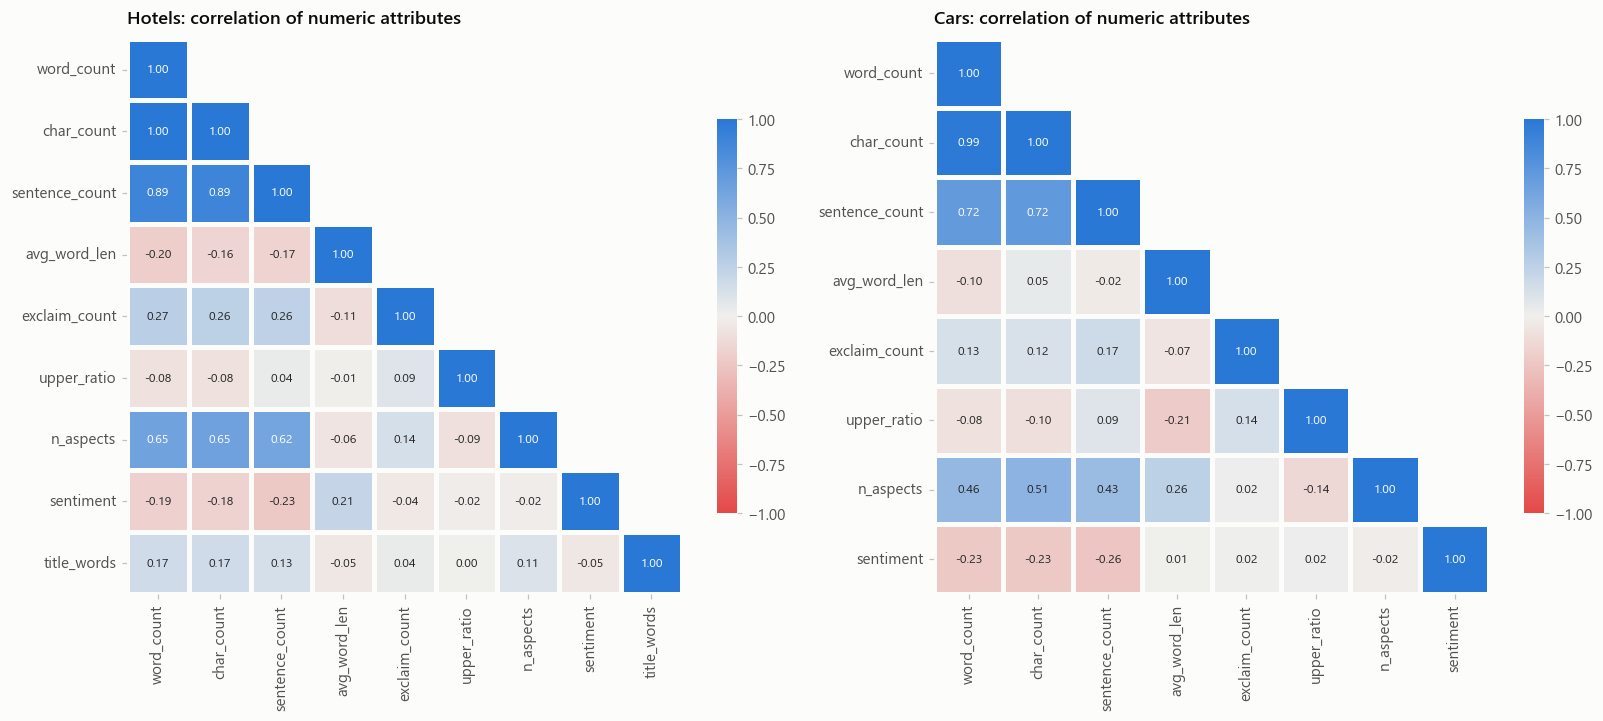

hotel pairs with |r| >= 0.5: [('word_count', 'char_count', np.float64(0.998)), ('word_count', 'sentence_count', np.float64(0.894)), ('char_count', 'sentence_count', np.float64(0.894)), ('char_count', 'n_aspects', np.float64(0.654)), ('word_count', 'n_aspects', np.float64(0.645)), ('sentence_count', 'n_aspects', np.float64(0.619))]
car pairs with |r| >= 0.5: [('word_count', 'char_count', np.float64(0.986)), ('char_count', 'sentence_count', np.float64(0.722)), ('word_count', 'sentence_count', np.float64(0.718)), ('char_count', 'n_aspects', np.float64(0.505))]


In [3]:
num = ["word_count", "char_count", "sentence_count", "avg_word_len", "exclaim_count", "upper_ratio",
       "n_aspects", "sentiment"]
corr_h = H[num + ["title_words"]].corr()
corr_c = C[num].corr()
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2))
P.corr_heatmap(axs[0], corr_h, "Hotels: correlation of numeric attributes")
P.corr_heatmap(axs[1], corr_c, "Cars: correlation of numeric attributes")
fig.tight_layout()
P.save(fig, "s11_heatmap_correlation")
plt.show()
for name, cm in [("hotel", corr_h), ("car", corr_c)]:
    pairs = [(a, b, round(cm.loc[a, b], 3)) for i, a in enumerate(cm.columns) for b in cm.columns[i + 1:]
             if abs(cm.loc[a, b]) >= 0.5]
    print(name, "pairs with |r| >= 0.5:", sorted(pairs, key=lambda x: -abs(x[2])))

**Inferences (correlation heatmap)**
* `word_count` and `char_count` are almost perfectly correlated (r ≈ 1.00 for hotels, 0.99 for
  cars). One is derivable from the other, so **`char_count` is dropped** (redundancy).
* `sentence_count` follows length closely (r ≈ 0.89 for hotels) but stays below the 0.9 cut-off,
  so it is kept. `n_aspects` rises with length (r ≈ 0.65): longer reviews cover more aspects.
* **Sentiment is not correlated with any style attribute** (|r| < 0.5): how long or how
  emphatic a review is says little about its polarity. Sentiment has to come from the words.

### 1c · Row selection: the long tail of hotels (Pareto chart, panel b)
Many hotels have only a handful of reviews. Per-hotel statistics (mean sentiment, aspect profile)
from fewer than 10 reviews are unreliable, so those hotels are left out of the per-entity
analyses. The Pareto chart shows how few hotels hold most of the reviews.

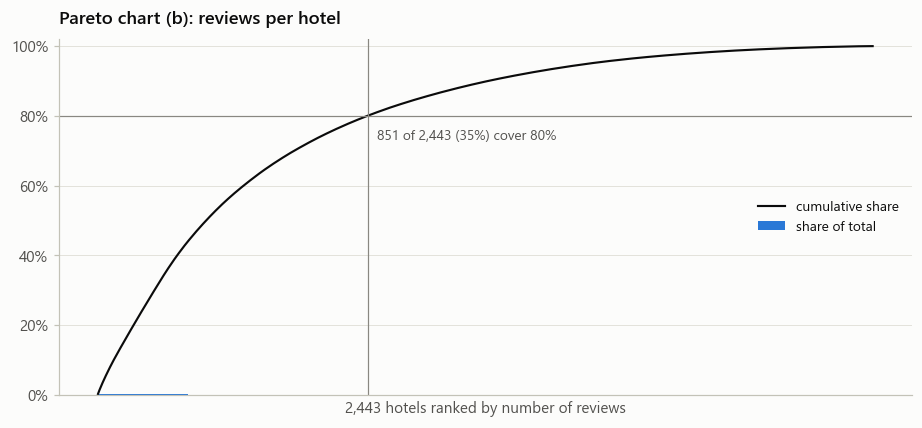

hotels: 2,443; 851 hotels (34.8%) hold 80% of the reviews
hotels with < 10 reviews: 374 (15.3% of hotels) holding 2,187 reviews (0.99% of hotel reviews)
reviews per hotel: {'count': 2443.0, 'mean': 90.3, 'std': 107.8, 'min': 1.0, '25%': 16.0, '50%': 44.0, '75%': 117.5, 'max': 576.0}


In [4]:
per_hotel = H.groupby(["city_name", "entity"]).size()
fig, ax = plt.subplots(figsize=(10, 4.2))
k80 = P.pareto(ax, per_hotel, "Pareto chart (b): reviews per hotel", P.DOMAIN["hotel"],
               xlabel=f"{len(per_hotel):,} hotels ranked by number of reviews")
P.save(fig, "p08b_pareto_reviews_per_hotel")
plt.show()
small = per_hotel[per_hotel < 10]
print(f"hotels: {len(per_hotel):,}; {k80} hotels ({k80 / len(per_hotel):.1%}) hold 80% of the reviews")
print(f"hotels with < 10 reviews: {len(small):,} ({len(small) / len(per_hotel):.1%} of hotels) "
      f"holding {small.sum():,} reviews ({small.sum() / len(H):.2%} of hotel reviews)")
print("reviews per hotel:", per_hotel.describe().round(1).to_dict())

**Inferences (Pareto chart b)**
* Reviews are concentrated: about **35 % of the hotels hold 80 % of all hotel reviews**. The
  median hotel has 44 reviews, the largest 576.
* About 15 % of hotels have fewer than 10 reviews, yet together they hold **under 1 %** of the
  reviews. Dropping them from per-hotel analyses loses almost no data and removes the noisiest
  per-hotel averages.

### 1d · Vocabulary selection: which aspects matter (Pareto chart, panel a)
Each review's aspects come from a 22-aspect hotel lexicon and a 19-aspect car lexicon. The Pareto
chart ranks the aspects by the share of all mentions and finds the "vital few" covering 80 %.
These shares also guide the minimum support used for Apriori in notebook 03.

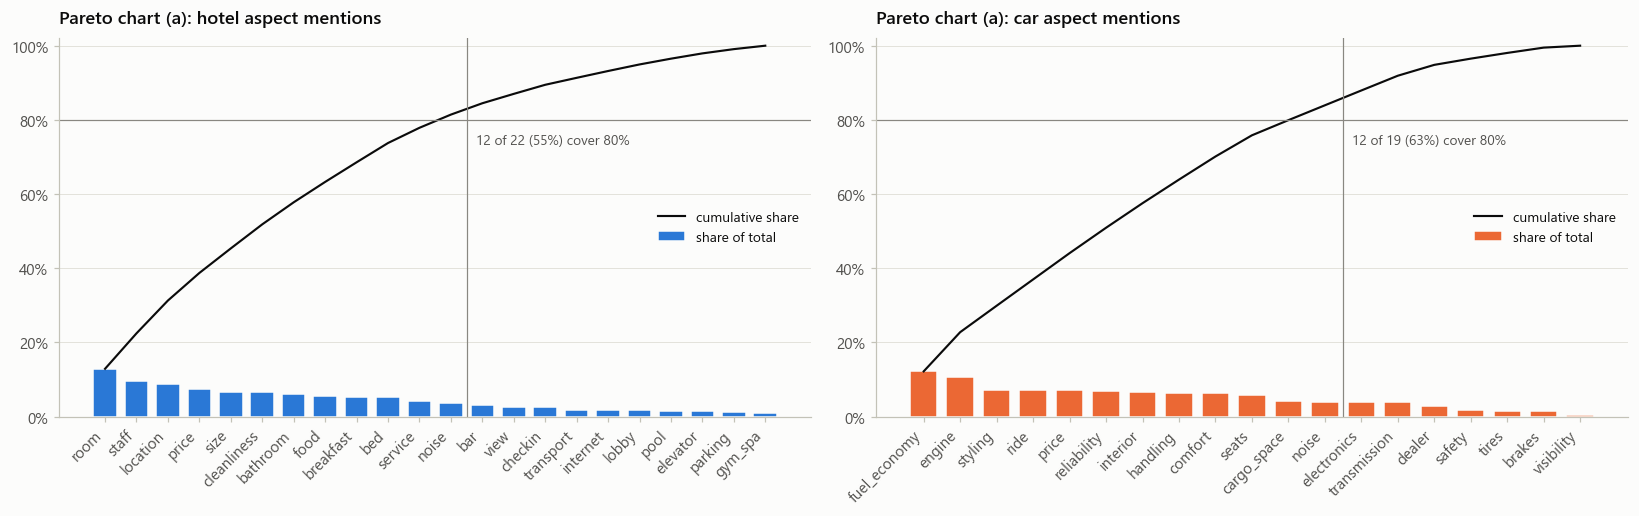

hotel: 12 of 22 aspects cover 80% of mentions; car: 12 of 19
        aspects  hotel % reviews       aspects  car % reviews
0          room             88.3  fuel_economy           46.1
1         staff             65.6        engine           40.0
2      location             60.7       styling           27.0
3         price             51.0          ride           26.9
4          size             45.4         price           26.8
5   cleanliness             44.5   reliability           25.9
6      bathroom             40.8      interior           25.1
7          food             37.7      handling           24.1
8     breakfast             36.3       comfort           23.6
9           bed             35.7         seats           21.6
10      service             28.2   cargo_space           15.5
11        noise             24.4         noise           15.2


In [5]:
asp_h = H["aspects"].explode().value_counts()
asp_c = C["aspects"].explode().value_counts()
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
k_h = P.pareto(axs[0], asp_h, "Pareto chart (a): hotel aspect mentions", P.DOMAIN["hotel"])
k_c = P.pareto(axs[1], asp_c, "Pareto chart (a): car aspect mentions", P.DOMAIN["car"])
fig.tight_layout()
P.save(fig, "p08a_pareto_aspects")
plt.show()
cov = pd.DataFrame({"hotel: % of reviews": (asp_h / len(H) * 100).round(1)}).head(12)
print(f"hotel: {k_h} of {len(asp_h)} aspects cover 80% of mentions; car: {k_c} of {len(asp_c)}")
print(pd.concat([(asp_h / len(H) * 100).round(1).rename("hotel % reviews").reset_index(),
                 (asp_c / len(C) * 100).round(1).rename("car % reviews").reset_index()], axis=1).head(12).to_string())

**Inferences (Pareto chart a)**
* Hotel reviews revolve around a few aspects. *room* appears in ~88 % of reviews, *staff* in
  ~66 % and *location* in ~61 %, and 12 of the 22 aspects cover 80 % of all mentions.
* Car reviews are less concentrated. The leaders are *fuel economy* (~46 %) and *engine*
  (~40 %), then a flat plateau (styling, ride, price, reliability, interior at 24–27 %).
  Again 12 of 19 aspects reach 80 %.
* Because the top aspects are so frequent, Apriori's minimum support must be fairly high
  (5 % for hotels) to avoid an explosion of itemsets. Cars, with lower aspect frequencies, need
  a lower one (2 %).

## 2 · Data transformation (part 2)
### 2a · Normalisation
* min-max: v' = (v − min) / (max − min), maps to [0, 1]
* z-score: v' = (v − μ) / σ
* decimal scaling: v' = v / 10^j, where j is the smallest integer with max |v'| < 1

All three are applied to `word_count` per domain, because the two domains have different
length scales. Sentiment is already on [−1, 1].

In [6]:
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())


def zscore(s):
    return (s - s.mean()) / s.std()


def decimal_scale(s):
    j = int(np.ceil(np.log10(s.abs().max() + 1)))
    return s / 10 ** j, j


df["wc_minmax"] = df.groupby("domain")["word_count"].transform(minmax).round(4)
df["wc_z"] = df.groupby("domain")["word_count"].transform(zscore).round(3)
ds, j = decimal_scale(df.loc[df["domain"] == "hotel", "word_count"])
print(f"decimal scaling (hotels): max |v| = {df.loc[df['domain'] == 'hotel', 'word_count'].max()}, j = {j}")
print(df.loc[df["domain"] == "hotel", ["word_count", "wc_minmax", "wc_z"]].sample(6, random_state=1)
      .assign(wc_decimal=lambda d: d["word_count"] / 10 ** j).to_string())

decimal scaling (hotels): max |v| = 3885, j = 4
        word_count  wc_minmax   wc_z  wc_decimal
120797         139     0.0345 -0.311      0.0139
200257         211     0.0531  0.173      0.0211
79642           30     0.0064 -1.044      0.0030
57379           67     0.0160 -0.795      0.0067
103536          82     0.0198 -0.694      0.0082
152155         140     0.0348 -0.304      0.0140


### 2b · Discretisation and concept hierarchies
* sentiment (continuous) → `sent_class` ∈ {neg, neu, pos}, with VADER's ±0.05 cut-offs
* length → `len_class` ∈ {short, medium, long}: **equal-depth** (`qcut`) tertiles per domain
* date → day < month < quarter < year (concept-hierarchy climbing)
* cars: make > model > model year; hotels: city > hotel

In [7]:
df["len_class"] = df.groupby("domain")["word_count"].transform(
    lambda s: pd.qcut(s, 3, labels=["short", "medium", "long"])).astype(str)
print(df.groupby(["domain", "len_class"])["word_count"].agg(["min", "max", "size"]))
print("\nconcept hierarchy on date, roll-up to year and quarter (hotel reviews):")
print(df[df["domain"] == "hotel"].groupby(["year", "quarter"]).size().unstack(fill_value=0))

                  min   max   size
domain len_class                  
car    long       114   187  13515
       medium      71   113  13530
       short        5    70  13800
hotel  long       198  3885  73379
       medium     110   197  72696
       short        5   109  74410

concept hierarchy on date, roll-up to year and quarter (hotel reviews):


quarter      1      2      3      4
year                               
2001         0      0      0      1
2002        11      9     17     33
2003        47    142    418    840
2004      1539   2263   3230   3453
2005      3917   4794   5310   4905
2006      5270   6230   6776   6843
2007      7529   8802  10930  10288
2008     11062  12159  13798  12210
2009     13772  20081  25215  17038


## 3 · The ten course plots
### Plot 1 · Pie chart: hotel reviews by city

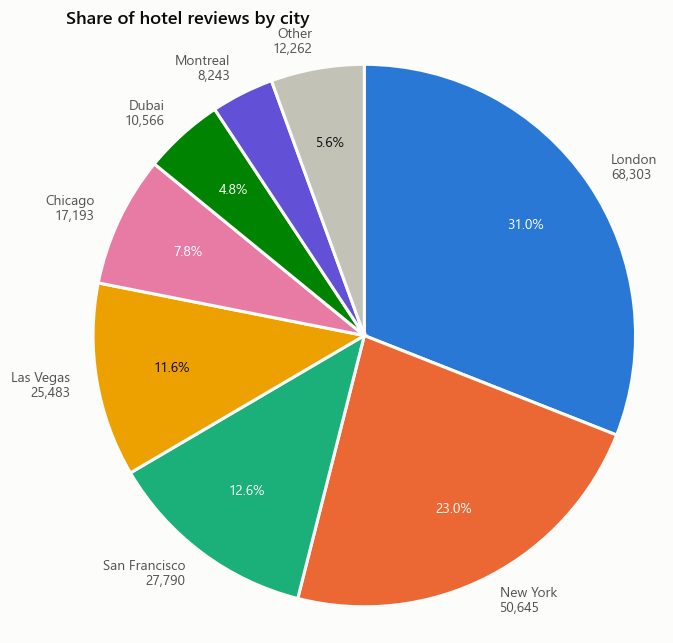

city_name
London           31.0
New York         23.0
San Francisco    12.6
Las Vegas        11.6
Chicago           7.8
Dubai             4.8
Montreal          3.7
Beijing           2.0
New Delhi         2.0
Shanghai          1.5


In [8]:
city_counts = H["city_name"].value_counts()
fig, ax = plt.subplots(figsize=(7, 7))
P.pie(ax, city_counts, "Share of hotel reviews by city", palette=CITY_COLORS)
P.save(fig, "p01_pie_city")
plt.show()
print((city_counts / city_counts.sum() * 100).round(1).to_string())

**Inferences (pie chart)**
* The data is strongly **imbalanced across cities**: London (~31 %) and New York (~23 %)
  together supply over half of all hotel reviews.
* The three Asian cities (Beijing, New Delhi, Shanghai) together contribute only ~5.5 %. Their
  statistics rest on far fewer reviews, so cities must be compared with **proportions**, not
  raw counts.
* The three smallest cities are folded into "Other" (the palette caps distinct colours at 8);
  their exact shares are in the table above. A pie shows the overall split well but hides small
  differences, a known limitation of pie charts.

### Plot 2 · Doughnut chart: sentiment mix, hotels vs cars

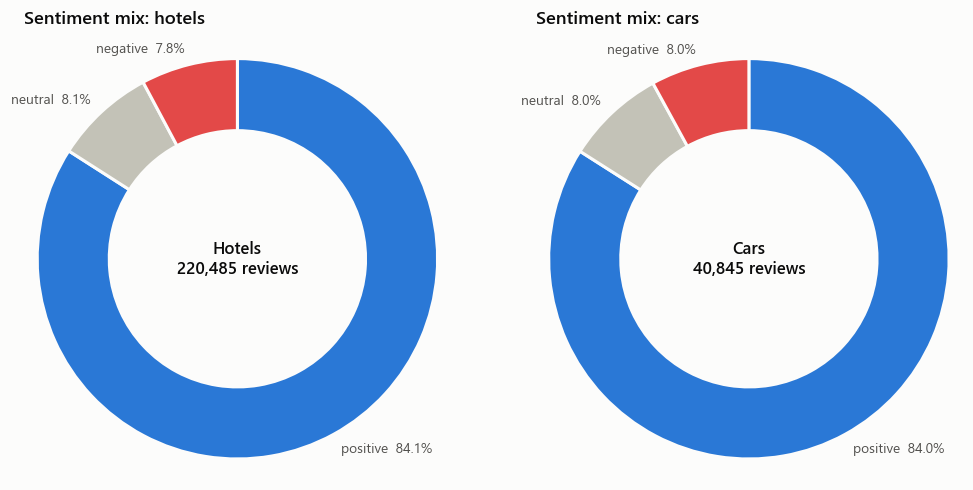

sent_class  neg  neu   pos
domain                    
car         8.0  8.0  84.0
hotel       7.8  8.1  84.1


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (dom, sub) in zip(axs, [("Hotels", H), ("Cars", C)]):
    sc = sub["sent_class"].value_counts().reindex(["pos", "neu", "neg"])
    P.doughnut(ax, sc.rename({"pos": "positive", "neu": "neutral", "neg": "negative"}),
               f"Sentiment mix: {dom.lower()}", [P.SENT[k] for k in sc.index], f"{dom}\n{len(sub):,} reviews")
P.save(fig, "p02_doughnut_sentiment")
plt.show()
print(pd.crosstab(df["domain"], df["sent_class"], normalize="index").mul(100).round(1))

**Inferences (doughnut chart)**
* Both sources are overwhelmingly positive: **~84 % positive** reviews, with only ~8 %
  negative and ~8 % neutral. This is the familiar positivity bias of online reviews.
* Car and hotel reviewers have an almost identical sentiment mix, even though the products and
  websites differ.
* The negative class is a small minority. Any rule or pattern that predicts negative reviews
  will have low support, which shapes the ARM parameter choices in notebook 03.

### Plot 3 · Histogram: review length

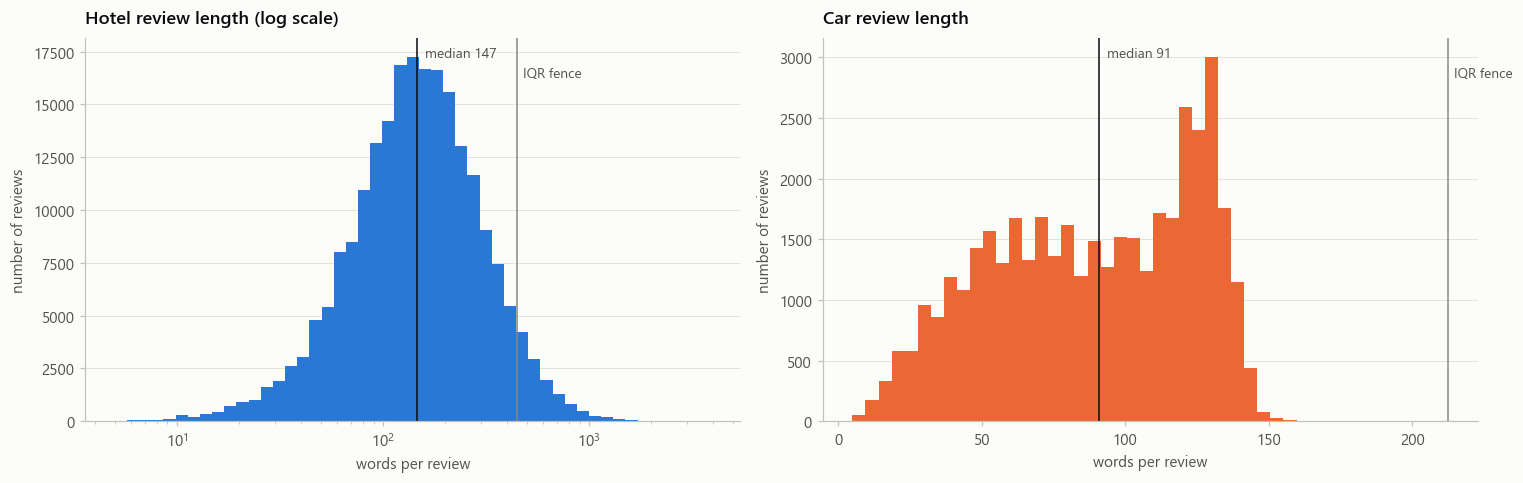

           count   mean    std  min   25%    50%    75%    95%    99%     max
domain                                                                       
car      40845.0   88.6   35.0  5.0  60.0   91.0  121.0  136.0  143.0   187.0
hotel   220485.0  185.2  148.7  5.0  91.0  147.0  233.0  460.0  740.0  3885.0
skewness: {'car': -0.27, 'hotel': 2.93}  IQR fences: {'car': 212, 'hotel': 446}


In [10]:
fence = {d: g["word_count"].quantile(0.75) + 1.5 * (g["word_count"].quantile(0.75) - g["word_count"].quantile(0.25))
         for d, g in df.groupby("domain")}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
P.histogram(axs[0], H["word_count"], "Hotel review length (log scale)", P.DOMAIN["hotel"], "words per review",
            bins=50, logx=True)
P.histogram(axs[1], C["word_count"], "Car review length", P.DOMAIN["car"], "words per review", bins=40)
for ax, d in zip(axs, ["hotel", "car"]):
    ax.axvline(fence[d], color=P.MUTED, lw=1)
    ax.annotate("IQR fence", xy=(fence[d], 0.9), xycoords=("data", "axes fraction"), xytext=(4, 0),
                textcoords="offset points", color=P.INK2, fontsize=9)
fig.tight_layout()
P.save(fig, "p03_histogram_length")
plt.show()
print(df.groupby("domain")["word_count"].describe(percentiles=[.25, .5, .75, .95, .99]).round(1))
print("skewness:", df.groupby("domain")["word_count"].skew().round(2).to_dict(), " IQR fences:", {k: round(v) for k, v in fence.items()})

**Inferences (histograms)**
* **Hotel reviews are strongly right-skewed** (skewness ≈ 2.9). Median ≈ 147 words, mean ≈ 185,
  and a long tail up to several thousand words. On the log axis the distribution looks roughly
  normal, i.e. the lengths are approximately log-normal. About 5 % lie beyond the IQR fence
  (≈ 446 words).
* **Car reviews behave quite differently**: median ≈ 91 words, nothing above ≈ 190 words, and
  a slight *left* skew (−0.3). The hard ceiling and the pile-up just below it suggest the
  Edmunds form limited review length.
* The two sources therefore need separate (per-domain) normalisation and binning. That is why
  `wc_minmax`, `wc_z` and `len_class` are computed per domain.

### Plot 4 · Dot plot: models reviewed per car make

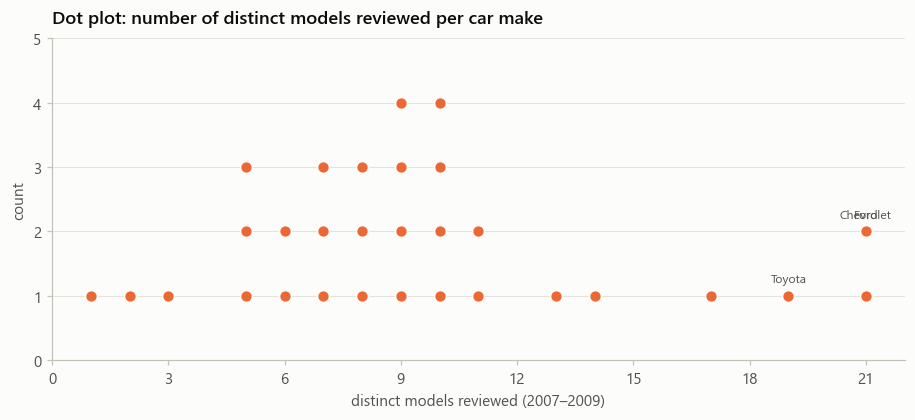

make
Smart             1
Mini              2
Scion             3
Acura             5
Suzuki            5
Buick             5
Jeep              6
Subaru            6
Infiniti          7
Chrysler          7
Saturn            7
Pontiac           8
Mitsubishi        8
Cadillac          8
Honda             9
GMC               9
Volvo             9
Kia               9
Mazda            10
Mercedes-Benz    10
Lexus            10
BMW              10
Audi             11
Hyundai          11
Volkswagen       13
Dodge            14
Nissan           17
Toyota           19
Ford             21
Chevrolet        21
median: 9.0  mean: 9.37


In [11]:
models_per_make = C.groupby("make")["model"].nunique().sort_values()
fig, ax = plt.subplots(figsize=(10, 3.8))
P.dot_plot(ax, models_per_make.values, "Dot plot: number of distinct models reviewed per car make",
           P.DOMAIN["car"], "distinct models reviewed (2007–2009)")
top = models_per_make.tail(3)
for m, v in top.items():
    ax.annotate(m, xy=(v, (models_per_make == v).sum()), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=8, color=P.INK2)
P.save(fig, "p04_dotplot_models_per_make")
plt.show()
print(models_per_make.to_string())
print("median:", models_per_make.median(), " mean:", round(models_per_make.mean(), 2))

**Inferences (dot plot)**
* Most makes have between 5 and 14 models reviewed (median 9). The distribution is moderately
  right-skewed, with three high outliers: **Chevrolet and Ford (21 models each) and Toyota (19)**.
* The niche brands sit at the low end: Smart (1), Mini (2), Scion (3).
* Each dot is one make, so the individual values stay visible. With only 30 values, a dot plot
  shows more than a histogram would for small data.

### Plot 5 · Stem-and-leaf: reviews per car model-year file for one make (Honda)

In [12]:
honda = C[C["make"] == "Honda"].groupby(["model_year", "model"]).size()
stem = P.stem_and_leaf(honda.values)
print(stem)
fig = P.text_figure(stem, f"Stem-and-leaf: reviews per Honda model and model year ({len(honda)} values)")
P.save(fig, "p05_stem_leaf_honda")
plt.show()
print(honda.sort_values(ascending=False).to_string())

0 | 1 1 2 6 6 6 6 8
1 | 0 1 1 3 5 6 7 9
2 | 1 2 2 7 9
3 | 5
4 | 3 3

Key: 1 | 2 = 120   (leaf unit 10; values truncated)


<Figure size 825x276.1 with 0 Axes>

model_year  model    
2008.0      civic        436
2007.0      civic        430
            fit          358
            cr-v         299
            accord       276
2008.0      cr-v         228
2009.0      accord       224
2007.0      odyssey      211
2009.0      fit          194
            civic        171
2008.0      fit          161
2009.0      pilot        155
2007.0      pilot        135
2008.0      odyssey      118
2009.0      cr-v         113
2007.0      ridgeline    107
2008.0      ridgeline     85
2007.0      element       67
2008.0      pilot         66
            element       62
2009.0      odyssey       60
2007.0      s2000         29
2009.0      ridgeline     18
2008.0      s2000         12


**Inferences (stem-and-leaf)**
* The 24 Honda model-year files range from about 10 to 440 reviews. Two thirds sit on the
  first two stems (fewer than 200 reviews).
* The display keeps the actual values, so the **outliers** are easy to name: the Civic
  (2007: 430, 2008: 436) collects about twice the reviews of any other Honda. The S2000 sports
  car is at the bottom (12–29).
* The shape is right-skewed: a few blockbuster models and many modestly reviewed ones. That is
  the same long-tail pattern the Pareto chart shows for hotels.

### Plot 6 · Scatter plot: popularity vs mean sentiment

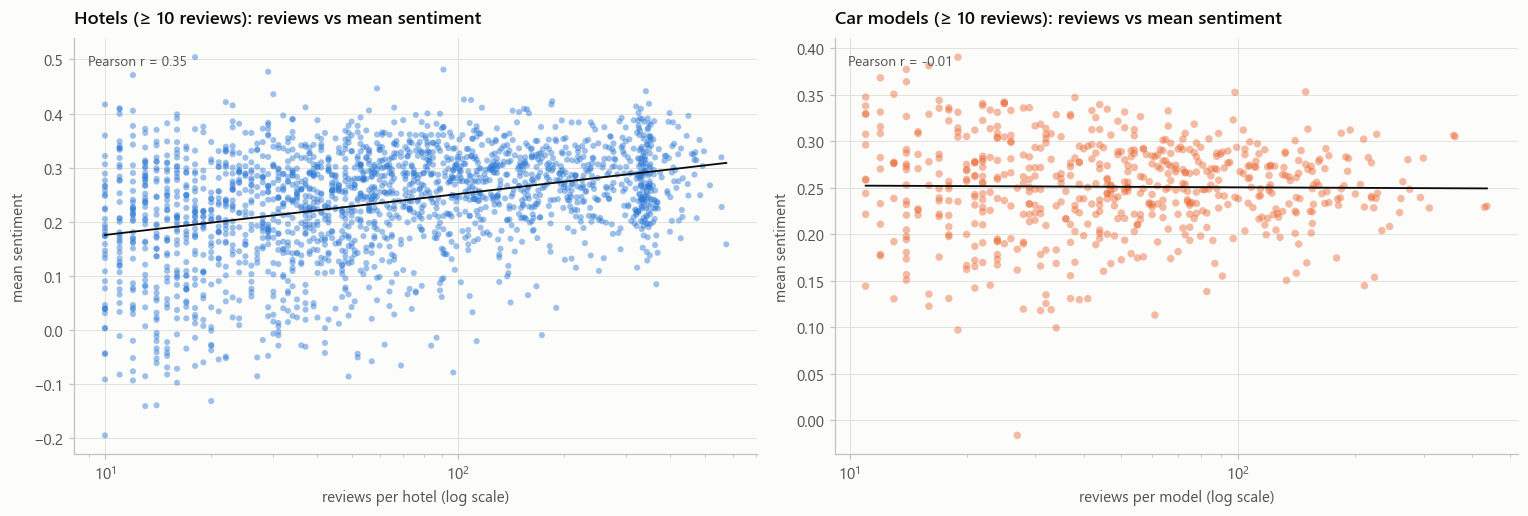

hotels: n = 2069, r = 0.348;  car models: n = 596, r = -0.013
lowest-rated hotels:
                               n      s
city_name entity                      
London    Abbey Lodge Hotel  10 -0.195
          Warwick Hotel      13 -0.141
          Berkeley Court     14 -0.139
highest-rated hotels:
                                        n      s
city_name entity                               
New Delhi Amarya Garden               18  0.504
          Hotel Raunak International  91  0.481
London    Church Street Hotel         29  0.477


In [13]:
ph = H.groupby(["city_name", "entity"]).agg(n=("sentiment", "size"), s=("sentiment", "mean"))
ph = ph[ph["n"] >= 10]
pc = C.groupby(["model_year", "entity"]).agg(n=("sentiment", "size"), s=("sentiment", "mean"))
pc = pc[pc["n"] >= 10]
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
r_h = P.scatter(axs[0], ph["n"], ph["s"], "Hotels (≥ 10 reviews): reviews vs mean sentiment",
                "reviews per hotel (log scale)", "mean sentiment", P.DOMAIN["hotel"], logx=True)
r_c = P.scatter(axs[1], pc["n"], pc["s"], "Car models (≥ 10 reviews): reviews vs mean sentiment",
                "reviews per model (log scale)", "mean sentiment", P.DOMAIN["car"], logx=True, s=24)
fig.tight_layout()
P.save(fig, "p06_scatter_popularity_sentiment")
plt.show()
print(f"hotels: n = {len(ph)}, r = {r_h:.3f};  car models: n = {len(pc)}, r = {r_c:.3f}")
print("lowest-rated hotels:\n", ph.nsmallest(3, "s").round(3).to_string())
print("highest-rated hotels:\n", ph.nlargest(3, "s").round(3).to_string())

**Inferences (scatter plots)**
* For hotels there is a **moderate positive relationship** (r ≈ 0.35) between how many reviews
  a hotel has (log scale) and how positive they are on average. Popular hotels tend to be
  liked. Correlation is not causation: good hotels may attract more guests, or many reviews may
  average out extreme opinions.
* The spread **narrows as the review count grows**: mean sentiment is noisy for hotels with
  10–30 reviews and stable for hotels with hundreds. This is another reason to drop
  small-sample entities.
* For car models there is **no relationship** (r ≈ 0). A model's popularity on Edmunds says
  nothing about how positive its reviews are.

### Plot 7 · Box plots: sentiment by city, length by car model year

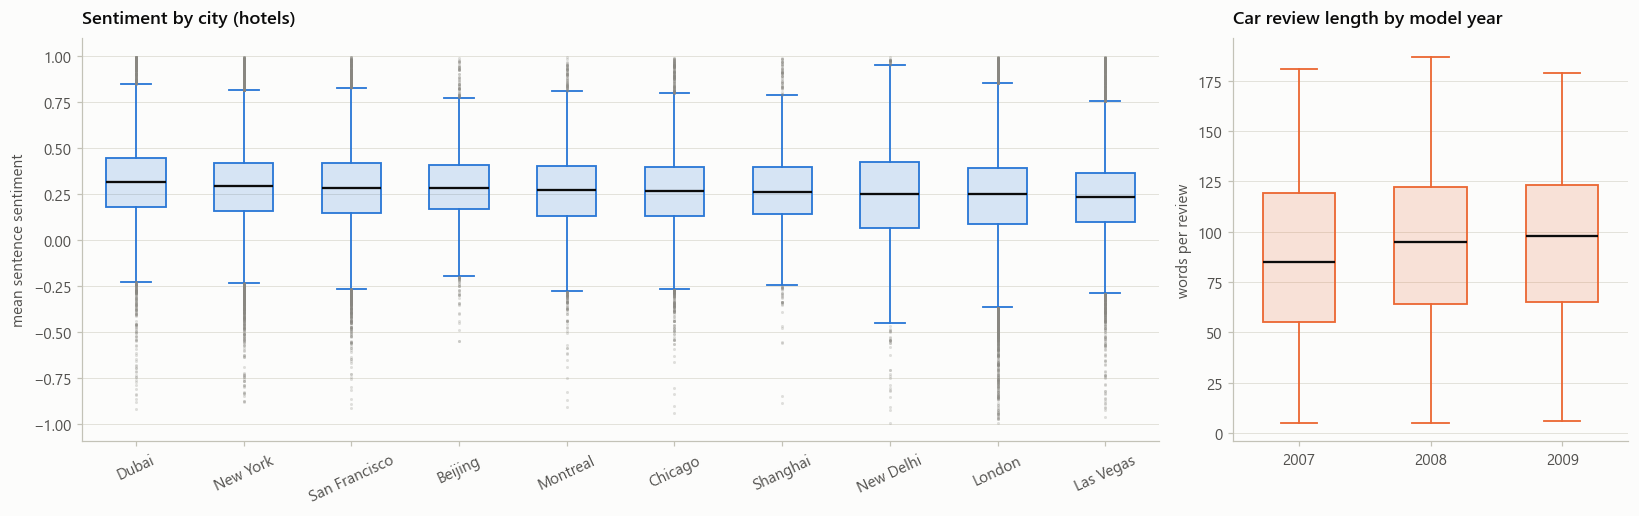

                 min    25%    50%    75%    max    IQR
city_name                                              
Dubai         -0.916  0.179  0.314  0.448  0.998  0.269
New York      -0.881  0.160  0.293  0.422  0.998  0.262
San Francisco -0.911  0.147  0.286  0.420  0.998  0.274
Beijing       -0.550  0.168  0.283  0.411  0.992  0.243
Montreal      -0.907  0.130  0.275  0.402  0.998  0.272
Chicago       -0.941  0.133  0.268  0.399  0.992  0.267
Shanghai      -0.884  0.141  0.265  0.401  0.992  0.260
New Delhi     -0.993  0.069  0.253  0.423  0.996  0.354
London        -0.992  0.091  0.249  0.396  0.996  0.305
Las Vegas     -0.959  0.102  0.234  0.364  0.999  0.262
             25%   50%    75%
model_year                   
2007.0      55.0  85.0  119.0
2008.0      64.0  95.0  122.0
2009.0      65.0  98.0  123.0


In [14]:
order = H.groupby("city_name")["sentiment"].median().sort_values(ascending=False).index
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 1.1]})
P.boxplot(axs[0], {c: H.loc[H["city_name"] == c, "sentiment"].values for c in order},
          "Sentiment by city (hotels)", P.DOMAIN["hotel"], "mean sentence sentiment")
axs[0].tick_params(axis="x", rotation=25)
P.boxplot(axs[1], {str(y): C.loc[C["model_year"] == y, "word_count"].values for y in [2007, 2008, 2009]},
          "Car review length by model year", P.DOMAIN["car"], "words per review")
fig.tight_layout()
P.save(fig, "p07_boxplot_sentiment_city")
plt.show()
five = H.groupby("city_name")["sentiment"].describe()[["min", "25%", "50%", "75%", "max"]]
five["IQR"] = five["75%"] - five["25%"]
print(five.loc[order].round(3).to_string())
print(C.groupby("model_year")["word_count"].describe()[["25%", "50%", "75%"]].to_string())

**Inferences (box plots), using the box-plot comparison rules**
* Median sentiment ranges from ≈ 0.31 (Dubai) down to ≈ 0.23 (Las Vegas). Every box overlaps
  every other and each median lies inside the others' boxes, so by the comparison rule **no city
  can be called clearly different**. The differences are real but small.
* **New Delhi has the tallest box** (IQR ≈ 0.35 vs ≈ 0.26 elsewhere): its reviews are the most
  polarised. London and Las Vegas sit lowest.
* Every city has a long lower tail of outliers down to about −0.99: a small number of very
  negative reviews, against a body that is mildly positive.
* Car reviews got slightly longer with newer model years (median 85 → 95 → 98 words) while
  keeping the same spread.

### Plot 8 · Pareto chart
Shown in the data-selection section: (a) aspect mentions, which drive the vocabulary
selection; (b) reviews per hotel, which drives the row filter.

### Plot 9 · Radar chart: aspect emphasis of the three largest cities and makes
Each axis is an **index** = (share of the group's reviews that mention the aspect) ÷ (share
across the whole domain). 1.0 is the domain average, drawn as the black ring. Indexing puts axes
with very different base rates (room vs view) on one comparable scale.

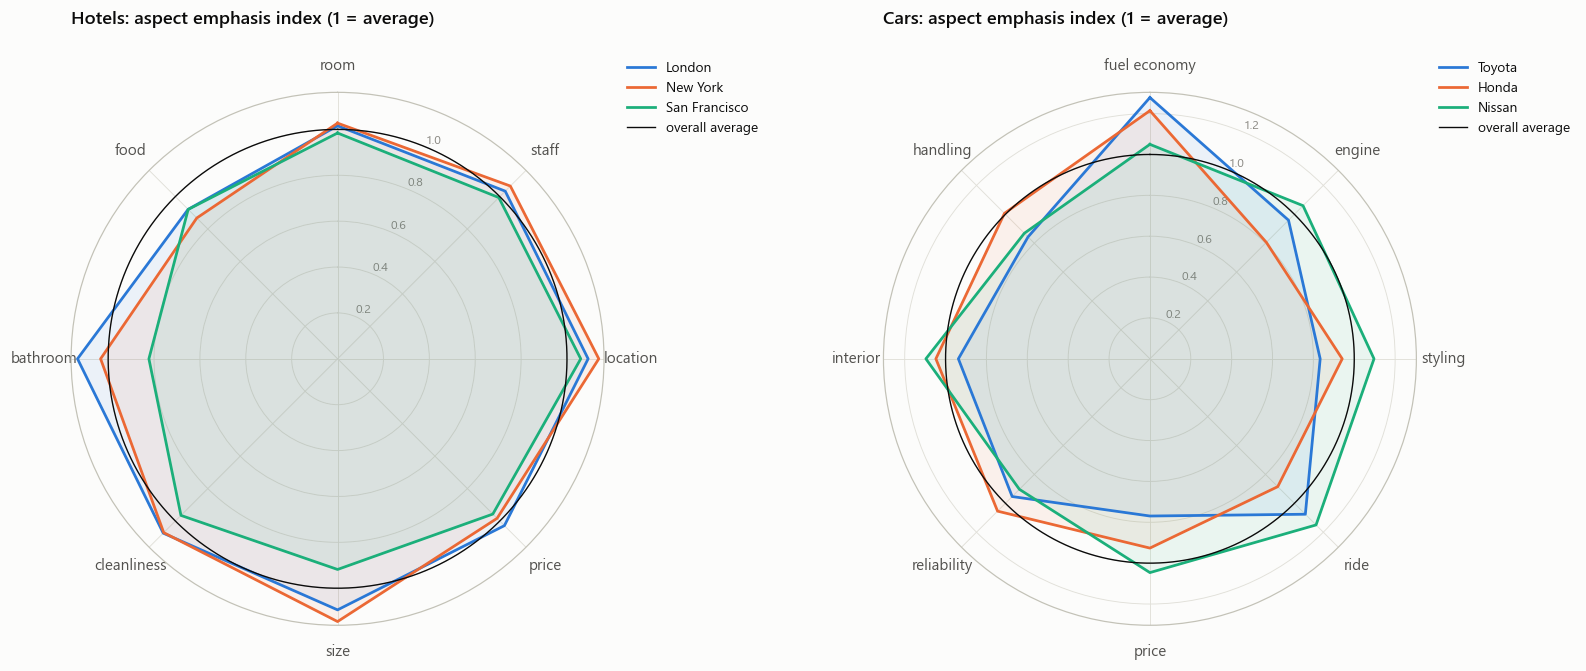

aspects        room  staff  location  price  size  cleanliness  bathroom  food
city_name                                                                     
London         1.02   1.03      1.09   1.03  1.09         1.07      1.13  0.92
New York       1.03   1.07      1.14   0.98  1.15         1.07      1.03  0.87
San Francisco  0.98   0.99      1.06   0.96  0.92         0.97      0.82  0.92
aspects  fuel economy  engine  styling  ride  price  reliability  interior  handling
make                                                                                
Toyota           1.28    0.96     0.83  1.08   0.77         0.95      0.94      0.84
Honda            1.21    0.81     0.94  0.88   0.93         1.05      1.05      1.01
Nissan           1.05    1.06     1.10  1.15   1.05         0.90      1.10      0.87


In [15]:
def emphasis(sub, by, groups, aspects):
    ex = sub[[by, "aspects"]].explode("aspects").reset_index(drop=True)   # one row per mention
    ct = pd.crosstab(ex[by], ex["aspects"])[aspects]
    rate = ct.div(sub[by].value_counts(), axis=0)
    overall = ct.sum() / len(sub)
    return (rate.loc[groups] / overall).rename(columns=lambda a: a.replace("_", " "))


top_cities = city_counts.index[:3]
top_makes = C["make"].value_counts().index[:3]
rad_h = emphasis(H, "city_name", top_cities, list(asp_h.index[:8]))
rad_c = emphasis(C, "make", top_makes, list(asp_c.index[:8]))
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2), subplot_kw={"projection": "polar"})
P.radar(axs[0], rad_h, "Hotels: aspect emphasis index (1 = average)")
P.radar(axs[1], rad_c, "Cars: aspect emphasis index (1 = average)")
fig.tight_layout()
P.save(fig, "p09_radar_aspect_emphasis")
plt.show()
print(rad_h.round(2).to_string())
print(rad_c.round(2).to_string())

**Inferences (radar charts)**
* **London** reviewers over-mention *bathroom* (index ≈ 1.13), *location* and *room size*
  (≈ 1.09). **New York** reviewers stress *size* (≈ 1.15) and *location* (≈ 1.14), consistent
  with small rooms in dense city centres. **San Francisco** reviews mention bathrooms (≈ 0.82)
  and size (≈ 0.92) *less* than average.
* Among cars, **Toyota (≈ 1.28) and Honda (≈ 1.21) reviews are dominated by fuel economy**,
  while **Nissan** reviews lean towards *ride* (≈ 1.15), *styling* and *interior* (≈ 1.10).
  Toyota reviewers mention *price* least (≈ 0.77).
* Indexing against the domain average puts all axes on one scale. Without it, the radar would
  only repeat the Pareto ranking (room ≫ everything else).

### Plot 10 · Stacked area chart: review volume over time

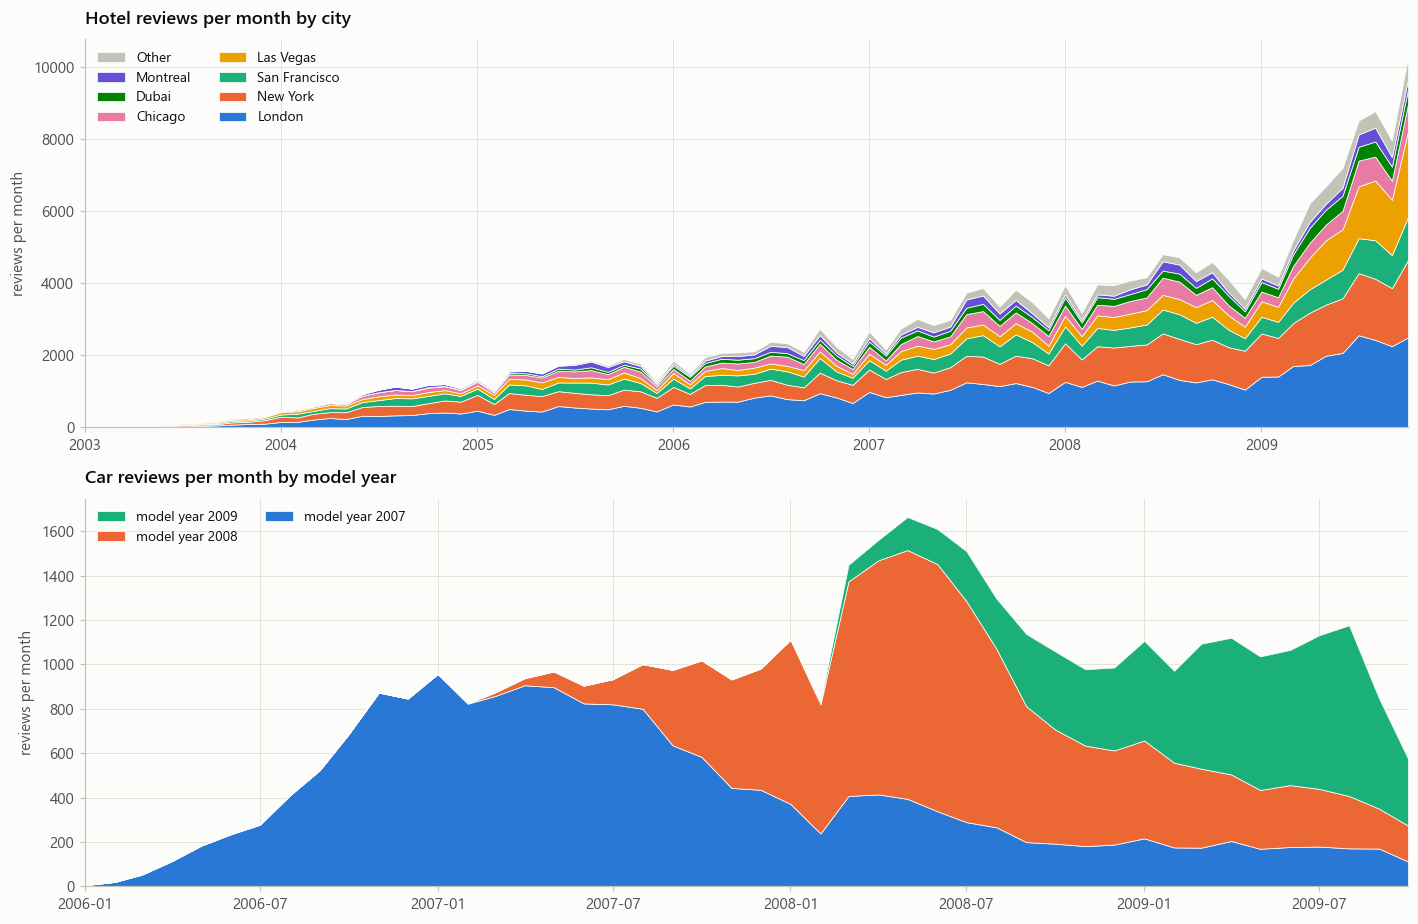

hotel reviews per year: {np.int64(2001): 1, np.int64(2002): 70, np.int64(2003): 1447, np.int64(2004): 10485, np.int64(2005): 18926, np.int64(2006): 25119, np.int64(2007): 37549, np.int64(2008): 49229, np.int64(2009): 76106}  growth 2005->2008: 2.6
busiest hotel months (all years): {np.int64(10): 24695, np.int64(8): 22774, np.int64(7): 22302, np.int64(9): 20618}
car reviews by (review year x model year):
 model_year  2007.0  2008.0  2009.0
year                              
2006          4228       0       0
2007          8980    2324       0
2008          3477    9383    2332
2009          1747    2861    5513


In [16]:
mh = H.dropna(subset=["date"]).assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
ts_h = mh.groupby(["month", "city_name"]).size().unstack(fill_value=0).loc["2003-01-01":"2009-10-31"]
mc = C.dropna(subset=["date"]).assign(month=lambda d: d["date"].dt.to_period("M").dt.to_timestamp())
ts_c = mc.groupby(["month", "model_year"]).size().unstack(fill_value=0)
ts_c.columns = [f"model year {int(c)}" for c in ts_c.columns]
fig, axs = plt.subplots(2, 1, figsize=(13, 8.5))
P.stacked_area(axs[0], ts_h, "Hotel reviews per month by city", palette=CITY_COLORS)
P.stacked_area(axs[1], ts_c, "Car reviews per month by model year")
fig.tight_layout()
P.save(fig, "p10_area_reviews_over_time")
plt.show()
yearly = H.groupby("year").size()
print("hotel reviews per year:", yearly.to_dict(), " growth 2005->2008:", round(yearly[2008] / yearly[2005], 2))
print("busiest hotel months (all years):", H.groupby("month").size().sort_values(ascending=False).head(4).to_dict())
print("car reviews by (review year x model year):\n", pd.crosstab(C["year"], C["model_year"]))

**Inferences (stacked area charts)**
* Hotel review volume **grows steadily from 2003 to 2009**: 2.6× between 2005 and 2008, and
  2009 alone has ~76k reviews. The data captures the rise of TripAdvisor more than any change in
  travel.
* There is a clear **seasonal cycle**: July–October are the busiest months (summer travel),
  with a dip each winter. London and New York form the base of the stack throughout; Las Vegas
  grows strongly in 2009.
* Car reviews show a **product life-cycle**. Each model year's reviews start about a year
  before the model year (MY2007 from early 2006), peak around launch, then decay as the next
  model year takes over.

## 4 · Supporting plots
### Plot 11 · Correlation heatmap: shown in section 1b (redundancy check)
### Plot 12 · Bar charts: reviews per car make; what cleaning removed or repaired

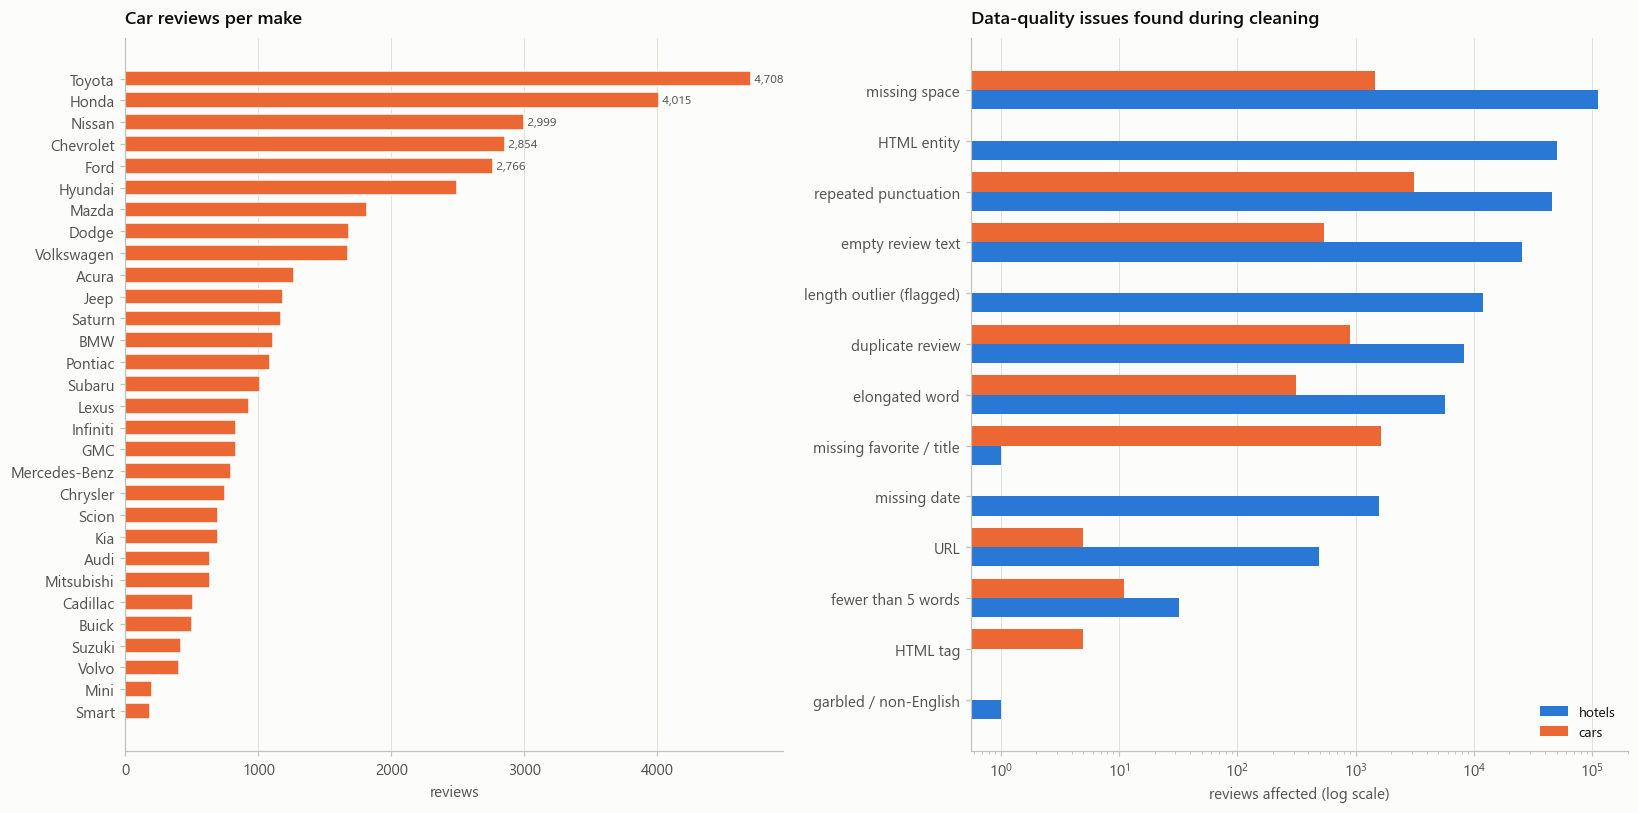

domain                     car   hotel
issue                                 
garbled / non-English        0       1
HTML tag                     5       0
fewer than 5 words          11      32
URL                          5     487
missing date                 0    1587
missing favorite / title  1639       1
elongated word             314    5749
duplicate review           892    8266
length outlier (flagged)     0   12040
empty review text          540   25789
repeated punctuation      3109   45672
HTML entity                  0   50213
missing space             1451  112400


In [17]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7.5))
P.hbar(axs[0], C["make"].value_counts(), "Car reviews per make", P.DOMAIN["car"], "reviews")
nc = (pd.read_csv(TABLES / "noise_counts.csv")
      .pivot_table(index="issue", columns="domain", values="count", aggfunc="sum", fill_value=0))
nc = nc[nc.sum(axis=1) > 0]
nc = nc.loc[nc.sum(axis=1).sort_values().index]
y = np.arange(len(nc))
axs[1].barh(y - 0.19, nc.get("hotel", 0), 0.38, color=P.DOMAIN["hotel"], label="hotels")
axs[1].barh(y + 0.19, nc.get("car", 0), 0.38, color=P.DOMAIN["car"], label="cars")
axs[1].set_yticks(y)
axs[1].set_yticklabels(nc.index)
axs[1].set_xscale("log")
axs[1].set_xlabel("reviews affected (log scale)")
axs[1].set_title("Data-quality issues found during cleaning")
axs[1].legend(loc="lower right")
axs[1].grid(axis="y", visible=False)
fig.tight_layout()
P.save(fig, "s12_bar_makes_and_cleaning")
plt.show()
print(nc.to_string())

**Inferences (bar charts)**
* Five makes (Toyota, Honda, Nissan, Chevrolet, Ford) supply about 42 % of all car reviews.
  Toyota alone has ~4.7k.
* The most common quality problems were **cosmetic but massive**: about half of all hotel
  reviews had missing spaces where lines were joined, and ~50k had HTML entities. Both were
  repaired, not dropped.
* The rows actually **removed** came mainly from empty texts (~26k) and duplicates (~9k).
  Language and length filters removed only a few dozen rows, so the cleaned data keeps
  ~88 % of the raw records.

### Plot 13 · Line chart: mean sentiment per month

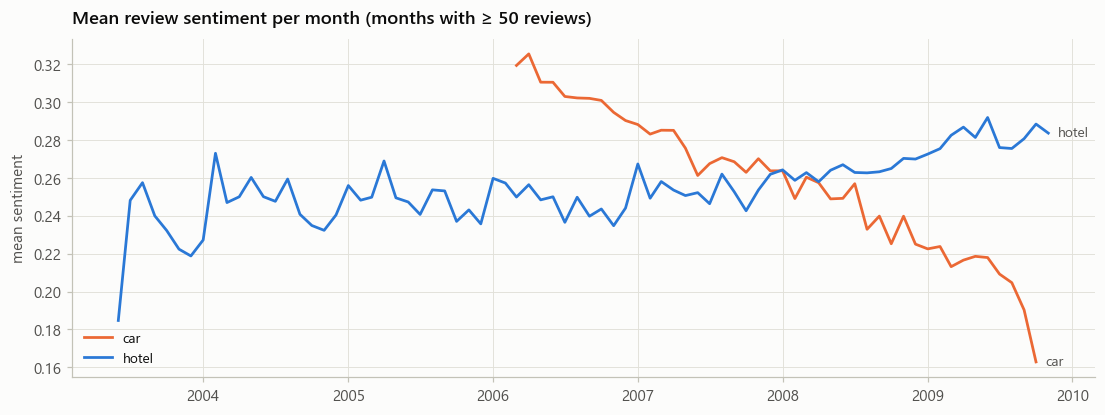

domain    car  hotel
year                
2001      NaN  0.422
2002      NaN  0.164
2003      NaN  0.227
2004      NaN  0.246
2005      NaN  0.248
2006    0.300  0.247
2007    0.273  0.254
2008    0.247  0.264
2009    0.210  0.282


In [18]:
sm = pd.concat([mh.assign(d="hotel"), mc.assign(d="car")]).groupby(["month", "d"])["sentiment"].agg(["mean", "size"])
sm = sm[sm["size"] >= 50]["mean"].unstack()
fig, ax = plt.subplots(figsize=(12, 4))
P.lines(ax, sm.loc["2003-01-01":], "Mean review sentiment per month (months with ≥ 50 reviews)", "mean sentiment",
        colors=P.DOMAIN)
P.save(fig, "s13_line_sentiment_trend")
plt.show()
print(df.groupby(["domain", "year"])["sentiment"].mean().unstack(0).round(3))

**Inferences (line chart)**
* Hotel sentiment drifts slowly **upwards** (yearly mean ≈ 0.25 in 2004–06 → ≈ 0.28 in 2009).
* Car sentiment drifts **downwards** (≈ 0.30 in 2006 → ≈ 0.21 in 2009). A plausible reading:
  early reviews of a model come from enthusiastic first buyers, while later ones include
  long-term owners reporting problems (see the reliability and dealer rules in notebook 03).
* The two series move in opposite directions, so a review site's overall mood is not
  constant. Time is a relevant attribute when comparing entities.

### Plot 14 · 100 % stacked bar: sentiment class share by city and by make

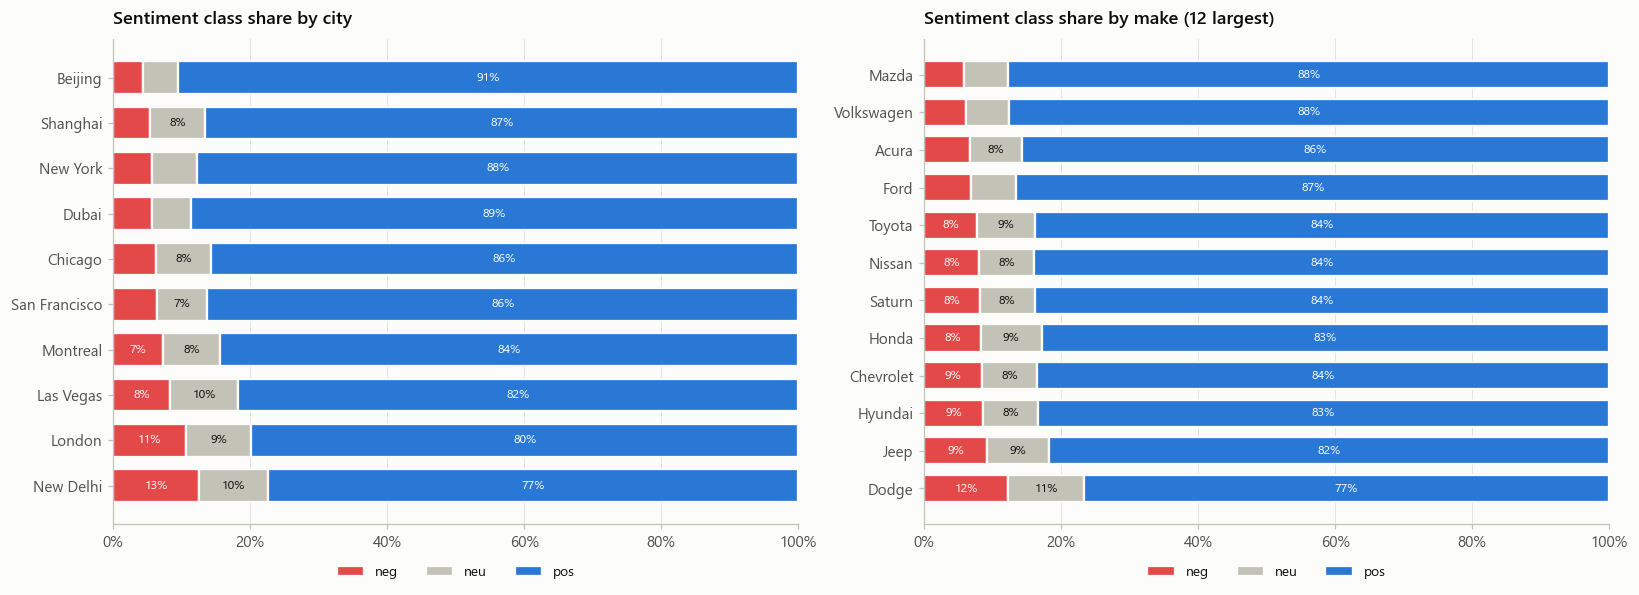

sent_class      neg   neu   pos
city_name                      
Beijing         4.4   5.1  90.6
Shanghai        5.4   8.0  86.6
New York        5.6   6.6  87.8
Dubai           5.7   5.6  88.7
Chicago         6.3   7.9  85.8
San Francisco   6.3   7.4  86.3
Montreal        7.2   8.4  84.4
Las Vegas       8.4   9.8  81.9
London         10.6   9.5  79.9
New Delhi      12.5  10.1  77.4
sent_class   neg   neu   pos
make                        
Mazda        5.8   6.5  87.7
Volkswagen   6.1   6.2  87.7
Acura        6.7   7.5  85.8
Ford         6.9   6.5  86.6
Toyota       7.7   8.5  83.8
Nissan       8.0   8.0  84.0
Saturn       8.1   8.0  83.9
Honda        8.3   8.8  82.9
Chevrolet    8.5   8.0  83.5
Hyundai      8.6   7.9  83.4
Jeep         9.2   9.0  81.8
Dodge       12.3  11.0  76.7


In [19]:
ct_city = pd.crosstab(H["city_name"], H["sent_class"])[["neg", "neu", "pos"]]
ct_city = ct_city.loc[(ct_city["neg"] / ct_city.sum(axis=1)).sort_values().index]
top_makes12 = C["make"].value_counts().index[:12]
ct_make = pd.crosstab(C["make"], C["sent_class"])[["neg", "neu", "pos"]].loc[top_makes12]
ct_make = ct_make.loc[(ct_make["neg"] / ct_make.sum(axis=1)).sort_values().index]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
sh_city = P.stacked_share(axs[0], ct_city, "Sentiment class share by city", P.SENT)
sh_make = P.stacked_share(axs[1], ct_make, "Sentiment class share by make (12 largest)", P.SENT)
fig.tight_layout()
P.save(fig, "s14_stacked_sentiment_share")
plt.show()
print(sh_city.round(1).to_string())
print(sh_make.round(1).to_string())

**Inferences (100 % stacked bars)**
* The negative share varies almost 3× across cities: **Beijing ≈ 4 %** (the most positive) vs
  **London ≈ 11 % and New Delhi ≈ 12.5 %**.
* Among the 12 largest makes, **Dodge has the highest negative share (≈ 12 %)**, while Mazda and
  Volkswagen have the lowest (≈ 6 %).
* Unlike the pie and doughnut, stacked bars make these part-of-whole differences easy to compare
  across many groups at once.

## 5 · Save the task-relevant dataset for the mining notebooks
Rows: all car reviews, plus hotel reviews of hotels with at least 10 reviews (1c).
Attributes: drop the redundant `char_count` (1b) and the ID-like / technical fields (1a), and
keep the transformed attributes (2a, 2b).

In [20]:
keep_hotels = per_hotel[per_hotel >= 10].index
mask = (df["domain"] == "car") | df.set_index(["city_name", "entity"]).index.isin(keep_hotels)
cols = ["domain", "city_name", "entity", "make", "model", "model_year", "date", "year", "quarter", "month",
        "text", "word_count", "wc_minmax", "wc_z", "len_class", "sentence_count", "avg_word_len",
        "exclaim_count", "upper_ratio", "n_aspects", "aspects", "sentiment", "sent_class"]
model_df = df.loc[mask, cols].reset_index(drop=True)
model_df.to_parquet(CLEAN / "reviews_model.parquet", index=False)
print(f"saved {len(model_df):,} reviews x {len(cols)} attributes:", model_df["domain"].value_counts().to_dict())

saved 259,143 reviews x 23 attributes: {'hotel': 218298, 'car': 40845}


# Part 3 · Association rules: Apriori, Apriori-based sequential patterns, A-Close (closed itemsets)

**Transactions.** Each review is one transaction: the set of aspects it mentions plus one
sentiment item (`sent=pos | neu | neg`). Example: {room, staff, location, sent=pos}. The two
domains are mined separately, because their aspect vocabularies differ.

**Sequences.** The same aspects in the order the reviewer first mentions them, for example
⟨location → room → staff⟩. These are used for sequential patterns.

**Assumed parameters** (the question allows them to be assumed and stated):

| Task | Hotels (218,295 reviews) | Cars (40,843 reviews) | Why |
|---|---|---|---|
| Apriori: min support | 5 % (≈ 10.9k reviews) | 2 % (≈ 820 reviews) | The Pareto chart shows the 12 "vital" aspects each appear in ≥ 15–25 % of reviews, so 5 % / 2 % keep 3- to 5-aspect combinations without an explosion of itemsets |
| Apriori: min confidence | 60 % | 50 % | Car reviews are shorter, with fewer aspects each (median 4 vs 7) |
| Sentiment-targeted rules | support 1 %, any confidence, ranked by lift | same | Negative reviews are only ~8 %, so rules predicting them can never reach 60 % confidence |
| Sequential patterns (GSP): min support / confidence | 5 % / 35 % | 2 % / 20 % | Every pair's support is split between its two orders (⟨a→b⟩ vs ⟨b→a⟩), so sequential confidences run far below itemset confidences. The best single-step hotel rule, ⟨room⟩ ⇒ ⟨staff⟩, reaches only 43 % |
| A-Close: min support | 5 % | 2 %, plus a low-support demonstration at 0.1 % | |

In [1]:
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import algos as A          # from-scratch Apriori, A-Close, GSP (src/algos.py, self-tested)
import plots as P

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

df = pd.read_parquet(CLEAN / "reviews_model.parquet")
DATA = {}
for dom in ["hotel", "car"]:
    d = df[df["domain"] == dom]
    tx = [list(a) + [f"sent={s}"] for a, s in zip(d["aspects"], d["sent_class"])]
    seqs = [list(a) for a in d["aspects"]]
    DATA[dom] = dict(tx=tx, seqs=seqs, n=len(tx))
    print(f"{dom}: {len(tx):,} transactions, {len({i for t in tx for i in t})} distinct items, "
          f"mean {np.mean([len(t) for t in tx]):.2f} items per transaction")
PARAM = {"hotel": dict(sup=0.05, conf=0.60, seq_sup=0.05, seq_conf=0.35),
         "car": dict(sup=0.02, conf=0.50, seq_sup=0.02, seq_conf=0.20)}

hotel: 218,298 transactions, 25 distinct items, mean 7.87 items per transaction


car: 40,845 transactions, 22 distinct items, mean 4.79 items per transaction


### Data transformation: from review text to transaction and sequence
Three hotel reviews, and the start of the one-hot (transaction × item) matrix that Apriori
implementations such as mlxtend expect.

In [2]:
from mlxtend.preprocessing import TransactionEncoder

h = df[df["domain"] == "hotel"].head(3)
for (_, r), t in zip(h.iterrows(), DATA["hotel"]["tx"][:3]):
    print(f"TEXT: {r['text'][:150]}...\n  sequence   : {' -> '.join(r['aspects'])}\n  transaction: {sorted(t)}\n")
te = TransactionEncoder()
onehot = {dom: pd.DataFrame(te.fit(DATA[dom]["tx"]).transform(DATA[dom]["tx"]), columns=te.columns_) for dom in DATA}
onehot["hotel"].iloc[:3, :12]

TEXT: we stayed in a 3 bedroomed-suite which was well furnished and the staff perfect hosts. they even organised a birthday cake for my Mum (we were all the...
  sequence   : staff -> room -> location -> food
  transaction: ['food', 'location', 'room', 'sent=pos', 'staff']

TEXT: We stayed at the Ascott Beijing this summer for 1 week in a family of 5. It is centrally located. When you are a european with kids staying for a few ...
  sequence   : location -> size -> service -> transport
  transaction: ['location', 'sent=pos', 'service', 'size', 'transport']

TEXT: check-in:my friends are i arrived from different countries @ different times and were greeted in the same lousy way. the bellboy did not help with lug...
  sequence   : checkin -> staff -> lobby -> room -> size -> bathroom -> location -> food -> transport -> breakfast -> gym_spa
  transaction: ['bathroom', 'breakfast', 'checkin', 'food', 'gym_spa', 'lobby', 'location', 'room', 'sent=neu', 'size', 'staff', 'transport']



,bar,bathroom,bed,breakfast,checkin,cleanliness,elevator,food,gym_spa,internet,lobby,location
0,False,False,False,False,False,False,False,True,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,False,True
2,False,True,False,True,True,False,False,True,True,False,True,True


## Part A · Apriori: frequent itemsets and association rules
`algos.apriori_bitset` is a from-scratch Apriori: level-wise **join** (shared k−1 prefix),
**prune** (every k-subset must be frequent) and **count**. Counting intersects TID-bitsets
(the vertical TID-list layout), so the database is never rescanned. The result is cross-checked
against mlxtend's FP-growth, which must find exactly the same number of itemsets.

In [3]:
from mlxtend.frequent_patterns import fpgrowth

FREQ = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    t0 = time.time()
    F = A.apriori_bitset(DATA[dom]["tx"], p["sup"])
    t_ap = time.time() - t0
    t0 = time.time()
    fi_mx = fpgrowth(onehot[dom], min_support=p["sup"], use_colnames=True)
    t_fp = time.time() - t0
    FREQ[dom] = F
    levels = Counter(len(s) for s in F)
    print(f"{dom} (min_sup {p['sup']:.0%} = {int(np.ceil(p['sup'] * n)):,} reviews): {len(F):,} frequent itemsets "
          f"in {t_ap:.1f}s | mlxtend FP-growth: {len(fi_mx):,} in {t_fp:.1f}s | identical: {len(F) == len(fi_mx)}")
    print("   itemsets per level L1..Lk:", dict(sorted(levels.items())))

hotel (min_sup 5% = 10,915 reviews): 2,300 frequent itemsets in 0.6s | mlxtend FP-growth: 2,300 in 2.9s | identical: True
   itemsets per level L1..Lk: {1: 25, 2: 174, 3: 501, 4: 750, 5: 587, 6: 230, 7: 33}


car (min_sup 2% = 817 reviews): 588 frequent itemsets in 0.1s | mlxtend FP-growth: 588 in 0.3s | identical: True
   itemsets per level L1..Lk: {1: 21, 2: 136, 3: 276, 4: 150, 5: 5}


In [4]:
RULES = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    RULES[dom] = A.rules_from_freq(FREQ[dom], n, min_conf=p["conf"])
    r = RULES[dom]
    print(f"{dom}: {len(r):,} strong rules (min_conf {p['conf']:.0%}); "
          f"lift > 1.2: {(r['lift'] > 1.2).sum():,}; median lift {r['lift'].median():.3f}")
print("\nHOTELS: top 12 rules by lift")
RULES["hotel"].head(12).round(3)

hotel: 8,631 strong rules (min_conf 60%); lift > 1.2: 4,157; median lift 1.193
car: 491 strong rules (min_conf 50%); lift > 1.2: 143; median lift 1.110

HOTELS: top 12 rules by lift


,antecedent,consequent,support,confidence,lift,conviction,size
0,"{bed, food, size}","{bathroom, room, sent=pos}",0.062,0.658,2.024,1.975,6
1,"{bed, cleanliness, location, size}","{bathroom, room, sent=pos}",0.053,0.658,2.022,1.971,7
2,"{bed, location, price, size}","{bathroom, room, sent=pos}",0.060,0.655,2.015,1.958,7
3,"{bed, food, room, size}","{bathroom, sent=pos}",0.062,0.667,1.982,1.991,6
4,"{bed, cleanliness, location, room, size}","{bathroom, sent=pos}",0.053,0.665,1.978,1.983,7
5,"{bed, price, size, staff}","{bathroom, room, sent=pos}",0.059,0.643,1.977,1.892,7
6,"{bed, food, size}","{bathroom, sent=pos}",0.062,0.664,1.975,1.977,5
7,"{bed, cleanliness, location, size}","{bathroom, sent=pos}",0.053,0.664,1.973,1.974,6
8,"{bed, location, size, staff}","{bathroom, room, sent=pos}",0.068,0.642,1.972,1.882,7
9,"{bed, location, price, room, size}","{bathroom, sent=pos}",0.060,0.663,1.970,1.968,7


In [5]:
print("CARS: top 12 rules by lift")
RULES["car"].head(12).round(3)

CARS: top 12 rules by lift


,antecedent,consequent,support,confidence,lift,conviction,size
0,"{comfort, electronics}",{seats},0.021,0.510,2.354,1.597,3
1,{sent=neg},{reliability},0.045,0.560,2.160,1.682,2
2,"{seats, styling}",{interior},0.033,0.537,2.143,1.619,3
3,"{seats, sent=pos, styling}",{interior},0.029,0.530,2.117,1.596,4
4,"{comfort, noise}","{ride, sent=pos}",0.025,0.513,2.105,1.553,4
5,"{cargo_space, styling}",{interior},0.026,0.525,2.096,1.579,3
6,"{comfort, noise, sent=pos}",{ride},0.025,0.563,2.096,1.673,4
7,"{cargo_space, sent=pos, styling}",{interior},0.024,0.523,2.087,1.571,4
8,"{handling, noise, sent=pos}",{ride},0.021,0.550,2.048,1.626,4
9,"{electronics, sent=pos, styling}",{interior},0.021,0.509,2.031,1.527,4


**Compact view.** The top of a lift-sorted list is crowded with near-copies of one pattern
(each with an extra item on either side). Short rules (at most 2 antecedent items, 1
consequent item) are easier to read and act on.

In [6]:
for dom in DATA:
    r = RULES[dom]
    short = r[(r["antecedent"].str.count(",") <= 1) & (r["consequent"].str.count(",") == 0)]
    print(f"{dom.upper()}: top short rules by lift")
    print(short.head(10)[["antecedent", "consequent", "support", "confidence", "lift", "conviction"]].round(3)
          .to_string(index=False), "\n")

HOTEL: top short rules by lift


         antecedent consequent  support  confidence  lift  conviction
     {bar, service}     {food}    0.054       0.685 1.816       1.977
{bathroom, checkin}      {bed}    0.055       0.617 1.728       1.678
   {bar, breakfast}     {food}    0.062       0.651 1.727       1.787
        {bed, size} {bathroom}    0.145       0.694 1.702       1.936
     {bed, checkin} {bathroom}    0.055       0.693 1.701       1.931
       {bar, price}     {food}    0.080       0.640 1.698       1.732
   {bathroom, view}      {bed}    0.051       0.602 1.687       1.617
         {bar, bed} {bathroom}    0.062       0.686 1.682       1.885
        {bar, size}     {food}    0.071       0.624 1.655       1.658
    {bar, bathroom}     {food}    0.065       0.622 1.650       1.648 

CAR: top short rules by lift
            antecedent    consequent  support  confidence  lift  conviction
{comfort, electronics}       {seats}    0.021       0.510 2.354       1.597
            {sent=neg} {reliability}    0.045 

**Inferences (Apriori)**
* The from-scratch Apriori and mlxtend's FP-growth find **exactly the same itemsets** (2,300 for
  hotels at 5 %, 588 for cars at 2 %), which confirms the implementation. Hotel itemsets reach
  7 items, because hotel reviews mention ~7 aspects each; car itemsets stop at 5.
* The strongest hotel rules form one family: **{bed, size, …} ⇒ {bathroom}**, lift ≈ 2.
  Reviewers who describe the bed and the room size almost always go on to describe the bathroom.
  This is a "room inspection" reviewing style.
* In cars, **{comfort, electronics} ⇒ {seats}** (lift 2.35), **{seats, styling} ⇒ {interior}**
  and **{comfort, noise} ⇒ {ride}** show which aspects are judged together: cabin features
  group with the interior, noise with ride quality.
* The most actionable car rule is **{sent=neg} ⇒ {reliability}** (confidence 56 %, lift 2.16).
  More than half of all negative car reviews discuss reliability.

### Rules that predict a negative review
Negative reviews are only ~8 %, so a rule ending in `sent=neg` can never reach 60 % confidence.
Here the consequent is fixed to {sent=neg} and the rules are ranked by **lift**: how many times
more likely a review is to be negative when it mentions that aspect combination.

In [7]:
NEG, POS = {}, {}
for dom in DATA:
    n = DATA[dom]["n"]
    F1 = A.apriori_bitset(DATA[dom]["tx"], 0.01)
    NEG[dom] = A.rules_from_freq(F1, n, min_conf=0.0, consequent="sent=neg")
    POS[dom] = A.rules_from_freq(F1, n, min_conf=0.0, consequent="sent=pos")
    base = sum("sent=neg" in t for t in DATA[dom]["tx"]) / n
    print(f"{dom}: P(sent=neg) = {base:.3f}; {len(NEG[dom])} rules with support >= 1% ending in sent=neg")
    print(NEG[dom].head(8)[["antecedent", "support", "confidence", "lift"]].round(3).to_string(index=False), "\n")
    print(f"{dom}: aspect sets with the HIGHEST lift towards sent=pos")
    print(POS[dom].head(5)[["antecedent", "support", "confidence", "lift"]].round(3).to_string(index=False), "\n")

hotel: P(sent=neg) = 0.077; 63 rules with support >= 1% ending in sent=neg
                   antecedent  support  confidence  lift
                   {bathroom}    0.033       0.081 1.048
             {bathroom, room}    0.031       0.078 1.007
                       {room}    0.066       0.074 0.960
      {bathroom, cleanliness}    0.016       0.074 0.960
                        {bed}    0.026       0.072 0.934
            {bathroom, staff}    0.020       0.072 0.928
{bathroom, cleanliness, room}    0.015       0.071 0.923
                    {checkin}    0.012       0.071 0.922 

hotel: aspect sets with the HIGHEST lift towards sent=pos
                            antecedent  support  confidence  lift
               {bar, food, pool, view}    0.010       0.967 1.149
         {breakfast, food, pool, view}    0.010       0.967 1.149
         {bar, food, pool, room, view}    0.010       0.967 1.149
   {breakfast, food, pool, room, view}    0.010       0.967 1.149
{bar, bathroom, breakf

**Inferences (sentiment-targeted rules)**
* **Cars:** {dealer, reliability} ⇒ negative has **lift 4.2**. A review that mentions both the
  dealer and reliability is four times as likely as average to be negative (33 % vs 8 %). Dealer
  alone gives lift 2.8 and reliability alone 2.2. Bad car reviews are about breakdowns and how
  the dealer handled them.
* **Hotels:** no aspect combination with ≥ 1 % support raises the chance of a negative review
  by more than 5 % (best lift ≈ 1.05, for bathroom). Negative hotel reviews mention the *same*
  aspects as positive ones; the difference is in *what* is said about them, not *which*
  aspects are mentioned.
* Positive sentiment is most strongly associated with **leisure facilities** (pool, view, bar,
  food: confidence ≈ 97 %) for hotels, and with **comfort + ride + fuel economy** for cars.

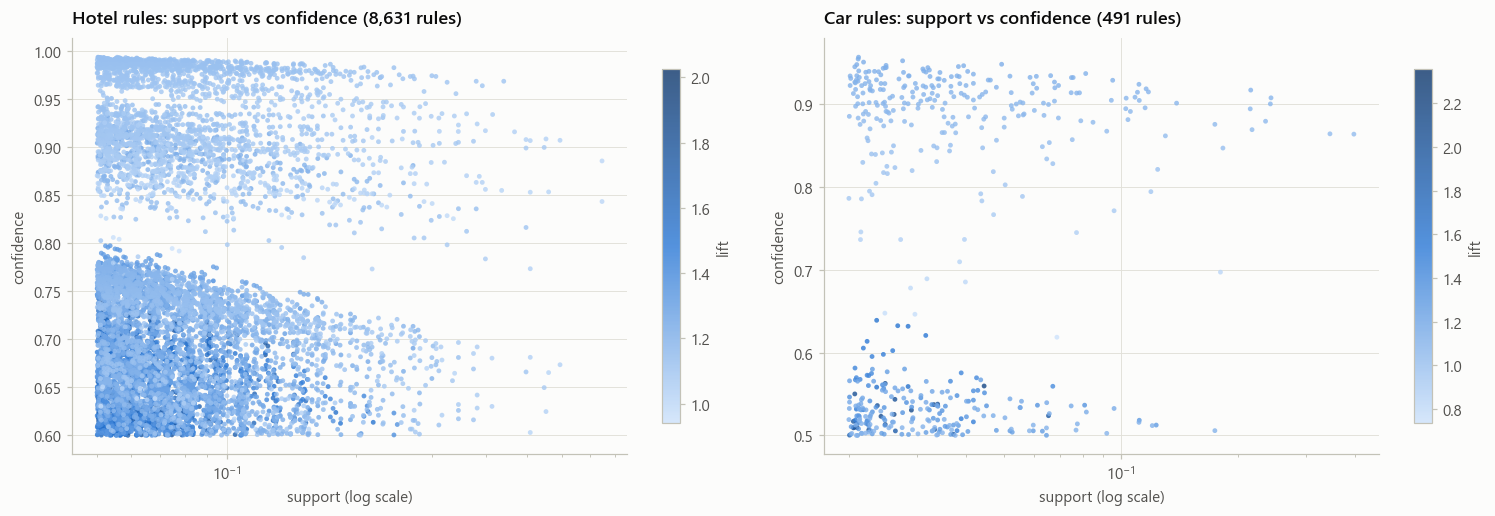

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, dom in zip(axs, ["hotel", "car"]):
    r = RULES[dom]
    sc = ax.scatter(r["support"], r["confidence"], c=r["lift"], cmap=P.SEQUENTIAL, s=10, alpha=0.8,
                    edgecolor="none", rasterized=True)
    fig.colorbar(sc, ax=ax, label="lift", shrink=0.85)
    ax.set_xscale("log")
    ax.set_xlabel("support (log scale)")
    ax.set_ylabel("confidence")
    ax.set_title(f"{dom.title()} rules: support vs confidence ({len(r):,} rules)")
fig.tight_layout()
P.save(fig, "a01_rules_scatter")
plt.show()

## Part B · Apriori-based sequential patterns (GSP / AprioriAll style)
A sequence pattern ⟨a → b → c⟩ is supported by a review that mentions a, then later b, then
later c (gaps allowed). `algos.gsp` mines these level-wise, like Apriori:
* **join:** s1 with s2 when s1 minus its first item equals s2 minus its last item;
* **prune:** every sub-sequence with one item removed must be frequent;
* **count:** vectorised over a position matrix.

Sequential rules read **⟨prefix⟩ ⇒ ⟨continuation⟩**: "a review that first mentions the prefix
in this order goes on to mention the continuation". Confidence = sup(sequence) / sup(prefix).

In [9]:
SEQ, SEQR = {}, {}
for dom in DATA:
    p, n, seqs = PARAM[dom], DATA[dom]["n"], DATA[dom]["seqs"]
    first = pd.Series([s[0] for s in seqs if s]).value_counts(normalize=True).head(6).round(3)
    print(f"{dom}: aspect mentioned FIRST:", first.to_dict())
    t0 = time.time()
    SEQ[dom] = A.gsp(seqs, p["seq_sup"])
    SEQR[dom] = A.sequential_rules(SEQ[dom], n, min_conf=p["seq_conf"])
    by_len = Counter(len(s) for s in SEQ[dom])
    print(f"   {len(SEQ[dom])} frequent sequences (min_sup {p['seq_sup']:.0%}) in {time.time() - t0:.1f}s, by length: "
          f"{dict(sorted(by_len.items()))}; {len(SEQR[dom])} sequential rules (min_conf {p['seq_conf']:.0%})")
top_seq = {dom: pd.DataFrame([(" -> ".join(s), c / DATA[dom]["n"]) for s, c in SEQ[dom].items() if len(s) >= 2],
                             columns=["sequence", "support"]).sort_values("support", ascending=False) for dom in DATA}
print("\nmost frequent hotel sequences (length >= 2):")
print(top_seq["hotel"].head(10).round(3).to_string(index=False))
print("\nmost frequent car sequences (length >= 2):")
print(top_seq["car"].head(8).round(3).to_string(index=False))

hotel: aspect mentioned FIRST: {'room': 0.298, 'location': 0.202, 'staff': 0.112, 'price': 0.109, 'cleanliness': 0.044, 'service': 0.036}


   274 frequent sequences (min_sup 5%) in 8.6s, by length: {1: 22, 2: 152, 3: 100}; 35 sequential rules (min_conf 35%)
car: aspect mentioned FIRST: {'fuel_economy': 0.161, 'engine': 0.128, 'styling': 0.088, 'price': 0.087, 'reliability': 0.084, 'ride': 0.081}


   175 frequent sequences (min_sup 2%) in 0.6s, by length: {1: 18, 2: 157}; 21 sequential rules (min_conf 20%)

most frequent hotel sequences (length >= 2):
           sequence  support
      room -> staff    0.383
       room -> size    0.372
   room -> bathroom    0.366
room -> cleanliness    0.339
      room -> price    0.321
   room -> location    0.314
        room -> bed    0.307
  room -> breakfast    0.294
       room -> food    0.278
   location -> room    0.238

most frequent car sequences (length >= 2):
                   sequence  support
     engine -> fuel_economy    0.113
     fuel_economy -> engine    0.086
       ride -> fuel_economy    0.073
      fuel_economy -> price    0.072
         engine -> handling    0.070
         engine -> interior    0.069
fuel_economy -> reliability    0.066
             ride -> engine    0.065


In [10]:
print("HOTELS: sequential rules, top 12 by confidence")
SEQR["hotel"].sort_values("confidence", ascending=False).head(12).round(3)

HOTELS: sequential rules, top 12 by confidence


,antecedent,consequent,length,support,confidence,lift
7,location -> room,size,3,0.103,0.434,0.954
20,room,staff,2,0.383,0.433,0.660
0,price -> room,bathroom,3,0.063,0.432,1.061
33,checkin,room,2,0.073,0.430,0.487
9,price -> room,size,3,0.062,0.427,0.938
11,room,size,2,0.372,0.421,0.926
1,room,bathroom,2,0.366,0.414,1.016
2,room -> bed,bathroom,3,0.124,0.404,0.992
4,location -> room,bathroom,3,0.096,0.404,0.991
5,bed,bathroom,2,0.144,0.403,0.989


In [11]:
print("CARS: sequential rules, top 10 by lift")
SEQR["car"].head(10).round(3)

CARS: sequential rules, top 10 by lift


,antecedent,consequent,length,support,confidence,lift
0,interior,seats,2,0.060,0.238,1.101
1,seats,comfort,2,0.048,0.221,0.939
2,dealer,reliability,2,0.024,0.216,0.833
3,interior,styling,2,0.052,0.207,0.769
4,engine,fuel_economy,2,0.113,0.283,0.614
5,ride,engine,2,0.065,0.241,0.604
6,ride,fuel_economy,2,0.073,0.272,0.589
7,comfort,fuel_economy,2,0.063,0.266,0.578
8,handling,fuel_economy,2,0.063,0.261,0.567
9,styling,engine,2,0.060,0.222,0.554


### Order matters: the same pair of aspects in both directions
A plain itemset rule cannot tell ⟨a → b⟩ from ⟨b → a⟩. Sequences can. Below, the support of
each order for the most common hotel pairs.

In [12]:
pairs = [(a, b) for (a, b) in [s for s in SEQ["hotel"] if len(s) == 2] if a < b]
order = pd.DataFrame([(a, b, SEQ["hotel"].get((a, b), 0) / DATA["hotel"]["n"],
                       SEQ["hotel"].get((b, a), 0) / DATA["hotel"]["n"]) for a, b in pairs],
                     columns=["a", "b", "sup <a,b>", "sup <b,a>"])
order["ratio a-first"] = order["sup <a,b>"] / (order["sup <a,b>"] + order["sup <b,a>"])
order.sort_values("sup <a,b>", ascending=False).head(10).round(3)

,a,b,"sup <a,b>","sup <b,a>",ratio a-first
29,room,staff,0.383,0.212,0.644
37,room,size,0.372,0.068,0.846
52,location,room,0.238,0.314,0.432
35,location,staff,0.224,0.190,0.541
19,room,service,0.194,0.062,0.757
60,location,price,0.191,0.144,0.570
31,cleanliness,staff,0.174,0.133,0.567
14,size,staff,0.173,0.142,0.549
50,location,size,0.155,0.153,0.503
43,cleanliness,location,0.154,0.144,0.517


**Inferences (sequential patterns)**
* Reviews follow a **narrative order**. Hotel reviews most often open with the *room* (30 %),
  then *location* (20 %), *staff* (11 %) or *price* (11 %). Car reviews open with *fuel
  economy* (16 %) or the *engine* (13 %).
* The most frequent hotel sequence is ⟨room → staff⟩ (38 % of reviews). *Size* comes after
  *room* in **85 %** of the reviews that mention both: size is described as a property of the
  room. *Location* and *room* are the exception, with room first 57 % of the time.
* Three-step rules describe the typical walk-through:
  **⟨location → room⟩ ⇒ ⟨size⟩** (confidence 43 %) and **⟨price → room⟩ ⇒ ⟨bathroom⟩**
  (43 %, lift 1.06). Reviewers who start with the deal or the location go on to judge the room
  in detail.
* In cars, ⟨engine → fuel economy⟩ (11.3 %) is more common than the reverse (8.6 %):
  performance is discussed before economy. **⟨dealer⟩ ⇒ ⟨reliability⟩** (22 %) is the
  complaint narrative already seen in the itemset rules: the dealer visit comes first, then the
  reliability problem.
* The lift of a sequential rule compares with the consequent's frequency *anywhere* in a
  review. Values below 1 are therefore expected whenever the consequent often comes *before*
  the antecedent, so confidence is the better ranking here.

## Part C · A-Close: closed frequent itemsets (CFIs) and closed association rules
A-Close mines **minimal generators** level-wise and closes each one with the Galois
closure f(g) = i(t(g)), the items shared by every transaction that contains g. The resulting
CFIs are a **lossless** summary of all frequent itemsets: the support of any frequent itemset
is the largest support among its closed supersets. Rules are then generated from the CFIs (the
generic min-max basis): **exact rules** g ⇒ f(g)∖g with 100 % confidence, and **approximate
rules** g ⇒ C∖g for closed supersets C.

In [13]:
CL = {}
for dom in DATA:
    p, n = PARAM[dom], DATA[dom]["n"]
    t0 = time.time()
    cfis, table, gens = A.aclose(DATA[dom]["tx"], p["sup"])
    t_ac = time.time() - t0
    closed_ref, maximal = A.fi_closed_maximal(FREQ[dom])
    CL[dom] = dict(cfis=cfis, table=table, gens=gens, mfi=maximal)
    nontrivial = sum(g != c for g, c, _ in gens)
    print(f"{dom} (min_sup {p['sup']:.0%}): A-Close found {len(cfis):,} CFIs from {len(gens):,} minimal generators in {t_ac:.1f}s; "
          f"non-trivial closures: {nontrivial}; equals closed(Apriori FIs): {set(cfis) == set(closed_ref)}")
    print(f"   FI = {len(FREQ[dom]):,}   CFI = {len(cfis):,}   MFI = {len(maximal):,}")
    some = list(FREQ[dom])[::max(1, len(FREQ[dom]) // 200)]
    assert all(A.support_from_cfis(s, cfis) == FREQ[dom][s] for s in some)   # lossless property
print("lossless check passed: supports of sampled frequent itemsets recovered from the CFIs alone")
CL["hotel"]["table"].head(10)

hotel (min_sup 5%): A-Close found 2,300 CFIs from 2,300 minimal generators in 1.4s; non-trivial closures: 0; equals closed(Apriori FIs): True
   FI = 2,300   CFI = 2,300   MFI = 356
car (min_sup 2%): A-Close found 588 CFIs from 588 minimal generators in 0.1s; non-trivial closures: 0; equals closed(Apriori FIs): True
   FI = 588   CFI = 588   MFI = 213
lossless check passed: supports of sampled frequent itemsets recovered from the CFIs alone


,minimal_generator,closure (CFI),support_count,support
0,{room},{room},192932,0.883801
1,{sent=pos},{sent=pos},183738,0.841684
2,"{room, sent=pos}","{room, sent=pos}",162660,0.745128
3,{staff},{staff},143290,0.656396
4,{location},{location},132728,0.608013
5,"{room, staff}","{room, staff}",129926,0.595177
6,"{sent=pos, staff}","{sent=pos, staff}",122236,0.559950
7,"{location, room}","{location, room}",120536,0.552163
8,"{location, sent=pos}","{location, sent=pos}",119365,0.546798
9,{price},{price},111261,0.509675


In [14]:
CR = {}
for dom in DATA:
    CR[dom] = A.closed_rules(DATA[dom]["n"], CL[dom]["cfis"], CL[dom]["gens"], min_conf=PARAM[dom]["conf"])
    print(f"{dom}: {len(CR[dom]):,} closed rules ({(CR[dom]['type'] == 'exact').sum()} exact, "
          f"{(CR[dom]['type'] == 'approximate').sum():,} approximate) vs {len(RULES[dom]):,} Apriori rules")
print("\nHOTELS: closed (min-max) rules, top 10 by lift")
CR["hotel"].head(10).round(3)

hotel: 8,631 closed rules (0 exact, 8,631 approximate) vs 8,631 Apriori rules
car: 491 closed rules (0 exact, 491 approximate) vs 491 Apriori rules

HOTELS: closed (min-max) rules, top 10 by lift


,antecedent,consequent,support,confidence,lift,type
0,"{bed, food, size}","{bathroom, room, sent=pos}",0.062,0.658,2.024,approximate
1,"{bed, cleanliness, location, size}","{bathroom, room, sent=pos}",0.053,0.658,2.022,approximate
2,"{bed, location, price, size}","{bathroom, room, sent=pos}",0.060,0.655,2.015,approximate
3,"{bed, food, room, size}","{bathroom, sent=pos}",0.062,0.667,1.982,approximate
4,"{bed, cleanliness, location, room, size}","{bathroom, sent=pos}",0.053,0.665,1.978,approximate
5,"{bed, price, size, staff}","{bathroom, room, sent=pos}",0.059,0.643,1.977,approximate
6,"{bed, food, size}","{bathroom, sent=pos}",0.062,0.664,1.975,approximate
7,"{bed, cleanliness, location, size}","{bathroom, sent=pos}",0.053,0.664,1.973,approximate
8,"{bed, location, size, staff}","{bathroom, room, sent=pos}",0.068,0.642,1.972,approximate
9,"{bed, location, price, room, size}","{bathroom, sent=pos}",0.060,0.663,1.970,approximate


### Why CFI = FI here, and where closure starts to matter
With 218k reviews, two different itemsets almost never have *exactly* the same support: no
aspect is always mentioned together with another. So every frequent itemset is its own closure
and the CFI summary is lossless but no smaller. Exact co-occurrences only appear when the
support threshold is very low (a few dozen reviews). The run below repeats A-Close on the car
reviews at **min_sup = 0.1 % (≈ 41 reviews)**.

In [15]:
t0 = time.time()
cf_lo, tab_lo, gens_lo = A.aclose(DATA["car"]["tx"], 0.001)
F_lo = A.apriori_bitset(DATA["car"]["tx"], 0.001)
closed_lo, max_lo = A.fi_closed_maximal(F_lo)
print(f"cars at 0.1%: FI = {len(F_lo):,}  CFI = {len(cf_lo):,}  MFI = {len(max_lo):,}  "
      f"(A-Close == closed(Apriori): {set(cf_lo) == set(closed_lo)}; {time.time() - t0:.1f}s)")
nt = tab_lo[tab_lo["minimal_generator"] != tab_lo["closure (CFI)"]]
print(f"{len(nt)} generators whose closure is larger than the generator, e.g.:")
print(nt.sort_values("support_count", ascending=False).head(8).to_string(index=False))
exact_lo = A.closed_rules(DATA["car"]["n"], cf_lo, gens_lo, min_conf=1.0)
added = Counter(c for c in exact_lo["consequent"])
print(f"\n{len(exact_lo)} exact rules (confidence 100%); consequents: {dict(added)}")

cars at 0.1%: FI = 13,429  CFI = 13,334  MFI = 3,261  (A-Close == closed(Apriori): True; 1.3s)
95 generators whose closure is larger than the generator, e.g.:
                                           minimal_generator                                                          closure (CFI)  support_count  support
           {cargo_space, comfort, fuel_economy, noise, ride}            {cargo_space, comfort, fuel_economy, noise, ride, sent=pos}            134 0.003281
           {cargo_space, comfort, ride, seats, transmission}            {cargo_space, comfort, ride, seats, sent=pos, transmission}             90 0.002203
     {cargo_space, comfort, engine, interior, ride, styling}      {cargo_space, comfort, engine, interior, ride, sent=pos, styling}             86 0.002106
{cargo_space, comfort, engine, fuel_economy, handling, ride} {cargo_space, comfort, engine, fuel_economy, handling, ride, sent=pos}             80 0.001959
        {cargo_space, comfort, fuel_economy, noise, styling} 


95 exact rules (confidence 100%); consequents: {'{sent=pos}': 95}


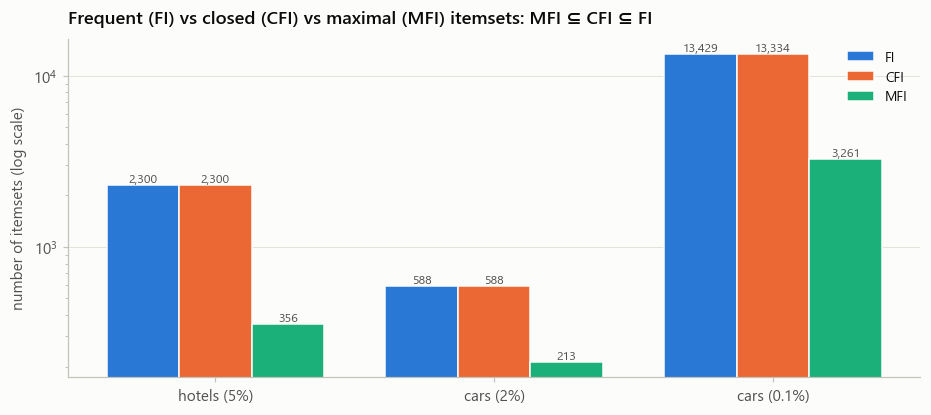

,hotels (5%),cars (2%),cars (0.1%)
FI,2300,588,13429
CFI,2300,588,13334
MFI,356,213,3261


In [16]:
counts = pd.DataFrame({"hotels (5%)": [len(FREQ['hotel']), len(CL['hotel']['cfis']), len(CL['hotel']['mfi'])],
                       "cars (2%)": [len(FREQ['car']), len(CL['car']['cfis']), len(CL['car']['mfi'])],
                       "cars (0.1%)": [len(F_lo), len(cf_lo), len(max_lo)]}, index=["FI", "CFI", "MFI"])
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(counts.columns))
for i, (name, row) in enumerate(counts.iterrows()):
    ax.bar(x + (i - 1) * 0.26, row.values, 0.26, color=P.SERIES[i], label=name, edgecolor=P.SURFACE, linewidth=1)
    for xi, v in zip(x, row.values):
        ax.text(xi + (i - 1) * 0.26, v, f"{v:,}", ha="center", va="bottom", fontsize=8, color=P.INK2)
ax.set_xticks(x)
ax.set_xticklabels(counts.columns)
ax.set_yscale("log")
ax.set_ylabel("number of itemsets (log scale)")
ax.set_title("Frequent (FI) vs closed (CFI) vs maximal (MFI) itemsets: MFI ⊆ CFI ⊆ FI")
ax.legend()
ax.grid(axis="x", visible=False)
P.save(fig, "a02_fi_cfi_mfi")
plt.show()
counts

**Inferences (A-Close)**
* A-Close's CFIs equal the closed itemsets derived from Apriori's output in every run. The
  **lossless property** was verified too: the support of every sampled frequent itemset is
  recovered from the CFIs alone.
* At the working supports (5 % / 2 %), **every frequent itemset is closed** (FI = CFI), so
  every generator is its own closure and there are no exact (100 %) rules. On a large dataset,
  two aspect combinations practically never occur in exactly the same reviews. The useful
  compression comes from the **maximal** itemsets instead (2,300 → 356 for hotels, 6.5×), which
  is lossy: the supports are lost.
* At a low support (0.1 %, about 41 car reviews), closure starts to matter: **95 itemsets are
  absorbed into larger closed sets**, and every one of them gains the item *sent=pos*. These
  give 95 **exact rules** such as {cargo space, comfort, fuel economy, noise, ride} ⇒ {sent=pos}
  (134 reviews, all positive): combinations of comfort-related praise that never once appear
  in a non-positive car review.

## Save the rule tables

In [17]:
for dom in DATA:
    RULES[dom].to_csv(TABLES / f"apriori_rules_{dom}.csv", index=False)
    SEQR[dom].to_csv(TABLES / f"sequential_rules_{dom}.csv", index=False)
    CR[dom].to_csv(TABLES / f"closed_rules_{dom}.csv", index=False)
    CL[dom]["table"].to_csv(TABLES / f"aclose_generators_{dom}.csv", index=False)
    NEG[dom].to_csv(TABLES / f"neg_rules_{dom}.csv", index=False)
print("saved:", sorted(p.name for p in TABLES.glob("*rules*.csv")))

saved: ['apriori_rules_car.csv', 'apriori_rules_hotel.csv', 'closed_rules_car.csv', 'closed_rules_hotel.csv', 'neg_rules_car.csv', 'neg_rules_hotel.csv', 'sequential_rules_car.csv', 'sequential_rules_hotel.csv']


# Part 4 · Clustering the reviews: k-means (with a hierarchical-clustering cross-check)

**Why clustering, not KNN.** OpinRank has no class label (no star rating), so there is nothing
for a supervised KNN classifier to learn. The question asks for "KNN classification / k-means
clustering, whichever is relevant". Unsupervised k-means fits: it finds the *kinds* of review
that exist.

**Representation (transformation)**
1. TF-IDF of the cleaned text: English stop-words removed, terms in at least 20 reviews and at
   most 40 % of reviews, sublinear tf. Rows are L2-normalised.
2. TruncatedSVD (LSA) to 100 dimensions: dimensionality reduction, which removes noise
   and synonymy.
3. Rows re-normalised to unit length. For unit vectors ‖a − b‖² = 2 − 2·cos(a, b), so
   Euclidean k-means groups reviews by **cosine** similarity, the usual text measure.

Each domain is clustered separately. Clustering cars and hotels together would only split
them apart, which is trivial.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, cophenet
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.preprocessing import normalize

import plots as P

warnings.filterwarnings("ignore", category=FutureWarning)
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
TABLES = Path("../outputs/tables")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)
SEED = 42

df = pd.read_parquet(CLEAN / "reviews_model.parquet")
print(df["domain"].value_counts().to_dict())

{'hotel': 218298, 'car': 40845}


In [2]:
def represent(texts, n_comp=100):
    """TF-IDF -> TruncatedSVD (LSA) -> unit-length rows. Returns (vectorizer, tfidf, svd, Z)."""
    vec = TfidfVectorizer(stop_words="english", min_df=20, max_df=0.4, sublinear_tf=True,
                          token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", dtype=np.float32)
    X = vec.fit_transform(texts)
    svd = TruncatedSVD(n_components=n_comp, random_state=SEED)
    Z = normalize(svd.fit_transform(X)).astype(np.float32)
    return vec, X, svd, Z


REP = {}
for dom in ["hotel", "car"]:
    t0 = time.time()
    d = df[df["domain"] == dom].reset_index(drop=True)
    vec, X, svd, Z = represent(d["text"])
    REP[dom] = dict(d=d, vec=vec, X=X, svd=svd, Z=Z)
    print(f"{dom}: TF-IDF {X.shape[0]:,} x {X.shape[1]:,} ({X.nnz / X.shape[0]:.0f} non-zeros per review), "
          f"SVD-100 explains {svd.explained_variance_ratio_.sum():.1%} of variance, {time.time() - t0:.0f}s")

hotel: TF-IDF 218,298 x 17,562 (62 non-zeros per review), SVD-100 explains 12.7% of variance, 43s


car: TF-IDF 40,845 x 4,861 (33 non-zeros per review), SVD-100 explains 17.7% of variance, 5s


## Choosing K: elbow (SSE) and silhouette
k-means is run for K = 2…12 on a random sample of 30,000 reviews, 4 restarts each, recording:
* the **SSE** (inertia), which always falls as K grows, so look for the elbow;
* the **silhouette** on 8,000 points (−1…1, higher = tighter and better-separated clusters).

The elbow is located objectively with the "knee" rule: the K whose (normalised) SSE point lies
farthest from the straight line joining the first and last points.

hotel knee at K = 6
           SSE  silhouette  davies_bouldin   knee
K                                                
2   23298.9219      0.0214          5.8451  False
3   22887.7871      0.0202          4.9724  False
4   22499.9395      0.0232          4.8972  False
5   22229.3223      0.0270          5.2265  False
6   21990.9785      0.0310          4.9613   True
7   21775.1055      0.0276          4.8170  False
8   21586.1855      0.0288          4.9366  False
9   21421.3477      0.0296          4.6731  False
10  21284.2246      0.0286          4.6058  False
11  21154.4082      0.0284          4.5876  False
12  21027.8984      0.0304          4.5958  False 



car knee at K = 7
           SSE  silhouette  davies_bouldin   knee
K                                                
2   24955.2773      0.0177          6.8667  False
3   24552.9551      0.0175          5.9449  False
4   24265.2070      0.0188          6.0740  False
5   23934.5605      0.0230          5.4934  False
6   23707.8691      0.0227          5.3073  False
7   23486.2949      0.0253          5.2729   True
8   23295.0039      0.0251          5.1030  False
9   23135.7812      0.0254          4.9865  False
10  22974.3242      0.0268          4.9379  False
11  22835.6895      0.0273          4.8753  False
12  22749.0469      0.0274          4.8517  False 



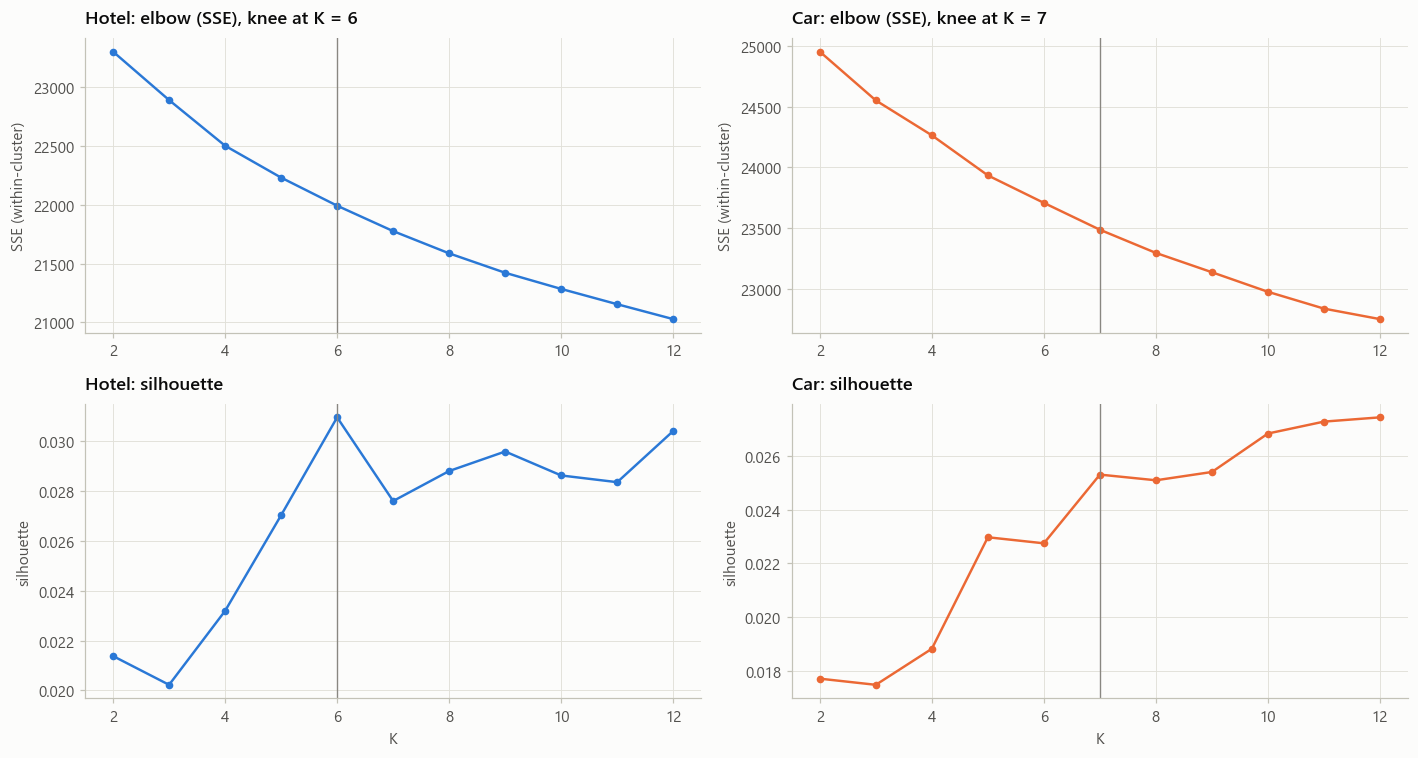

In [3]:
def knee(ks, sse):
    x = (np.asarray(ks) - ks[0]) / (ks[-1] - ks[0])
    y = (np.asarray(sse) - sse[-1]) / (sse[0] - sse[-1])
    return ks[int(np.argmax(np.abs(1 - x - y) / np.sqrt(2)))]


KS = list(range(2, 13))
SEL = {}
rng = np.random.default_rng(SEED)
for dom in REP:
    Z = REP[dom]["Z"]
    idx = rng.choice(len(Z), size=min(30000, len(Z)), replace=False)
    sil_idx = idx[:8000]
    rows = []
    for k in KS:
        km = KMeans(n_clusters=k, n_init=4, random_state=SEED).fit(Z[idx])
        lab = km.predict(Z[sil_idx])
        rows.append(dict(K=k, SSE=km.inertia_, silhouette=silhouette_score(Z[sil_idx], lab),
                         davies_bouldin=davies_bouldin_score(Z[sil_idx], lab)))
    SEL[dom] = pd.DataFrame(rows).set_index("K")
    SEL[dom]["knee"] = SEL[dom].index == knee(KS, SEL[dom]["SSE"].values)
    print(dom, "knee at K =", knee(KS, SEL[dom]["SSE"].values))
    print(SEL[dom].round(4).to_string(), "\n")

fig, axs = plt.subplots(2, 2, figsize=(13, 7))
for col, dom in enumerate(REP):
    s, c = SEL[dom], P.DOMAIN[dom]
    k_star = int(s.index[s["knee"]][0])
    axs[0, col].plot(s.index, s["SSE"], color=c, marker="o", ms=4)
    axs[0, col].axvline(k_star, color=P.MUTED, lw=0.9)
    axs[0, col].set_title(f"{dom.title()}: elbow (SSE), knee at K = {k_star}")
    axs[0, col].set_ylabel("SSE (within-cluster)")
    axs[1, col].plot(s.index, s["silhouette"], color=c, marker="o", ms=4)
    axs[1, col].axvline(k_star, color=P.MUTED, lw=0.9)
    axs[1, col].set_title(f"{dom.title()}: silhouette")
    axs[1, col].set_ylabel("silhouette")
    axs[1, col].set_xlabel("K")
fig.tight_layout()
P.save(fig, "k01_elbow_silhouette")
plt.show()

**Inferences (choosing K)**
* The SSE curve bends gently. The knee rule puts the elbow at **K = 6 for hotels** and
  **K = 7 for cars**.
* For hotels the silhouette **peaks at K = 6** (0.031), agreeing with the knee. For cars it
  keeps creeping up to K = 12, so K = 7 is the knee's compromise between fit and interpretability.
* Silhouette values are low (0.02–0.03) for every K. That is normal for text in 100 dimensions:
  reviews mix topics, so the clusters overlap and are best read as dominant *themes*, not
  sharply separated groups.

## Final k-means on all reviews and cluster description
Fit with K at the knee (10 restarts) on **all** reviews of the domain. Each cluster is described by:
* its **top TF-IDF terms**, the if-then style "rule" that defines it;
* its mean sentiment and length;
* its city or make mix;
* how much more or less than average it mentions each aspect.

In [4]:
def describe_clusters(dom, k):
    R = REP[dom]
    d, X, Z, vec = R["d"], R["X"], R["Z"], R["vec"]
    t0 = time.time()
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z)
    lab = km.labels_
    d = d.assign(cluster=lab)
    terms = np.array(vec.get_feature_names_out())
    rows = []
    group = "city_name" if dom == "hotel" else "make"
    for c in range(k):
        m = lab == c
        centroid = np.asarray(X[m].mean(axis=0)).ravel()
        top = terms[np.argsort(centroid)[::-1][:10]]
        mix = d.loc[m, group].value_counts(normalize=True)
        rows.append(dict(cluster=c, size=int(m.sum()), share=m.mean(), top_terms=", ".join(top),
                         mean_sentiment=d.loc[m, "sentiment"].mean(), neg_share=(d.loc[m, "sent_class"] == "neg").mean(),
                         median_words=d.loc[m, "word_count"].median(),
                         top_group=f"{mix.index[0]} ({mix.iloc[0]:.0%})"))
    prof = pd.DataFrame(rows).set_index("cluster")
    sample = np.random.default_rng(SEED).choice(len(Z), 10000, replace=False)
    metrics = dict(K=k, SSE=km.inertia_, silhouette=silhouette_score(Z[sample], lab[sample]),
                   davies_bouldin=davies_bouldin_score(Z[sample], lab[sample]),
                   calinski_harabasz=calinski_harabasz_score(Z[sample], lab[sample]), seconds=time.time() - t0)
    return km, d, prof, metrics


KM = {}
for dom in REP:
    k = int(SEL[dom].index[SEL[dom]["knee"]][0])
    km, d, prof, metrics = describe_clusters(dom, k)
    KM[dom] = dict(km=km, d=d, prof=prof, metrics=metrics)
    print(f"{dom}: final k-means, K = {k}:", {m: round(v, 4) for m, v in metrics.items()})
KM["hotel"]["prof"].round(3)

hotel: final k-means, K = 6: {'K': 6, 'SSE': 160112.5781, 'silhouette': 0.03, 'davies_bouldin': 4.9871, 'calinski_harabasz': 175.8827, 'seconds': 18.4303}


car: final k-means, K = 7: {'K': 7, 'SSE': 31980.6621, 'silhouette': 0.0261, 'davies_bouldin': 5.2774, 'calinski_harabasz': 139.9477, 'seconds': 9.3994}


,size,share,top_terms,mean_sentiment,neg_share,median_words,top_group
cluster,,,,,,,
0,17379,0.080,"strip, vegas, casino, pool, las, nice, time, place, clean, just",0.270,0.035,175.0,Las Vegas (99%)
1,30959,0.142,"new, york, square, times, nyc, subway, clean, central, just, small",0.323,0.014,150.0,New York (91%)
2,14957,0.069,"san, francisco, union, car, square, cable, wharf, parking, street, clean",0.312,0.023,148.0,San Francisco (97%)
3,36897,0.169,"london, tube, station, breakfast, clean, walk, small, nice, just, night",0.301,0.024,145.0,London (97%)
4,67823,0.311,"service, nice, clean, excellent, friendly, breakfast, helpful, comfortable, food, really",0.359,0.025,107.0,London (19%)
5,50283,0.230,"night, did, told, bed, desk, like, just, didn, got, bathroom",0.059,0.257,207.0,London (37%)


In [5]:
KM["car"]["prof"].round(3)

,size,share,top_terms,mean_sentiment,neg_share,median_words,top_group
cluster,,,,,,,
0,6539,0.160,"mpg, highway, mileage, miles, city, gas, driving, great, getting, drive",0.222,0.057,96.0,Toyota (18%)
1,2925,0.072,"bmw, lexus, acura, audi, mercedes, series, luxury, great, infiniti, performance",0.264,0.038,98.0,BMW (14%)
2,2682,0.066,"truck, great, like, power, cab, love, ford, trucks, better, ride",0.246,0.061,87.0,Toyota (22%)
3,5154,0.126,"fun, drive, great, love, like, gas, just, good, driving, comfortable",0.352,0.016,75.0,Toyota (9%)
4,8684,0.213,"seats, great, interior, good, like, seat, comfortable, ride, room, power",0.271,0.054,101.0,Toyota (12%)
5,3864,0.095,"dealer, problem, miles, problems, replaced, times, dealership, new, service, noise",-0.021,0.433,108.0,Honda (9%)
6,10997,0.269,"love, great, vehicle, new, just, honda, like, best, price, suv",0.297,0.034,80.0,Honda (11%)


**Inferences: the clusters as if-then descriptions**

| Hotel cluster | Share | IF the review's top terms are… | THEN the cluster is… | Mean sentiment / % negative |
|---|---|---|---|---|
| 0 | 8 % | strip, vegas, casino, pool | **Las Vegas resort** (99 % Las Vegas) | 0.27 / 3.5 % |
| 1 | 14 % | new york, square, times, subway | **New York city break** (91 % New York) | 0.32 / 1.4 % |
| 2 | 7 % | san francisco, union square, cable car, wharf, parking | **San Francisco** (97 %) | 0.31 / 2.3 % |
| 3 | 17 % | london, tube, station, breakfast | **London** (97 %) | 0.30 / 2.4 % |
| 4 | 31 % | service, nice, clean, excellent, friendly, helpful | **short generic praise** (any city; shortest, median 107 words) | **0.36** / 2.5 % |
| 5 | 23 % | night, told, bed, desk, didn't, got, bathroom | **complaint narrative** (longest, median 207 words) | **0.06 / 25.7 %** |

* Two kinds of structure emerge without any labels. Four clusters are **geographic**, held
  together by landmarks and local transport (tube, subway, cable car, strip). Two are
  **attitudinal**: brief praise vs long stories of what went wrong. The complaint cluster
  holds 23 % of the reviews but most of the negative ones (25.7 % negative vs 7.8 % overall).

| Car cluster | Share | Top terms | Theme | % negative |
|---|---|---|---|---|
| 0 | 16 % | mpg, highway, mileage, gas | fuel economy | 5.7 % |
| 1 | 7 % | bmw, lexus, acura, audi, luxury | luxury brands / performance | 3.8 % |
| 2 | 7 % | truck, power, cab, ford | pickup trucks | 6.1 % |
| 3 | 13 % | fun, drive, love | fun to drive (most positive, shortest) | 1.6 % |
| 4 | 21 % | seats, interior, comfortable, ride | cabin and comfort | 5.4 % |
| 5 | 9 % | dealer, problem, replaced, dealership, service | **problems and the dealer** | **43.3 %** |
| 6 | 27 % | love, great, vehicle, best, price, suv | general satisfaction / value | 3.4 % |

* Car cluster 5 (dealer + problems, 43 % negative, mean sentiment below 0) is the same finding
  as the association rule {dealer, reliability} ⇒ negative (lift 4.2) in notebook 03. Two
  different techniques arrive at the same conclusion.

### Cluster × aspect emphasis (supporting heatmap)
Each cell is log2[(share of the cluster's reviews that mention the aspect) ÷ (domain average)].
0 = average, +1 = twice as often, −1 = half as often. This shows what each cluster is about,
independent of the vocabulary.

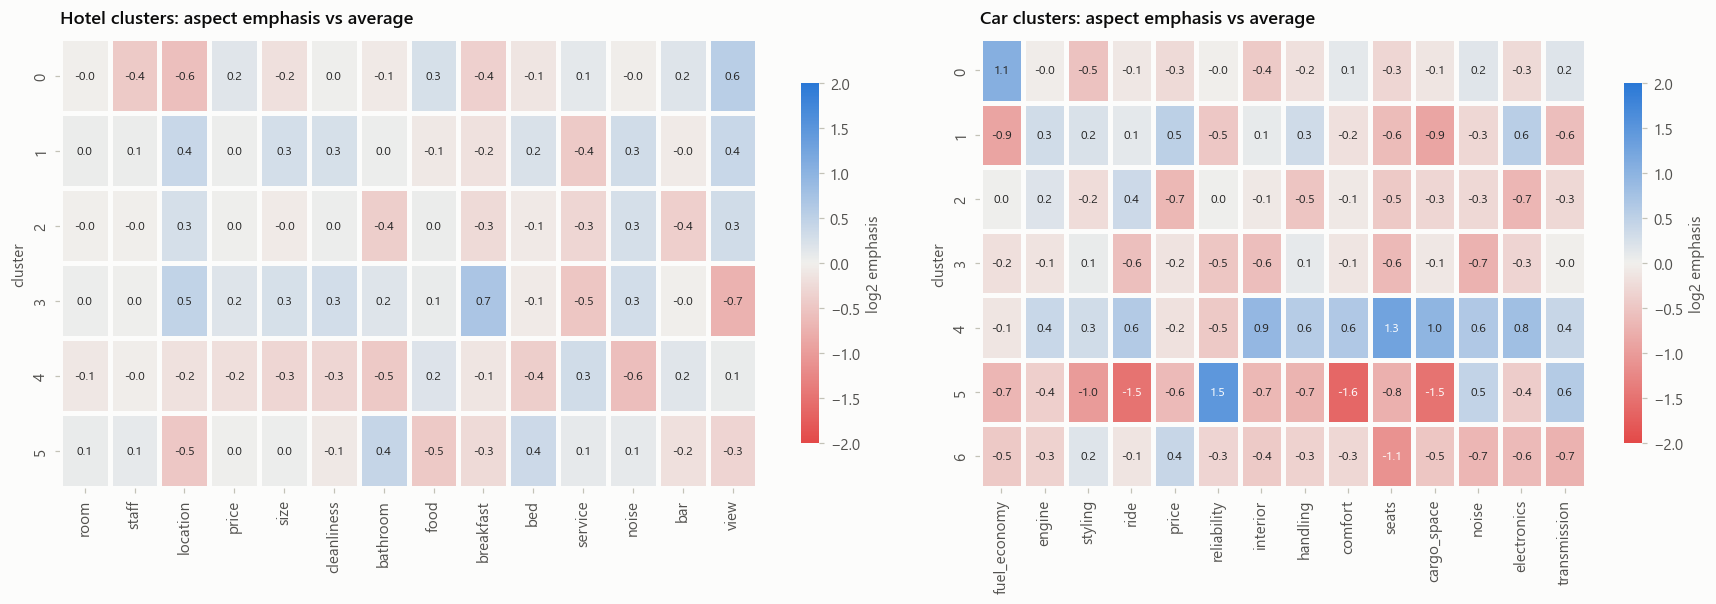

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
EMPH = {}
for ax, dom in zip(axs, ["hotel", "car"]):
    d = KM[dom]["d"]
    ex = d[["cluster", "aspects"]].explode("aspects").dropna().reset_index(drop=True)
    ct = pd.crosstab(ex["cluster"], ex["aspects"]).div(d["cluster"].value_counts().sort_index(), axis=0)
    overall = ex["aspects"].value_counts() / len(d)
    top_aspects = overall.index[:14]
    emph = np.log2(ct[top_aspects] / overall[top_aspects])
    EMPH[dom] = emph
    import seaborn as sns
    sns.heatmap(emph, cmap=P.DIVERGING, center=0, vmin=-2, vmax=2, annot=True, fmt=".1f", linewidths=2,
                linecolor=P.SURFACE, cbar_kws=dict(label="log2 emphasis", shrink=0.8), annot_kws=dict(fontsize=8), ax=ax)
    ax.set_title(f"{dom.title()} clusters: aspect emphasis vs average")
    ax.set_xlabel("")
    ax.set_ylabel("cluster")
fig.tight_layout()
P.save(fig, "k02_cluster_aspect_heatmap")
plt.show()

**Inferences (aspect emphasis)**
* The aspect profiles confirm the text-based labels. The London cluster over-mentions
  *breakfast* (+0.7) and *location*. The Las Vegas cluster talks about *view* (+0.6) and much less
  about *location* and *staff*. The complaint cluster over-mentions *bathroom* and *bed* (+0.4)
  and rarely praises *location* or *food*.
* Car cluster 5 is dominated by **reliability (+1.5, almost 3× average)**, transmission and
  noise, and almost never mentions comfort or ride (−1.5): a list of faults. Cluster 4 is the
  cabin cluster (seats +1.3, cargo space +1.0, interior +0.9).

### The clusters in 2-D (first two SVD components)
One panel per cluster: that cluster in colour over all points in grey. This is easier to read
than K overlapping colours.

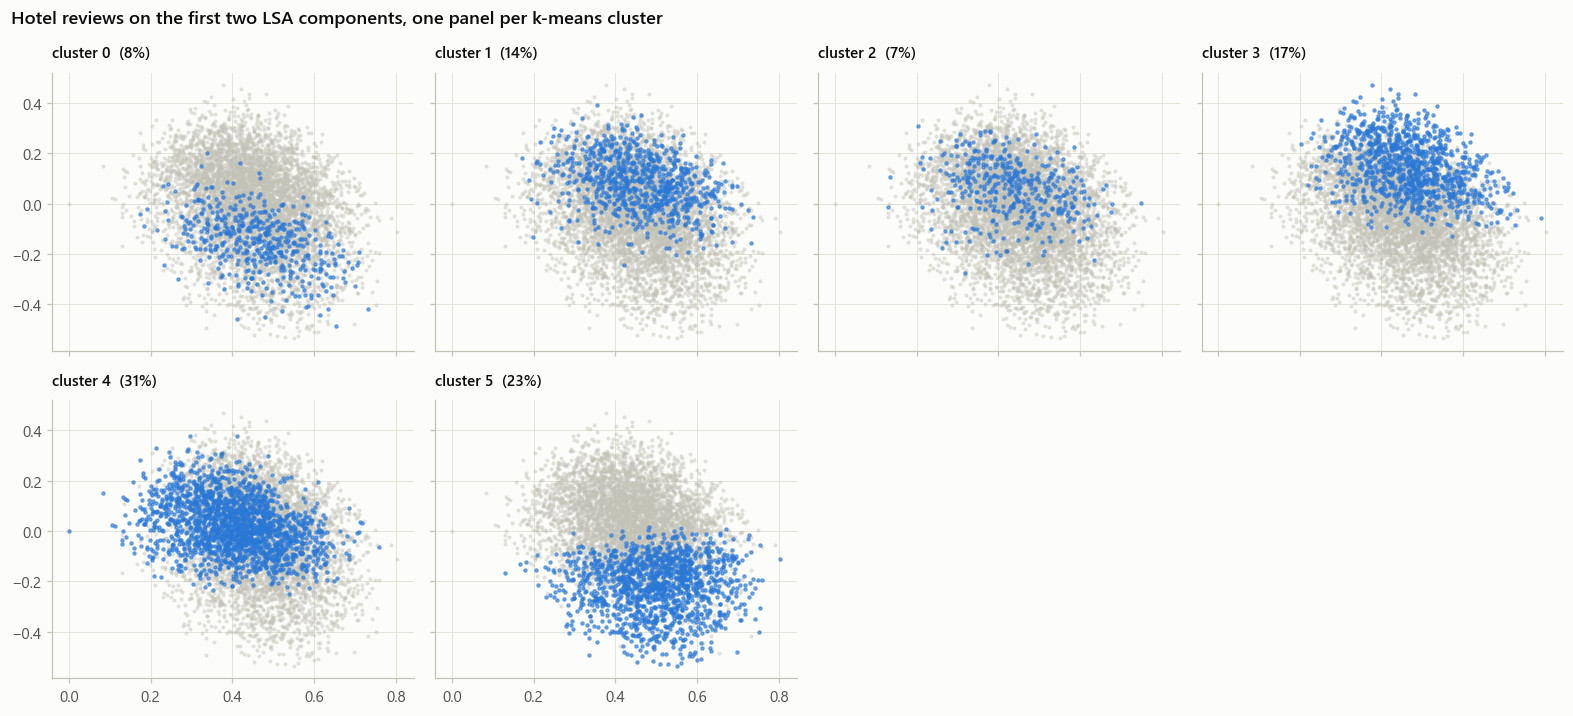

In [7]:
for dom in ["hotel"]:
    d, Z = KM[dom]["d"], REP[dom]["Z"]
    k = KM[dom]["metrics"]["K"]
    s = np.random.default_rng(SEED).choice(len(Z), 6000, replace=False)
    xy = Z[s, :2]
    ncol = min(k, 4)
    nrow = int(np.ceil(k / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.3 * nrow), sharex=True, sharey=True)
    for c, ax in zip(range(k), np.ravel(axs)):
        m = d["cluster"].values[s] == c
        ax.scatter(xy[~m, 0], xy[~m, 1], s=3, color=P.OTHER, alpha=0.35, rasterized=True)
        ax.scatter(xy[m, 0], xy[m, 1], s=4, color=P.DOMAIN[dom], alpha=0.6, rasterized=True)
        ax.set_title(f"cluster {c}  ({m.mean():.0%})", fontsize=10)
    for ax in np.ravel(axs)[k:]:
        ax.axis("off")
    fig.suptitle(f"{dom.title()} reviews on the first two LSA components, one panel per k-means cluster",
                 x=0.01, ha="left", fontsize=12, fontweight="semibold")
    fig.tight_layout()
    P.save(fig, "k03_cluster_svd_panels")
    plt.show()

## Hierarchical (agglomerative) clustering and the dendrogram
Agglomerative clustering with **Ward linkage** (merges the pair of clusters that least increases
the within-cluster SSE, so it is comparable with k-means). It runs on a **stratified sample of
300 hotel reviews** (equal share from every k-means cluster) because it needs the O(n²)
distance matrix. The **K-cluster lifetime** rule (the distance range over which
exactly K clusters exist) gives a second, independent opinion on K. The adjusted Rand index
(ARI) measures how well the dendrogram cut agrees with k-means on the same 300 reviews.

cophenetic correlation = 0.230; K-cluster lifetimes (longest = most natural K):
2     0.7712
3     0.4070
4     0.1307
5     0.2522
6     0.0550
7     0.1254
8     0.0452
9     0.0425
10    0.1445
11    0.0057
12    0.0477
longest lifetime at K = 2;  ARI(dendrogram cut at K=6, k-means) = 0.320
hierarchical   1   2   3   4   5   6
k-means                             
0             43   0   3   0   3   1
1              0   0   7  14  12  17
2              0  34   8   0   5   3
3              0   0   7   0  20  23
4              1   1   7   0  38   3
5              0   0  33   0  10   7


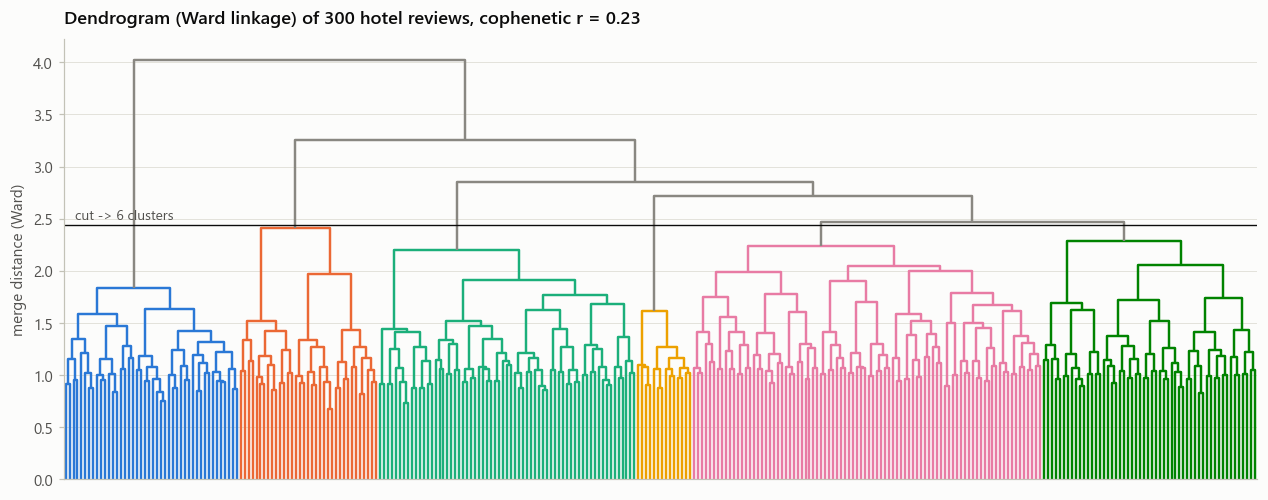

In [8]:
d, Z = KM["hotel"]["d"], REP["hotel"]["Z"]
k_hot = KM["hotel"]["metrics"]["K"]
per = 300 // k_hot
samp = np.concatenate([np.random.default_rng(SEED).choice(np.where(d["cluster"].values == c)[0], per, replace=False)
                       for c in range(k_hot)])
Zs = Z[samp].astype(np.float64)
L = linkage(Zs, method="ward")
coph, _ = cophenet(L, pdist(Zs))
heights = L[:, 2]
n = len(Zs)
life = pd.Series({K: heights[n - K] - heights[n - K - 1] for K in range(2, 13)}, name="lifetime")
hc = fcluster(L, t=k_hot, criterion="maxclust")
ari = adjusted_rand_score(d["cluster"].values[samp], hc)
print(f"cophenetic correlation = {coph:.3f}; K-cluster lifetimes (longest = most natural K):")
print(life.round(4).to_string())
print(f"longest lifetime at K = {life.idxmax()};  ARI(dendrogram cut at K={k_hot}, k-means) = {ari:.3f}")
print(pd.crosstab(pd.Series(d["cluster"].values[samp], name="k-means"), pd.Series(hc, name="hierarchical")))

fig, ax = plt.subplots(figsize=(14, 5.2))
cut = (heights[n - k_hot] + heights[n - k_hot - 1]) / 2
from scipy.cluster import hierarchy
hierarchy.set_link_color_palette(P.SERIES[:8])
dendrogram(L, ax=ax, no_labels=True, color_threshold=cut, above_threshold_color=P.MUTED)
ax.axhline(cut, color=P.INK, lw=0.9)
ax.annotate(f"cut -> {k_hot} clusters", xy=(0.01, cut), xycoords=("axes fraction", "data"), xytext=(0, 4),
            textcoords="offset points", fontsize=9, color=P.INK2)
ax.set_title(f"Dendrogram (Ward linkage) of 300 hotel reviews, cophenetic r = {coph:.2f}")
ax.set_ylabel("merge distance (Ward)")
ax.grid(axis="x", visible=False)
P.save(fig, "k04_dendrogram")
plt.show()

**Inferences (dendrogram)**
* The **first split of the tree isolates the Las Vegas reviews** (43 of the 50 sampled k-means
  cluster-0 reviews form one branch). Their casino and strip vocabulary makes them the most
  distinct group, so the K-cluster lifetime rule favours **K = 2** (lifetime 0.77). K = 6
  has a short lifetime: below the top split the structure is gradual, not sharp.
* The dendrogram cut at K = 6 agrees **moderately** with k-means (ARI = 0.32). Las Vegas,
  San Francisco, generic praise and complaints are each recovered by both methods (34–43 of
  50). New York and London are split differently, because their reviews share most of their
  vocabulary.
* The cophenetic correlation is low (0.23): a tree distorts distances in 100-dimensional text
  space. Hierarchical clustering is therefore useful here to *see* the merge structure on a
  sample, while k-means is the scalable method for all 218k reviews.

## Save the clustering outputs (and the LSA features for the PySpark comparison)

In [9]:
for dom in REP:
    KM[dom]["prof"].to_csv(TABLES / f"kmeans_profile_{dom}.csv")
    SEL[dom].to_csv(TABLES / f"kmeans_selection_{dom}.csv")
feat = pd.DataFrame({"features": list(REP["hotel"]["Z"].astype(np.float64))})
feat.to_parquet(CLEAN / "lsa_hotel.parquet", index=False)
print("saved LSA features:", feat.shape, "->", CLEAN / "lsa_hotel.parquet")
pd.DataFrame([KM[d]["metrics"] for d in KM], index=list(KM)).round(4)

saved LSA features: (218298, 1) -> C:\data\ASBD_exam\clean\lsa_hotel.parquet


,K,SSE,silhouette,davies_bouldin,calinski_harabasz,seconds
hotel,6,160112.5781,0.0300,4.9871,175.8827,18.4303
car,7,31980.6621,0.0261,5.2774,139.9477,9.3994


# Part 5 · Test-driving two techniques on PySpark: FP-Growth (association rules) and k-means

The question asks to run two of the predictive techniques on PySpark and **establish the
performance enhancement** that Spark's big-data support brings. This notebook measures it
rather than assuming it:

| Technique | Single-machine Python baselines | PySpark (MLlib) |
|---|---|---|
| Frequent itemsets + rules (hotel transactions, min_sup 5 %, min_conf 60 %) | `mlxtend.apriori` (classic Apriori on a pandas one-hot matrix); `algos.apriori_bitset` (our Apriori with vertical TID-bitsets, notebook 03) | `pyspark.ml.fpm.FPGrowth` (parallel FP-growth) |
| k-means (hotel LSA vectors, 100 dims, K from notebook 04, 20 iterations) | `sklearn.cluster.KMeans` (multi-threaded C, one initialisation) | `pyspark.ml.clustering.KMeans` (k-means‖ initialisation) |

**Data sizes.** Random samples of 25 % and 50 %, the full hotel data (218k reviews), and the
full data replicated 2×, 4× and 8× to simulate a growing dataset. Replication keeps every
support and the true clusters unchanged, so each run must return the same answer.

**Timing.** Only the mining step is timed. For Spark the data is first read from Parquet,
partitioned into 12 parts, cached and counted, the in-memory state the Python baselines also
start from. Spark's one-off start-up cost is reported separately.

**Machine.** One laptop: 12 logical cores, 7.7 GB RAM, Spark 3.5.3 in local mode on Java 11.

In [1]:
import gc
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import algos as A
import plots as P

warnings.filterwarnings("ignore")
P.set_style()
CLEAN = Path(r"C:\data\ASBD_exam\clean")
BENCH = CLEAN / "bench"
BENCH.mkdir(exist_ok=True)
TABLES = Path("../outputs/tables")
MIN_SUP, MIN_CONF = 0.05, 0.60
K = int(pd.read_csv(TABLES / "kmeans_selection_hotel.csv").query("knee")["K"].iloc[0])
print("k-means K (knee from notebook 04):", K)

model = pd.read_parquet(CLEAN / "reviews_model.parquet", columns=["domain", "aspects", "sent_class"])
model = model[model["domain"] == "hotel"].sample(frac=1, random_state=7)          # shuffled once
TX = [list(a) + [f"sent={s}"] for a, s in zip(model["aspects"], model["sent_class"])]
N = len(TX)
lsa = pd.read_parquet(CLEAN / "lsa_hotel.parquet")
LSA = np.vstack(lsa["features"].values)
LSA = LSA[np.random.default_rng(7).permutation(len(LSA))]
del model, lsa
gc.collect()
SIZES = {"25%": 0.25, "50%": 0.5, "100%": 1, "2x": 2, "4x": 4, "8x": 8}
KM_SIZES = ["25%", "50%", "100%", "2x"]          # dense 100-d vectors: 2x = 437k x 100 doubles


def tx_of(name):
    f = SIZES[name]
    return TX[:int(N * f)] if f <= 1 else TX * int(f)


def lsa_of(name):
    f = SIZES[name]
    return LSA[:int(len(LSA) * f)] if f <= 1 else np.tile(LSA, (int(f), 1))


for name in SIZES:                                   # write each size once for Spark to read
    pd.DataFrame({"items": tx_of(name)}).to_parquet(BENCH / f"tx_{name}.parquet", index=False)
for name in KM_SIZES:
    pd.DataFrame({"features": list(lsa_of(name))}).to_parquet(BENCH / f"lsa_{name}.parquet", index=False)
print(f"hotel transactions: {N:,}; LSA matrix: {LSA.shape}; benchmark inputs written to {BENCH}")

k-means K (knee from notebook 04): 6


hotel transactions: 218,298; LSA matrix: (218298, 100); benchmark inputs written to C:\data\ASBD_exam\clean\bench


## 1 · Single-machine Python baselines

In [2]:
from mlxtend.frequent_patterns import apriori as mx_apriori
from mlxtend.preprocessing import TransactionEncoder
from sklearn.cluster import KMeans

rows = []
for name in SIZES:
    t = tx_of(name)
    te = TransactionEncoder()
    X = pd.DataFrame(te.fit(t).transform(t), columns=te.columns_)
    t0 = time.time()
    fi = mx_apriori(X, min_support=MIN_SUP, use_colnames=True, low_memory=True)
    rows.append(dict(task="frequent itemsets", engine="Python: mlxtend Apriori", size=name, n=len(t),
                     seconds=time.time() - t0, result=len(fi)))
    del X, fi
    t0 = time.time()
    F = A.apriori_bitset(t, MIN_SUP)
    rows.append(dict(task="frequent itemsets", engine="Python: bitset Apriori (ours)", size=name, n=len(t),
                     seconds=time.time() - t0, result=len(F)))
    print(name, f"{len(t):,} tx:", {r["engine"]: (round(r["seconds"], 1), r["result"]) for r in rows[-2:]})
    del F
    gc.collect()
for name in KM_SIZES:
    Xk = lsa_of(name)
    t0 = time.time()
    km = KMeans(n_clusters=K, n_init=1, max_iter=20, random_state=42).fit(Xk)
    rows.append(dict(task="k-means", engine="Python: scikit-learn KMeans", size=name, n=len(Xk),
                     seconds=time.time() - t0, result=km.inertia_))
    print(name, f"{len(Xk):,} vectors: sklearn {rows[-1]['seconds']:.1f}s, SSE {km.inertia_:,.0f}")
    del Xk, km
    gc.collect()
py_results = pd.DataFrame(rows)

25% 54,574 tx: {'Python: mlxtend Apriori': (0.5, 2301), 'Python: bitset Apriori (ours)': (0.1, 2301)}


50% 109,149 tx: {'Python: mlxtend Apriori': (0.9, 2287), 'Python: bitset Apriori (ours)': (0.3, 2287)}


100% 218,298 tx: {'Python: mlxtend Apriori': (2.3, 2300), 'Python: bitset Apriori (ours)': (0.5, 2300)}


2x 436,596 tx: {'Python: mlxtend Apriori': (6.1, 2300), 'Python: bitset Apriori (ours)': (1.2, 2300)}


4x 873,192 tx: {'Python: mlxtend Apriori': (11.8, 2300), 'Python: bitset Apriori (ours)': (4.6, 2300)}


8x 1,746,384 tx: {'Python: mlxtend Apriori': (18.6, 2300), 'Python: bitset Apriori (ours)': (3.4, 2300)}


25% 54,574 vectors: sklearn 0.4s, SSE 40,087


50% 109,149 vectors: sklearn 0.5s, SSE 80,147


100% 218,298 vectors: sklearn 1.0s, SSE 160,336


2x 436,596 vectors: sklearn 2.6s, SSE 321,248


## 2 · PySpark (local mode, 12 cores)

In [3]:
from pyspark.ml.clustering import KMeans as SparkKMeans
from pyspark.ml.fpm import FPGrowth
from pyspark.ml.functions import array_to_vector
from pyspark.sql import SparkSession


def start_spark(cores):
    """local[cores, 4]: `cores` worker threads, failed tasks retried up to 4 times."""
    t0 = time.time()
    s = (SparkSession.builder.master(f"local[{cores},4]").appName(f"asbd-exam-{cores}")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", str(max(2, cores)))
         .config("spark.ui.enabled", "false")
         .getOrCreate())
    s.sparkContext.setLogLevel("ERROR")
    return s, time.time() - t0


def spark_fpgrowth(spark, name, parts):
    df = spark.read.parquet(str(BENCH / f"tx_{name}.parquet")).repartition(parts).cache()
    n = df.count()                                                   # materialise the cache
    t0 = time.time()
    m = FPGrowth(itemsCol="items", minSupport=MIN_SUP, minConfidence=MIN_CONF, numPartitions=parts).fit(df)
    n_fi = m.freqItemsets.count()
    n_rules = m.associationRules.count()
    sec = time.time() - t0
    df.unpersist()
    return n, sec, n_fi, n_rules, m


def spark_kmeans(spark, name, parts):
    df = (spark.read.parquet(str(BENCH / f"lsa_{name}.parquet"))
          .select(array_to_vector("features").alias("features")).repartition(parts).cache())
    n = df.count()
    t0 = time.time()
    m = SparkKMeans(k=K, maxIter=20, seed=42, initMode="k-means||").fit(df)
    sec = time.time() - t0
    cost = m.summary.trainingCost
    df.unpersist()
    return n, sec, cost


spark, t_start = start_spark(12)
print(f"Spark session start-up (one-off): {t_start:.1f}s")
rows = []
for name in SIZES:
    n, sec, n_fi, n_rules, m = spark_fpgrowth(spark, name, 12)
    rows.append(dict(task="frequent itemsets", engine="PySpark: FPGrowth", size=name, n=n, seconds=sec, result=n_fi))
    print(f"{name}: {n:,} tx  FPGrowth {sec:.1f}s  itemsets {n_fi}  rules {n_rules}")
top_rules = m.associationRules.orderBy("lift", ascending=False).limit(8).toPandas()
for name in KM_SIZES:
    n, sec, cost = spark_kmeans(spark, name, 12)
    rows.append(dict(task="k-means", engine="PySpark: KMeans", size=name, n=n, seconds=sec, result=cost))
    print(f"{name}: {n:,} vectors  KMeans {sec:.1f}s  SSE {cost:,.0f}")
spark_results = pd.DataFrame(rows)
print("\nSpark FPGrowth: top association rules by lift (8x data, same rules as notebook 03):")
top_rules.round(3)

Spark session start-up (one-off): 6.3s


25%: 54,574 tx  FPGrowth 13.4s  itemsets 2301  rules 5427


50%: 109,149 tx  FPGrowth 13.0s  itemsets 2287  rules 5382


100%: 218,298 tx  FPGrowth 18.4s  itemsets 2300  rules 5390


2x: 436,596 tx  FPGrowth 29.9s  itemsets 2300  rules 5390


4x: 873,192 tx  FPGrowth 44.9s  itemsets 2300  rules 5390


... (3 outputs left out)

50%: 109,149 vectors  KMeans 14.5s  SSE 80,097


100%: 218,298 vectors  KMeans 26.7s  SSE 160,114


2x: 436,596 vectors  KMeans 48.0s  SSE 320,590

Spark FPGrowth: top association rules by lift (8x data, same rules as notebook 03):


,antecedent,consequent,confidence,lift,support
0,"[bed, cleanliness, size, price, room]",[bathroom],0.753,1.846,0.052
1,"[bed, cleanliness, size, price]",[bathroom],0.752,1.844,0.052
2,"[bed, size, price, location, staff, room]",[bathroom],0.749,1.838,0.051
3,"[bed, size, price, location, staff]",[bathroom],0.748,1.834,0.051
4,"[bar, service, room]",[food],0.688,1.825,0.052
5,"[bed, size, price, staff, room]",[bathroom],0.741,1.817,0.067
6,"[bar, service]",[food],0.685,1.816,0.054
7,"[bed, size, price, staff, sent=pos, room]",[bathroom],0.740,1.816,0.059


## 3 · Correctness: every engine must find the same patterns

In [4]:
res = pd.concat([py_results, spark_results], ignore_index=True)
fi = res[res["task"] == "frequent itemsets"].pivot(index="size", columns="engine", values="result").loc[list(SIZES)]
print("number of frequent itemsets found (min_sup 5%):")
print(fi.to_string())
sse = res[res["task"] == "k-means"].pivot(index="size", columns="engine", values="result").loc[KM_SIZES]
sse["Spark / sklearn"] = sse["PySpark: KMeans"] / sse["Python: scikit-learn KMeans"]
print("\nk-means SSE (lower is better):")
print(sse.round(3).to_string())

number of frequent itemsets found (min_sup 5%):
engine  PySpark: FPGrowth  Python: bitset Apriori (ours)  Python: mlxtend Apriori
size                                                                             
25%                2301.0                         2301.0                   2301.0
50%                2287.0                         2287.0                   2287.0
100%               2300.0                         2300.0                   2300.0
2x                 2300.0                         2300.0                   2300.0
4x                 2300.0                         2300.0                   2300.0
8x                 2300.0                         2300.0                   2300.0

k-means SSE (lower is better):
engine  PySpark: KMeans  Python: scikit-learn KMeans  Spark / sklearn
size                                                                 
25%           40449.330                    40087.163            1.009
50%           80097.186                    80147.232  

**Inferences (correctness)**
* All three engines find **exactly the same number of frequent itemsets at every size** (2,300 on the
  full data, unchanged under replication as expected).
* Spark reports 5,390 rules against 8,631 in notebook 03. Spark MLlib only generates rules with a
  **single-item consequent**, and exactly 5,390 of our 8,631 rules have one, so the rule sets agree.
* Spark's k-means SSE is within **1 %** of scikit-learn's at every size: same clustering quality.

## 4 · Run time vs data size

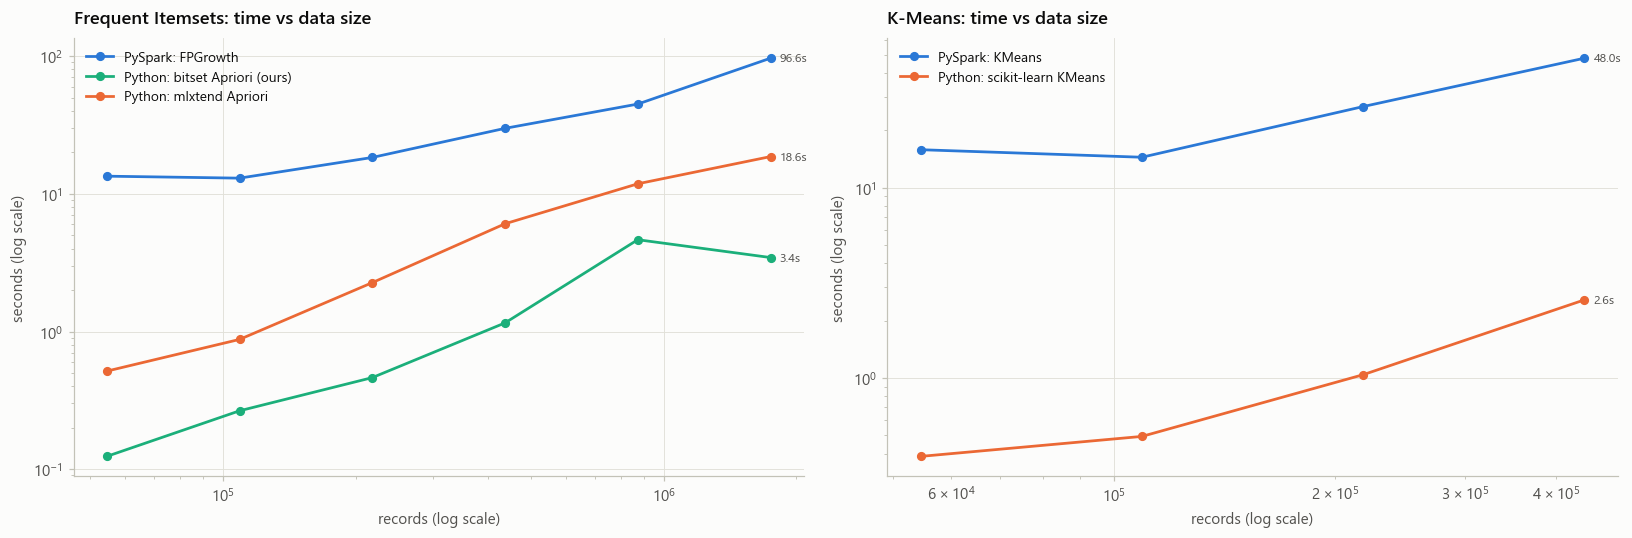

engine                  PySpark: FPGrowth  PySpark: KMeans  \
task              size                                       
frequent itemsets 100%              18.37              NaN   
                  25%               13.43              NaN   
                  2x                29.89              NaN   
                  4x                44.87              NaN   
                  50%               13.00              NaN   
                  8x                96.63              NaN   
k-means           100%                NaN            26.72   
                  25%                 NaN            15.85   
                  2x                  NaN            47.98   
                  50%                 NaN            14.47   

engine                  Python: bitset Apriori (ours)  \
task              size                                  
frequent itemsets 100%                           0.46   
                  25%                            0.12   
                  2x                             1.15   
                  4x                             4.64   
                  50%                            0.27   
                  8x                             3.44   
k-means           100%                            NaN   
                  25%                             NaN   
                  2x                              NaN   
                  50%                             NaN   

engine                  Python: mlxtend Apriori  Python: scikit-learn KMeans  
task              size                                                        
frequent itemsets 100%                     2.26                          NaN  
                  25%                      0.52                          NaN  
                  2x                       6.06                          NaN  
                  4x                      11.83                          NaN  
                  50%                      0.88                          NaN  
                  8x                      18.64                          NaN  
k-means           100%                      NaN                         1.04  
                  25%                       NaN                         0.39  
                  2x                        NaN                         2.57  
                  50%                       NaN                         0.49

In [5]:
tim = res.pivot_table(index=["task", "size"], columns="engine", values="seconds")
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
colors = {"Python: mlxtend Apriori": P.SERIES[1], "Python: bitset Apriori (ours)": P.SERIES[2],
          "PySpark: FPGrowth": P.SERIES[0], "Python: scikit-learn KMeans": P.SERIES[1], "PySpark: KMeans": P.SERIES[0]}
for ax, task, sizes in [(axs[0], "frequent itemsets", list(SIZES)), (axs[1], "k-means", KM_SIZES)]:
    sub = res[res["task"] == task]
    for eng, g in sub.groupby("engine"):
        g = g.set_index("size").loc[sizes]
        ax.plot(g["n"], g["seconds"], marker="o", ms=5, lw=1.8, color=colors[eng], label=eng)
        ax.annotate(f"{g['seconds'].iloc[-1]:.1f}s", xy=(g["n"].iloc[-1], g["seconds"].iloc[-1]), xytext=(6, 0),
                    textcoords="offset points", fontsize=8, color=P.INK2, va="center")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("records (log scale)")
    ax.set_ylabel("seconds (log scale)")
    ax.set_title(f"{task.title()}: time vs data size")
    ax.legend(loc="upper left")
fig.tight_layout()
P.save(fig, "x01_spark_vs_python_time")
plt.show()
tim.round(2)

**Inferences (run time vs data size)**
* On this laptop **Spark is the slowest engine at every size**:
  * FP-Growth takes 13–97 s, against 0.5–19 s for mlxtend's Apriori and 0.1–5 s for our bitset Apriori;
  * Spark KMeans takes 14–48 s, against 0.4–2.6 s for scikit-learn (18–40× slower).
* Spark has a **fixed overhead floor of ~13 s** per job, even for 55k transactions: task scheduling,
  serialisation, and the shuffles between FP-Growth's stages. The single-machine baselines have no such
  cost. They are compiled and vectorised (multi-threaded C in scikit-learn; one AND + popcount per support
  count in the bitset Apriori), and the data fits in RAM.
* Spark's time grows more slowly in *relative* terms. From 1× to 8× data, FP-Growth time grows 5.3×,
  against 8.2× for mlxtend and 7.5× for the bitset Apriori, because the fixed overhead is amortised. But
  its marginal cost (~11 s per extra 218k transactions) is still higher than mlxtend's (~2.3 s), so the
  curves do not cross on one machine.
* Timings on a shared laptop vary by roughly ±20 % (for example the bitset Apriori took 4.6 s at 4× but
  3.4 s at 8×). The trends are clear despite this.

## 5 · The parallel speed-up: same Spark job on 1, 4 and 12 cores
This isolates what Spark adds: the same code spreads the work across more cores (or, on a
cluster, more machines) with no change to the program. Run on the largest inputs.

 1 cores: FPGrowth(8x) 53.0s, KMeans(2x) 102.0s (session start 0.2s)


 4 cores: FPGrowth(8x) 54.4s, KMeans(2x) 37.7s (session start 0.3s)


12 cores: FPGrowth(8x) 110.2s, KMeans(2x) 33.8s (session start 0.3s)


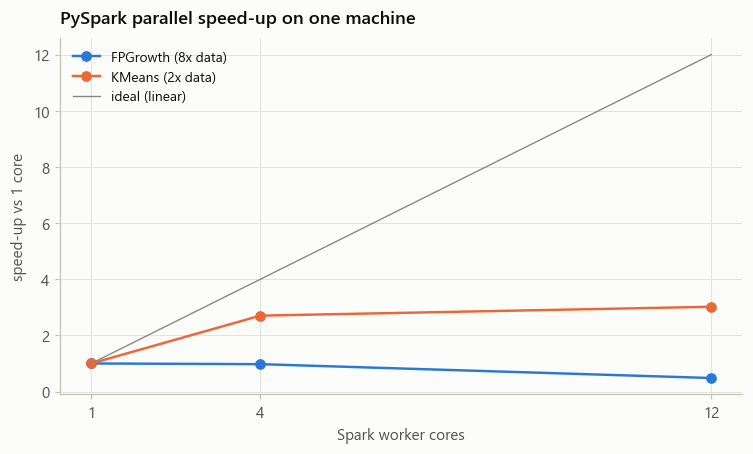

,fpgrowth_8x,kmeans_2x,startup,FPGrowth speed-up,KMeans speed-up
cores,,,,,
1,53.00,102.00,0.23,1.00,1.00
4,54.36,37.73,0.26,0.97,2.70
12,110.16,33.78,0.26,0.48,3.02


In [6]:
spark.stop()
scal = []
for cores in [1, 4, 12]:
    spark, ts = start_spark(cores)
    _, sec_fp, n_fi, _, _ = spark_fpgrowth(spark, "8x", cores if cores > 1 else 2)
    _, sec_km, _ = spark_kmeans(spark, "2x", cores if cores > 1 else 2)
    scal.append(dict(cores=cores, fpgrowth_8x=sec_fp, kmeans_2x=sec_km, startup=ts))
    print(f"{cores:>2} cores: FPGrowth(8x) {sec_fp:.1f}s, KMeans(2x) {sec_km:.1f}s (session start {ts:.1f}s)")
    spark.stop()
scal = pd.DataFrame(scal).set_index("cores")
scal["FPGrowth speed-up"] = scal.loc[1, "fpgrowth_8x"] / scal["fpgrowth_8x"]
scal["KMeans speed-up"] = scal.loc[1, "kmeans_2x"] / scal["kmeans_2x"]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(scal.index, scal["FPGrowth speed-up"], marker="o", color=P.SERIES[0], label="FPGrowth (8x data)")
ax.plot(scal.index, scal["KMeans speed-up"], marker="o", color=P.SERIES[1], label="KMeans (2x data)")
ax.plot([1, 12], [1, 12], color=P.MUTED, lw=0.9, label="ideal (linear)")
ax.set_xticks([1, 4, 12])
ax.set_xlabel("Spark worker cores")
ax.set_ylabel("speed-up vs 1 core")
ax.set_title("PySpark parallel speed-up on one machine")
ax.legend(loc="upper left")
P.save(fig, "x02_spark_speedup")
plt.show()
scal.round(2)

**Inferences (parallel speed-up)**
* **Spark KMeans parallelises:** 102 s on 1 core → 37.7 s on 4 cores (2.7×) → 33.8 s on 12 (3.0×), with
  no change to the code. The gain flattens beyond 4 cores because the 12 logical cores share 6 physical
  cores and one memory bus, and every iteration synchronises.
* **Spark FP-Growth does not** on this machine: 53 s (1 core) → 54 s (4) → 110 s (12). More partitions
  mean more conditional FP-trees to build and shuffle, and with under 1 GB of free RAM during the run,
  12 concurrent tasks caused memory pressure. Parallel FP-growth pays off when partitions run on separate
  machines with their own memory, not as threads competing on one laptop.

## Conclusion: what Spark's big-data support adds
* **On one machine, with data that fits in memory, Spark does not make these techniques faster.** The
  compiled single-machine libraries win by 5–40×. Using Spark for 0.2–1.75 M reviews on a laptop is
  overhead without benefit.
* The enhancement Spark delivers is **scalability, not speed at this size:**
  1. the same program ran unchanged from 55k to 1.75 M records within a fixed 2 GB driver heap, with
     run time growing roughly linearly;
  2. it parallelises with no code changes (k-means 3× faster on 12 cores);
  3. it partitions the data, so it does not need the data, or the intermediate candidate tables, to fit
     in one machine's memory. mlxtend's default (vectorised) Apriori builds a rows × candidates boolean
     table per level: at 8× data that is billions of cells (several GB), which is why its low-memory mode
     had to be used here. Spark spreads such work across partitions and, on a cluster, across machines.
* Spark's advantage therefore appears once the data outgrows a single machine (memory or disk), which is
  the regime "big data support" refers to. At OpinRank's size a well-written single-machine
  implementation is the right tool, and the measurements show it.

In [7]:
res.to_csv(TABLES / "spark_benchmark.csv", index=False)
scal.to_csv(TABLES / "spark_scaling.csv")
summary = tim.copy()
summary.columns = [c.replace("Python: ", "").replace("PySpark: ", "Spark ") for c in summary.columns]
summary.round(2)

Spark FPGrowth  Spark KMeans  bitset Apriori (ours)  \
task              size                                                        
frequent itemsets 100%           18.37           NaN                   0.46   
                  25%            13.43           NaN                   0.12   
                  2x             29.89           NaN                   1.15   
                  4x             44.87           NaN                   4.64   
                  50%            13.00           NaN                   0.27   
                  8x             96.63           NaN                   3.44   
k-means           100%             NaN         26.72                    NaN   
                  25%              NaN         15.85                    NaN   
                  2x               NaN         47.98                    NaN   
                  50%              NaN         14.47                    NaN   

                        mlxtend Apriori  scikit-learn KMeans  
task              size                                        
frequent itemsets 100%             2.26                  NaN  
                  25%              0.52                  NaN  
                  2x               6.06                  NaN  
                  4x              11.83                  NaN  
                  50%              0.88                  NaN  
                  8x              18.64                  NaN  
k-means           100%              NaN                 1.04  
                  25%               NaN                 0.39  
                  2x                NaN                 2.57  
                  50%               NaN                 0.49